# 1. Project Overview

This project analyses customer feedback across Kestrel Motor Group dealerships to identify the main drivers of negative feedback, investigate changes over time, compare dealership and department performance, and recommend practical improvements.

The analysis also explores how a locally run AI model can assist with feedback analysis, while checking its outputs against the original comments.

**Reproducibility and privacy note:** Place the supplied `PS_Data_AI_Assignment.zip` in the notebook folder or your Downloads folder before running the notebook. Saved cell outputs have been cleared from this submission copy to avoid embedding customer-level source details. The analysis should be rerun in an approved environment with the source files available. Automated privacy screening is limited and does not guarantee complete anonymisation.


## Submission notes and reproducibility

**Current analysis snapshot:** 7,086 consolidated records; 6,489 records in numeric-rating analysis after excluding Kestrel Ringwood (inconsistent rating standardisation) and Kestrel Tamworth (no usable numeric ratings). The monthly trend covers October 2025–September 2026 and contains 6,473 valid ratings because 10 records have missing/unparseable dates and six valid-rated records fall outside the reporting window; three are dated after 28 October 2026 and should be checked as possible date errors.

**Sentiment limitation:** the notebook's VADER baseline agreed with manual labels on 18 of 30 sampled comments (60% overall) and 5 of 13 manually labelled negative comments (38.5%). This is a small spot-check, not a robust accuracy estimate; VADER labels should not be presented as reliable findings without further validation.

**Data quality:** 47 exact duplicate rows were retained. Three labels were not matched reliably to revenue data: `Unmapped - KMG-IPS`, `Unmapped - HUNTER`, and `Unmapped - North Queensland`. Theme tags overlap. Privacy screening is pattern-based and does not prove complete anonymisation.

**Setup:** place `PS_Data_AI_Assignment.zip` in the notebook folder or Downloads folder. The analysis uses pandas, matplotlib, scikit-learn, and `vaderSentiment`. The AI experiment additionally requires Ollama to be running locally with `qwen2.5:3b` available.

**Execution status:** all cells were run in order. For privacy, saved outputs of cells that display raw or customer-level data have been cleared; analysis, validation and chart outputs are retained. Re-run from the top to regenerate everything

In [ ]:
import os
import re
import ast
import json
import random
import zipfile

import pandas as pd
import matplotlib.pyplot as plt

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.metrics import classification_report, confusion_matrix

import matplotlib.ticker as mticker
import ollama

from IPython.display import display as _display_original

def display(obj, *args, **kwargs):
    """Avoid displaying raw customer-level free text in notebook outputs."""
    if isinstance(obj, pd.DataFrame):
        sensitive_columns = [
            col for col in obj.columns
            if str(col).strip().casefold() in {
                "comment", "customer feedback", "feedback", "review",
                "notes", "verbatim", "what did they say?"
            }
        ]
        if sensitive_columns:
            obj = obj.drop(columns=sensitive_columns, errors="ignore")
    return _display_original(obj, *args, **kwargs)


In [2]:

print("Pandas version:", pd.__version__)
print("Current folder:", os.getcwd())

Pandas version: 3.0.3
Current folder: C:\Users\mufra


# 2. Data Loading and Consolidation


In [3]:
from pathlib import Path

# Locate the supplied assignment ZIP without relying on a user-specific Windows path.
zip_candidates = [
    Path.cwd() / "PS_Data_AI_Assignment.zip",
    Path.home() / "Downloads" / "PS_Data_AI_Assignment.zip",
]
zip_path = next((path for path in zip_candidates if path.exists()), None)
if zip_path is None:
    raise FileNotFoundError(
        "Place PS_Data_AI_Assignment.zip in the notebook folder or your Downloads folder, then rerun this cell."
    )

extract_folder = Path.cwd() / "Kestrel_Assignment"
extract_folder.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

extract_folder = str(extract_folder)
print("Assignment extracted successfully.")
print("Files are saved in:", extract_folder)


Assignment extracted successfully.
Files are saved in: C:\Users\mufra\Kestrel_Assignment


In [4]:
for folder, subfolders, files in os.walk(extract_folder):
    print(f"\nFolder: {folder}")
    for file in files[:10]:
        print(" -", file)


Folder: C:\Users\mufra\Kestrel_Assignment
 - consolidated_feedback.csv
 - kestrel_customer_feedback_clean_final.csv
 - kestrel_customer_feedback_privacy_working.csv
 - PS_Data_AI_Assignment.pdf
 - README.md

Folder: C:\Users\mufra\Kestrel_Assignment\feedback
 - Ballarat - Customer Satisfaction.xlsx
 - bendigo feedback.csv
 - boxhill_survey_export_2025Q4.csv
 - boxhill_survey_export_2026Q1.csv
 - boxhill_survey_export_2026Q2.csv
 - boxhill_survey_export_2026Q3.csv
 - chatswood_2025_q4.csv
 - chatswood_2026_q1.csv
 - chatswood_2026_q2.csv
 - chatswood_2026_q3.csv

Folder: C:\Users\mufra\Kestrel_Assignment\reference
 - dealerships.csv
 - monthly_revenue.csv


In [5]:
readme_path = os.path.join(extract_folder, "README.md")

with open(readme_path, "r", encoding="utf-8") as file:
    instructions = file.read()

print(instructions)

Kestrel Motor Group: Data & AI Challenge
The Kestrel Motor Group is an Australian dealership group consisting of 24 dealerships across Victoria, New South Wales and Queensland, selling and servicing several vehicle brands. Each dealership collects customer feedback from sales, service and parts customers and sends it to head office.

The Problem
-----------
Some dealerships send a new file each month or quarter; others keep one running workbook and send that.

Nobody ever agreed on a template. Each site's spreadsheet has evolved over the years, built by whoever happened to own it at the time. Head office has a folder full of these files and cannot answer simple questions about their customers' experience and dealership performance.

The Head of Customer Experience has asked you to help!

Your task
---------
1. **Bring it together.** Consolidate the feedback into a single, clean dataset. Decide what it should look like, and explain why.
2. **Decide what you can trust.** Define data qual

In [6]:

# Locate the official dealership list
dealership_path = os.path.join(
    extract_folder,
    "reference",
    "dealerships.csv"
)

# Load the CSV into a Pandas DataFrame
dealerships = pd.read_csv(dealership_path)

# Display the first five rows
display(dealerships.head())

,dealer_code,dealership_name,suburb,state,region,brands,status,closed_date
0,VIC01,Kestrel Dandenong,Dandenong,VIC,VIC Metro,Altura|Kodiak,Open,NaN
1,VIC02,Kestrel Ringwood,Ringwood,VIC,VIC Metro,Altura|Veyra,Open,NaN
2,VIC03,Kestrel Essendon,Essendon,VIC,VIC Metro,Altura,Open,NaN
3,VIC04,Kestrel Frankston,Frankston,VIC,VIC Metro,Altura|Kodiak,Open,NaN
4,VIC05,Kestrel Box Hill,Box Hill,VIC,VIC Metro,Veyra|Voltra,Open,NaN


In [7]:
print("Number of rows and columns:", dealerships.shape)

print("\nColumn names:")
print(dealerships.columns.tolist())

print("\nMissing values in each column:")
print(dealerships.isna().sum())

Number of rows and columns: (24, 8)

Column names:
['dealer_code', 'dealership_name', 'suburb', 'state', 'region', 'brands', 'status', 'closed_date']

Missing values in each column:
dealer_code         0
dealership_name     0
suburb              0
state               0
region              0
brands              0
status              0
closed_date        23
dtype: int64


In [8]:
print("Shape:", dealerships.shape)

print("\nActual column names:")
print(dealerships.columns.tolist())

print("\nData types:")
print(dealerships.dtypes)

print("\nFirst row as a dictionary:")
print(dealerships.iloc[0].to_dict())

Shape: (24, 8)

Actual column names:
['dealer_code', 'dealership_name', 'suburb', 'state', 'region', 'brands', 'status', 'closed_date']

Data types:
dealer_code        str
dealership_name    str
suburb             str
state              str
region             str
brands             str
status             str
closed_date        str
dtype: object

First row as a dictionary:
{'dealer_code': 'VIC01', 'dealership_name': 'Kestrel Dandenong', 'suburb': 'Dandenong', 'state': 'VIC', 'region': 'VIC Metro', 'brands': 'Altura|Kodiak', 'status': 'Open', 'closed_date': nan}


In [9]:
print("Duplicate dealership codes:",
      dealerships["dealer_code"].duplicated().sum())

print("\nDealership status counts:")
print(dealerships["status"].value_counts(dropna=False))

print("\nStatus versus missing closure dates:")
print(pd.crosstab(
    dealerships["status"],
    dealerships["closed_date"].isna(),
    margins=True
))

Duplicate dealership codes: 0

Dealership status counts:
status
Open      23
Closed     1
Name: count, dtype: int64

Status versus missing closure dates:
closed_date  False  True  All
status                       
Closed           1     0    1
Open             0    23   23
All              1    23   24


In [10]:
revenue_path = os.path.join(
    extract_folder, "reference", "monthly_revenue.csv"
)

revenue = pd.read_csv(revenue_path)

print("Dataset size:", revenue.shape)

print("\nColumn names:")
print(revenue.columns.tolist())

print("\nFirst five rows:")
display(revenue.head())

Dataset size: (288, 8)

Column names:
['dealer_code', 'month', 'vehicles_sold', 'sales_revenue_aud', 'service_jobs', 'service_revenue_aud', 'parts_transactions', 'parts_revenue_aud']

First five rows:


,dealer_code,month,vehicles_sold,sales_revenue_aud,service_jobs,service_revenue_aud,parts_transactions,parts_revenue_aud
0,VIC01,2025-10,94,4324300.0,1024,418720.0,315,59410.0
1,VIC01,2025-11,92,4242100.0,1012,432770.0,343,63950.0
2,VIC01,2025-12,106,5018100.0,915,381770.0,288,51920.0
3,VIC01,2026-01,73,3410600.0,916,381110.0,294,53440.0
4,VIC01,2026-02,82,3752900.0,1097,461870.0,342,64990.0


In [11]:
print("Missing values in each column:")
print(revenue.isna().sum())

print("\nDuplicate dealership-month records:")
print(revenue.duplicated(
    subset=["dealer_code", "month"]
).sum())

print("\nNegative values in numeric columns:")
numeric_columns = [
    "vehicles_sold",
    "sales_revenue_aud",
    "service_jobs",
    "service_revenue_aud",
    "parts_transactions",
    "parts_revenue_aud"
]

print((revenue[numeric_columns] < 0).sum())

print("\nUnique dealerships:", revenue["dealer_code"].nunique())
print("Unique months:", revenue["month"].nunique())

Missing values in each column:
dealer_code            0
month                  0
vehicles_sold          0
sales_revenue_aud      0
service_jobs           0
service_revenue_aud    0
parts_transactions     0
parts_revenue_aud      0
dtype: int64

Duplicate dealership-month records:
0

Negative values in numeric columns:
vehicles_sold          0
sales_revenue_aud      0
service_jobs           0
service_revenue_aud    0
parts_transactions     0
parts_revenue_aud      0
dtype: int64

Unique dealerships: 24
Unique months: 12


In [ ]:
print("Records per dealership:")
print(revenue.groupby("dealer_code")["month"].nunique().value_counts())

print("\nRecords per month:")
print(revenue.groupby("month")["dealer_code"].nunique())

print("\nExpected total records:", 24 * 12)
print("Actual total records:", len(revenue))

In [13]:

feedback_folder = os.path.join(extract_folder, "feedback")

excel_files = []

for folder, subfolders, files in os.walk(feedback_folder):
    for file in files:
        if file.lower().endswith(".xlsx"):
            excel_files.append(os.path.join(folder, file))

print("Number of Excel files:", len(excel_files))

for file_path in excel_files:
    workbook = pd.ExcelFile(file_path)

    print(f"\nFile: {os.path.basename(file_path)}")
    print("Worksheets:", workbook.sheet_names)

Number of Excel files: 37

File: Ballarat - Customer Satisfaction.xlsx
Worksheets: ['Responses']

File: Chermside Q1 2026 FINAL v2.xlsx
Worksheets: ['Feedback']

File: Chermside Q1 2026 FINAL.xlsx
Worksheets: ['Feedback']

File: Chermside Q2 2026.xlsx
Worksheets: ['Feedback']

File: Chermside Q3 2026.xlsx
Worksheets: ['Feedback']

File: Chermside Q4 2025.xlsx
Worksheets: ['Feedback']

File: Dandenong Customer Feedback 2025-26.xlsx
Worksheets: ['Oct 25', 'Nov 25', 'Dec 25', 'Jan 26', 'Feb 26', 'Mar 26', 'Apr 26', 'May 26', 'Jun 26', 'Jul 26', 'Aug 26', 'Sep 26', 'Sheet3']

File: ESSENDON - feedback register.xlsx
Worksheets: ['Sales', 'Service', 'Parts']

File: Frankston_CX_tracker.xlsx
Worksheets: ['Tracker']

File: Geelong Feedback.xlsx
Worksheets: ['2025', '2026']

File: Hunter Motors feedback 25-26.xlsx
Worksheets: ['Feedback']

File: IPS_feedback_log.xlsx
Worksheets: ['Log']

File: Noosa feedback cards.xlsx
Worksheets: ['Cards']

File: North QLD feedback (Rocky + TSV).xlsx
Worksheet

In [ ]:
sample_files = [
    "Dandenong Customer Feedback 2025-26.xlsx",
    "ESSENDON - feedback register.xlsx",
    "Geelong Feedback.xlsx",
    "Southport Feedback Tracker.xlsx"
]

for filename in sample_files:
    file_path = os.path.join(feedback_folder, filename)

    print("\n" + "=" * 60)
    print("WORKBOOK:", filename)

    workbook = pd.ExcelFile(file_path)

    for sheet_name in workbook.sheet_names:
        print("\nSHEET:", sheet_name)

        df = pd.read_excel(
            file_path,
            sheet_name=sheet_name,
            nrows=5
        )

        print("Columns:", df.columns.tolist())
        display(df.head(3))

In [ ]:
# Dandenong: inspect the introductory rows
dandenong_path = os.path.join(
    feedback_folder,
    "Dandenong Customer Feedback 2025-26.xlsx"
)

print("DANDENONG — OCTOBER SHEET")
dandenong_raw = pd.read_excel(
    dandenong_path,
    sheet_name="Oct 25",
    header=None,
    nrows=3
)
display(dandenong_raw)

# Geelong: inspect the introductory rows in both years
geelong_path = os.path.join(
    feedback_folder,
    "Geelong Feedback.xlsx"
)

for sheet in ["2025", "2026"]:
    print(f"\nGEELONG — {sheet} SHEET")

    geelong_raw = pd.read_excel(
        geelong_path,
        sheet_name=sheet,
        header=None,
        nrows=3
    )

    display(geelong_raw)

# Southport: inspect the title and header rows only
southport_path = os.path.join(
    feedback_folder,
    "Southport Feedback Tracker.xlsx"
)

print("\nSOUTHPORT — GOOGLE REVIEWS")
google_raw = pd.read_excel(
    southport_path,
    sheet_name="Google reviews (copied)",
    header=None,
    nrows=2
)
display(google_raw)

In [ ]:
# Check Dandenong: first 6 rows
print("DANDENONG")
display(pd.read_excel(
    dandenong_path,
    sheet_name="Oct 25",
    header=None,
    nrows=6
))

# Check Geelong: first 6 rows of both years
for sheet in ["2025", "2026"]:
    print(f"\nGEELONG {sheet}")
    display(pd.read_excel(
        geelong_path,
        sheet_name=sheet,
        header=None,
        nrows=6
    ))

# Check Southport Google reviews: first 4 rows
print("\nSOUTHPORT GOOGLE REVIEWS")
display(pd.read_excel(
    southport_path,
    sheet_name="Google reviews (copied)",
    header=None,
    nrows=4
))

In [ ]:
# Read Dandenong's October feedback using the correct header row
dandenong_oct = pd.read_excel(
    dandenong_path,
    sheet_name="Oct 25",
    header=3
)

# Remove completely empty rows
dandenong_oct = dandenong_oct.dropna(how="all")

# Display the column names
print("Column names:")
print(dandenong_oct.columns.tolist())

# Display the first five rows
display(dandenong_oct.head())

# Check the dataset size
print("Rows and columns:", dandenong_oct.shape)



In [ ]:
# 1. Check the number of missing values in each column
print("Missing values per column:")
print(dandenong_oct.isna().sum())

# 2. Check for completely duplicated rows
print("\nCompletely duplicated rows:")
print(dandenong_oct.duplicated().sum())

# 3. Check the rating values
print("\nRating counts:")
print(dandenong_oct["Rating (1-5)"].value_counts(dropna=False).sort_index())

# 4. Check the date range
print("\nDate range:")
print("Earliest date:", dandenong_oct["Date"].min())
print("Latest date:", dandenong_oct["Date"].max())



In [19]:
# Check whether ratings are between 1 and 5
valid_ratings = dandenong_oct["Rating (1-5)"].between(1, 5)

print("Invalid ratings:", (~valid_ratings).sum())

# Check whether any dates are missing
print("Missing dates:", dandenong_oct["Date"].isna().sum())

# Check the departments recorded
print("\nDepartment counts:")
print(dandenong_oct["Dept"].value_counts(dropna=False))

# Check whether comments are blank or missing
comments = dandenong_oct["Comments"].fillna("").str.strip()

print("\nBlank or missing comments:", (comments == "").sum())



Invalid ratings: 0
Missing dates: 0

Department counts:
Dept
Service    27
Sales      13
Parts       1
Name: count, dtype: int64

Blank or missing comments: 9


In [ ]:

# Read the first few rows of the Dandenong October sheet
display(pd.read_excel(
    dandenong_path,
    sheet_name="Oct 25",
    header=None,
    nrows=4
))



In [21]:

readme_path = os.path.join(
    extract_folder,
    "README.md"
)

with open(readme_path, "r", encoding="utf-8") as file:
    print(file.read())



Kestrel Motor Group: Data & AI Challenge
The Kestrel Motor Group is an Australian dealership group consisting of 24 dealerships across Victoria, New South Wales and Queensland, selling and servicing several vehicle brands. Each dealership collects customer feedback from sales, service and parts customers and sends it to head office.

The Problem
-----------
Some dealerships send a new file each month or quarter; others keep one running workbook and send that.

Nobody ever agreed on a template. Each site's spreadsheet has evolved over the years, built by whoever happened to own it at the time. Head office has a folder full of these files and cannot answer simple questions about their customers' experience and dealership performance.

The Head of Customer Experience has asked you to help!

Your task
---------
1. **Bring it together.** Consolidate the feedback into a single, clean dataset. Decide what it should look like, and explain why.
2. **Decide what you can trust.** Define data qual

In [22]:

# Find all CSV files in the feedback folder
csv_files = []

for folder, subfolders, files in os.walk(feedback_folder):
    for file in files:
        if file.lower().endswith(".csv"):
            csv_files.append(os.path.join(folder, file))

print("Number of CSV files:", len(csv_files))

# Show the column names from the first five CSV files
for file_path in csv_files[:5]:
    print("\nFile:", os.path.basename(file_path))

    try:
        sample = pd.read_csv(file_path, nrows=3)
        print("Columns:", sample.columns.tolist())
        print("Sample size:", sample.shape)
    except Exception as error:
        print("Could not read this file:", error)



Number of CSV files: 15

File: bendigo feedback.csv
Columns: ['Date', 'Dept', 'Stars', 'What did they say?']
Sample size: (3, 4)

File: boxhill_survey_export_2025Q4.csv
Columns: ['response_id', 'submitted_at', 'department', 'csat', 'verbatim', 'vehicle', 'dms_customer_no']
Sample size: (3, 7)

File: boxhill_survey_export_2026Q1.csv
Columns: ['response_id', 'submitted_at', 'department', 'csat', 'verbatim', 'vehicle', 'dms_customer_no']
Sample size: (3, 7)

File: boxhill_survey_export_2026Q2.csv
Columns: ['response_id', 'submitted_at', 'department', 'csat', 'verbatim', 'vehicle', 'dms_customer_no']
Sample size: (3, 7)

File: boxhill_survey_export_2026Q3.csv
Columns: ['response_id', 'submitted_at', 'department', 'csat', 'verbatim', 'vehicle', 'dms_customer_no']
Sample size: (3, 7)


In [23]:

for file_path in csv_files:
    try:
        sample = pd.read_csv(file_path, nrows=0)

        print(
            os.path.basename(file_path),
            "->",
            sample.columns.tolist()
        )

    except Exception as error:
        print(os.path.basename(file_path), "-> Could not read:", error)



bendigo feedback.csv -> ['Date', 'Dept', 'Stars', 'What did they say?']
boxhill_survey_export_2025Q4.csv -> ['response_id', 'submitted_at', 'department', 'csat', 'verbatim', 'vehicle', 'dms_customer_no']
boxhill_survey_export_2026Q1.csv -> ['response_id', 'submitted_at', 'department', 'csat', 'verbatim', 'vehicle', 'dms_customer_no']
boxhill_survey_export_2026Q2.csv -> ['response_id', 'submitted_at', 'department', 'csat', 'verbatim', 'vehicle', 'dms_customer_no']
boxhill_survey_export_2026Q3.csv -> ['response_id', 'submitted_at', 'department', 'csat', 'verbatim', 'vehicle', 'dms_customer_no']
chatswood_2025_q4.csv -> ['Date;Dept;Score;Comment;Vehicle']
chatswood_2026_q1.csv -> ['Date;Dept;Score;Comment;Vehicle']
chatswood_2026_q2.csv -> ['Date;Dept;Score;Comment;Vehicle']
chatswood_2026_q3.csv -> ['Date;Dept;Score;Comment;Vehicle']
liverpool_q1_2026.csv -> ['Date', 'Department', 'Customer', 'Phone', 'Rego', 'Rating', 'Feedback']
liverpool_q2_2026.csv -> ['Date', 'Department', 'Customer

In [24]:

# Test 1: Read Chatswood using a semicolon separator
chatswood_path = os.path.join(
    feedback_folder,
    "chatswood_2025_q4.csv"
)

chatswood = pd.read_csv(
    chatswood_path,
    sep=";"
)

print("CHATSWOOD")
print("Columns:", chatswood.columns.tolist())
print("Dataset size:", chatswood.shape)


# Test 2: Read Wollongong using Windows-1252 encoding
wollongong_path = os.path.join(
    feedback_folder,
    "Wollongong_Oct25-Mar26.csv"
)

wollongong = pd.read_csv(
    wollongong_path,
    encoding="cp1252"
)

print("\nWOLLONGONG")
print("Columns:", wollongong.columns.tolist())
print("Dataset size:", wollongong.shape)



CHATSWOOD
Columns: ['Date', 'Dept', 'Score', 'Comment', 'Vehicle']
Dataset size: (68, 5)

WOLLONGONG
Columns: ['Date', 'Dept', 'Rating', 'Customer feedback', 'Name', 'Mobile']
Dataset size: (138, 6)


In [25]:

# Display the official dealership names and codes
display(
    dealerships[["dealer_code", "dealership_name", "status"]]
    .sort_values("dealership_name")
    .reset_index(drop=True)
)



,dealer_code,dealership_name,status
0,VIC07,Kestrel Ballarat,Open
1,VIC08,Kestrel Bendigo,Open
2,VIC05,Kestrel Box Hill,Open
3,NSW03,Kestrel Chatswood,Open
4,QLD01,Kestrel Chermside,Open
5,VIC01,Kestrel Dandenong,Open
6,VIC03,Kestrel Essendon,Open
7,VIC04,Kestrel Frankston,Open
8,VIC06,Kestrel Geelong,Open
9,QLD03,Kestrel Ipswich,Open


In [26]:

# Create a simple inventory of the CSV feedback files
csv_inventory = pd.DataFrame({
    "file_name": [os.path.basename(path) for path in csv_files],
    "full_path": csv_files
})

display(csv_inventory)



,file_name,full_path
0,bendigo feedback.csv,C:\Users\mufra\Kestrel_Assignment\feedback\ben...
1,boxhill_survey_export_2025Q4.csv,C:\Users\mufra\Kestrel_Assignment\feedback\box...
2,boxhill_survey_export_2026Q1.csv,C:\Users\mufra\Kestrel_Assignment\feedback\box...
3,boxhill_survey_export_2026Q2.csv,C:\Users\mufra\Kestrel_Assignment\feedback\box...
4,boxhill_survey_export_2026Q3.csv,C:\Users\mufra\Kestrel_Assignment\feedback\box...
5,chatswood_2025_q4.csv,C:\Users\mufra\Kestrel_Assignment\feedback\cha...
6,chatswood_2026_q1.csv,C:\Users\mufra\Kestrel_Assignment\feedback\cha...
7,chatswood_2026_q2.csv,C:\Users\mufra\Kestrel_Assignment\feedback\cha...
8,chatswood_2026_q3.csv,C:\Users\mufra\Kestrel_Assignment\feedback\cha...
9,liverpool_q1_2026.csv,C:\Users\mufra\Kestrel_Assignment\feedback\liv...


In [27]:
# Map each CSV file to its dealership
csv_dealerships = {
    "bendigo feedback.csv": "Kestrel Bendigo",
    "boxhill_survey_export_2025Q4.csv": "Kestrel Box Hill",
    "boxhill_survey_export_2026Q1.csv": "Kestrel Box Hill",
    "boxhill_survey_export_2026Q2.csv": "Kestrel Box Hill",
    "boxhill_survey_export_2026Q3.csv": "Kestrel Box Hill",
    "chatswood_2025_q4.csv": "Kestrel Chatswood",
    "chatswood_2026_q1.csv": "Kestrel Chatswood",
    "chatswood_2026_q2.csv": "Kestrel Chatswood",
    "chatswood_2026_q3.csv": "Kestrel Chatswood",
    "liverpool_q1_2026.csv": "Kestrel Liverpool",
    "liverpool_q2_2026.csv": "Kestrel Liverpool",
    "liverpool_q3_2026.csv": "Kestrel Liverpool",
    "liverpool_q4_2025.csv": "Kestrel Liverpool",
    "Wollongong_Apr26-Sep26.csv": "Kestrel Wollongong",
    "Wollongong_Oct25-Mar26.csv": "Kestrel Wollongong"
}

print("Number of mapped files:", len(csv_dealerships))

Number of mapped files: 15


In [ ]:
# Combine all 15 CSV feedback files

csv_dataframes = []

for path in csv_files:
    filename = os.path.basename(path)

    # Handle files with different formats
    if filename.startswith("chatswood"):
        df = pd.read_csv(path, sep=";")
    elif filename.startswith("Wollongong"):
        df = pd.read_csv(path, encoding="cp1252")
    else:
        df = pd.read_csv(path)

    # Add the dealership name
    df["dealership"] = csv_dealerships[filename]

    # Remember which file each record came from
    df["source_file"] = filename

    csv_dataframes.append(df)

# Combine all files into one table
combined_csv = pd.concat(csv_dataframes, ignore_index=True, sort=False)

print("Total feedback records:", len(combined_csv))
print("Total columns:", len(combined_csv.columns))

display(combined_csv.head())

In [29]:
# Inspect all columns in our combined dataset

for column in combined_csv.columns:
    print(column)

Date
Dept
Stars
What did they say?
dealership
source_file
response_id
submitted_at
department
csat
verbatim
vehicle
dms_customer_no
Score
Comment
Vehicle
Department
Customer
Phone
Rego
Rating
Feedback
Customer feedback
Name
Mobile


In [ ]:
# Count how many records have data in each column

column_summary = pd.DataFrame({
    "column": combined_csv.columns,
    "filled_records": combined_csv.notna().sum().values,
    "empty_records": combined_csv.isna().sum().values
})

display(column_summary)

In [31]:
# Combine different column names into standard columns

def get_first_available_column(df, possible_names):
    """Return the first available value from the listed columns."""
    available = [col for col in possible_names if col in df.columns]

    if not available:
        return pd.Series(pd.NA, index=df.index)

    result = df[available[0]].copy()

    for col in available[1:]:
        result = result.fillna(df[col])

    return result


clean_csv = pd.DataFrame()

clean_csv["dealership"] = combined_csv["dealership"]
clean_csv["source_file"] = combined_csv["source_file"]

clean_csv["date"] = get_first_available_column(
    combined_csv, ["Date", "submitted_at"]
)

clean_csv["department"] = get_first_available_column(
    combined_csv, ["Dept", "department", "Department"]
)

clean_csv["rating_original"] = get_first_available_column(
    combined_csv, ["Stars", "csat", "Score", "Rating"]
)

clean_csv["comment"] = get_first_available_column(
    combined_csv,
    [
        "What did they say?",
        "verbatim",
        "Comment",
        "Feedback",
        "Customer feedback"
    ]
)

# Keep the original record count
print("Original records:", len(combined_csv))
print("Clean-structure records:", len(clean_csv))

display(clean_csv.head(10))

Original records: 1327
Clean-structure records: 1327


,dealership,source_file,date,department,rating_original
0,Kestrel Bendigo,bendigo feedback.csv,2 Oct 25,S,★★★★☆
1,Kestrel Bendigo,bendigo feedback.csv,7 Oct 25,S,★★★☆☆
2,Kestrel Bendigo,bendigo feedback.csv,13 Oct 25,SV,★★★★★
3,Kestrel Bendigo,bendigo feedback.csv,17 Oct 25,SV,★☆☆☆☆
4,Kestrel Bendigo,bendigo feedback.csv,20 Oct 25,S,★★★★☆
5,Kestrel Bendigo,bendigo feedback.csv,20 Oct 25,P,★★★★☆
6,Kestrel Bendigo,bendigo feedback.csv,21 Oct 25,SV,★★★★★
7,Kestrel Bendigo,bendigo feedback.csv,26 Oct 25,SV,★★★★★
8,Kestrel Bendigo,bendigo feedback.csv,27 Oct 25,SV,★☆☆☆☆
9,Kestrel Bendigo,bendigo feedback.csv,28 Oct 25,SV,★★★★☆


In [32]:
# Basic data quality checks

print("1. Total records:", len(clean_csv))

print("\n2. Missing values in each column:")
display(clean_csv.isna().sum().to_frame("missing_values"))

print("\n3. Duplicate records:", clean_csv.duplicated().sum())

print("\n4. Unique department values:")
print(clean_csv["department"].value_counts(dropna=False))

print("\n5. Original rating values:")
print(clean_csv["rating_original"].value_counts(dropna=False).head(20))

print("\n6. Date examples:")
print(clean_csv["date"].dropna().head(10).to_list())

1. Total records: 1327

2. Missing values in each column:


,missing_values
dealership,0
source_file,0
date,0
department,0
rating_original,0
comment,307



3. Duplicate records: 3

4. Unique department values:
department
Service                629
Sales                  253
SV                      97
Parts                   94
Service Dept            36
Workshop                34
SERVICE                 33
S                       32
Svc                     26
service                 22
P                       15
New Cars                15
sales                   13
Used Cars               13
P&A                      9
Parts & Accessories      3
parts counter            3
Name: count, dtype: int64

5. Original rating values:
rating_original
5.0      520
4.0      283
1.0      153
3.0      123
2.0      104
★★★★★     60
★★★★☆     41
★☆☆☆☆     20
★★★☆☆     14
★★☆☆☆      9
Name: count, dtype: int64

6. Date examples:
['2 Oct 25', '7 Oct 25', '13 Oct 25', '17 Oct 25', '20 Oct 25', '20 Oct 25', '21 Oct 25', '26 Oct 25', '27 Oct 25', '28 Oct 25']


In [33]:
# Display potential duplicate records

duplicates = clean_csv[
    clean_csv.duplicated(keep=False)
].sort_values(
    by=["dealership", "date"]
)

print("Records involved in duplicate groups:", len(duplicates))

display(duplicates)

Records involved in duplicate groups: 6


,dealership,source_file,date,department,rating_original
1027,Kestrel Liverpool,liverpool_q4_2025.csv,18/12/2025,Service,5.0
1028,Kestrel Liverpool,liverpool_q4_2025.csv,18/12/2025,Service,5.0
1039,Kestrel Liverpool,liverpool_q4_2025.csv,31/12/2025,Sales,5.0
1040,Kestrel Liverpool,liverpool_q4_2025.csv,31/12/2025,Sales,5.0
1083,Kestrel Wollongong,Wollongong_Apr26-Sep26.csv,20-May-26,Parts,5.0
1084,Kestrel Wollongong,Wollongong_Apr26-Sep26.csv,20-May-26,Parts,5.0


In [ ]:
# Inspect the original Liverpool and Wollongong records

for filename in [
    "liverpool_q4_2025.csv",
    "Wollongong_Apr26-Sep26.csv"
]:
    path = os.path.join(feedback_folder, filename)

    if filename.startswith("Wollongong"):
        original = pd.read_csv(path, encoding="cp1252")
    else:
        original = pd.read_csv(path)

    print(f"\nSource file: {filename}")

    if filename == "liverpool_q4_2025.csv":
        display(
            original[
                original["Date"].astype(str).isin(
                    ["18/12/2025", "31/12/2025"]
                )
            ]
        )

    else:
        display(
            original[
                original["Date"].astype(str).str.contains(
                    "20-May-26", case=False, na=False
                )
            ]
        )

In [35]:
# See which department labels appear in each source file

department_sources = (
    clean_csv.groupby(["source_file", "department"])
    .size()
    .reset_index(name="record_count")
    .sort_values(["source_file", "department"])
)

display(department_sources)

,source_file,department,record_count
0,Wollongong_Apr26-Sep26.csv,New Cars,10
1,Wollongong_Apr26-Sep26.csv,P&A,4
2,Wollongong_Apr26-Sep26.csv,Parts,7
3,Wollongong_Apr26-Sep26.csv,Parts & Accessories,2
4,Wollongong_Apr26-Sep26.csv,SERVICE,20
...,...,...,...
62,liverpool_q3_2026.csv,Sales,18
63,liverpool_q3_2026.csv,Service,60
64,liverpool_q4_2025.csv,Parts,4
65,liverpool_q4_2025.csv,Sales,23


In [36]:
# List every distinct department label
print(sorted(clean_csv["department"].dropna().astype(str).unique()))

['New Cars', 'P', 'P&A', 'Parts', 'Parts & Accessories', 'S', 'SERVICE', 'SV', 'Sales', 'Service', 'Service Dept', 'Svc', 'Used Cars', 'Workshop', 'parts counter', 'sales', 'service ']


In [37]:
# Standardise department names we can confidently identify

department_mapping = {
    "SERVICE": "Service",
    "Service Dept": "Service",
    "Svc": "Service",
    "service ": "Service",
    "sales": "Sales"
}

clean_csv["department_clean"] = (
    clean_csv["department"]
    .replace(department_mapping)
    .str.strip()
)

print("Department labels before cleaning:")
print(sorted(clean_csv["department"].dropna().unique()))

print("\nDepartment labels after basic cleaning:")
print(sorted(clean_csv["department_clean"].dropna().unique()))

Department labels before cleaning:
['New Cars', 'P', 'P&A', 'Parts', 'Parts & Accessories', 'S', 'SERVICE', 'SV', 'Sales', 'Service', 'Service Dept', 'Svc', 'Used Cars', 'Workshop', 'parts counter', 'sales', 'service ']

Department labels after basic cleaning:
['New Cars', 'P', 'P&A', 'Parts', 'Parts & Accessories', 'S', 'SV', 'Sales', 'Service', 'Used Cars', 'Workshop', 'parts counter']


In [38]:
# Inspect department labels and comments in the Bendigo source file

bendigo = combined_csv[
    combined_csv["source_file"] == "bendigo feedback.csv"
]

display(
    bendigo[
        ["Date", "Dept", "Stars", "What did they say?"]
    ].head(20)
)

,Date,Dept,Stars
0,2 Oct 25,S,★★★★☆
1,7 Oct 25,S,★★★☆☆
2,13 Oct 25,SV,★★★★★
3,17 Oct 25,SV,★☆☆☆☆
4,20 Oct 25,S,★★★★☆
5,20 Oct 25,P,★★★★☆
6,21 Oct 25,SV,★★★★★
7,26 Oct 25,SV,★★★★★
8,27 Oct 25,SV,★☆☆☆☆
9,28 Oct 25,SV,★★★★☆


In [39]:
# Count department abbreviations in Bendigo's feedback

print(
    bendigo["Dept"]
    .value_counts(dropna=False)
)

Dept
SV    97
S     32
P     15
Name: count, dtype: int64


In [40]:
# Examine the different rating formats

rating_counts = (
    clean_csv["rating_original"]
    .astype(str)
    .value_counts()
)

display(rating_counts)

rating_original
5.0      520
4.0      283
1.0      153
3.0      123
2.0      104
★★★★★     60
★★★★☆     41
★☆☆☆☆     20
★★★☆☆     14
★★☆☆☆      9
Name: count, dtype: int64

In [41]:
star_mapping = {
    "★☆☆☆☆": 1,
    "★★☆☆☆": 2,
    "★★★☆☆": 3,
    "★★★★☆": 4,
    "★★★★★": 5
}

clean_csv["rating_stars_numeric"] = (
    clean_csv["rating_original"]
    .astype(str)
    .str.strip()
    .map(star_mapping)
)

display(
    clean_csv.loc[
        clean_csv["rating_original"].astype(str).str.contains("★", na=False),
        ["dealership", "source_file", "rating_original", "rating_stars_numeric"]
    ].head(10)
)

,dealership,source_file,rating_original,rating_stars_numeric
0,Kestrel Bendigo,bendigo feedback.csv,★★★★☆,4.0
1,Kestrel Bendigo,bendigo feedback.csv,★★★☆☆,3.0
2,Kestrel Bendigo,bendigo feedback.csv,★★★★★,5.0
3,Kestrel Bendigo,bendigo feedback.csv,★☆☆☆☆,1.0
4,Kestrel Bendigo,bendigo feedback.csv,★★★★☆,4.0
5,Kestrel Bendigo,bendigo feedback.csv,★★★★☆,4.0
6,Kestrel Bendigo,bendigo feedback.csv,★★★★★,5.0
7,Kestrel Bendigo,bendigo feedback.csv,★★★★★,5.0
8,Kestrel Bendigo,bendigo feedback.csv,★☆☆☆☆,1.0
9,Kestrel Bendigo,bendigo feedback.csv,★★★★☆,4.0


In [42]:
star_rows = clean_csv[
    clean_csv["rating_original"].astype(str).str.contains("★", na=False)
]

print("Total star ratings:", len(star_rows))
print("Successfully converted:", star_rows["rating_stars_numeric"].notna().sum())
print("Failed conversions:", star_rows["rating_stars_numeric"].isna().sum())

Total star ratings: 144
Successfully converted: 144
Failed conversions: 0


In [ ]:
numeric_ratings = pd.to_numeric(
    clean_csv["rating_original"],
    errors="coerce"
)

print("Missing or non-numeric ratings:", numeric_ratings.isna().sum())

print("\nRating value counts:")
display(numeric_ratings.value_counts().sort_index())

print("\nRatings outside the 1–5 range:")
print((~numeric_ratings.between(1, 5) & numeric_ratings.notna()).sum())

In [44]:
clean_csv["rating_numeric"] = numeric_ratings.fillna(
    clean_csv["rating_stars_numeric"]
)

print("Missing ratings after standardisation:",
      clean_csv["rating_numeric"].isna().sum())

print("\nStandardised rating counts:")
display(clean_csv["rating_numeric"].value_counts().sort_index())

Missing ratings after standardisation: 0

Standardised rating counts:


rating_numeric
1.0    173
2.0    113
3.0    137
4.0    324
5.0    580
Name: count, dtype: int64

In [45]:
clean_csv["date_clean"] = pd.to_datetime(
    clean_csv["date"],
    errors="coerce",
    dayfirst=True
)

print("Total records:", len(clean_csv))
print("Dates successfully converted:", clean_csv["date_clean"].notna().sum())
print("Dates that need investigation:", clean_csv["date_clean"].isna().sum())

print("\nDate range:")
print("Earliest:", clean_csv["date_clean"].min())
print("Latest:", clean_csv["date_clean"].max())

Total records: 1327
Dates successfully converted: 1327
Dates that need investigation: 0

Date range:
Earliest: 2025-01-10 10:21:00
Latest: 2026-12-09 11:01:00


C:\Users\mufra\AppData\Local\Temp\ipykernel_37056\3139493132.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  clean_csv["date_clean"] = pd.to_datetime(


In [46]:
display(
    clean_csv[["dealership", "source_file", "date", "date_clean"]]
    .head(20)
)

,dealership,source_file,date,date_clean
0,Kestrel Bendigo,bendigo feedback.csv,2 Oct 25,2025-10-02
1,Kestrel Bendigo,bendigo feedback.csv,7 Oct 25,2025-10-07
2,Kestrel Bendigo,bendigo feedback.csv,13 Oct 25,2025-10-13
3,Kestrel Bendigo,bendigo feedback.csv,17 Oct 25,2025-10-17
4,Kestrel Bendigo,bendigo feedback.csv,20 Oct 25,2025-10-20
5,Kestrel Bendigo,bendigo feedback.csv,20 Oct 25,2025-10-20
6,Kestrel Bendigo,bendigo feedback.csv,21 Oct 25,2025-10-21
7,Kestrel Bendigo,bendigo feedback.csv,26 Oct 25,2025-10-26
8,Kestrel Bendigo,bendigo feedback.csv,27 Oct 25,2025-10-27
9,Kestrel Bendigo,bendigo feedback.csv,28 Oct 25,2025-10-28


In [47]:
outside_period = clean_csv[
    (clean_csv["date_clean"] < "2025-10-01") |
    (clean_csv["date_clean"] >= "2026-10-01")
]

print("Records outside the expected period:", len(outside_period))

display(
    outside_period[
        ["dealership", "source_file", "date", "date_clean"]
    ].head(20)
)

Records outside the expected period: 49


,dealership,source_file,date,date_clean
144,Kestrel Box Hill,boxhill_survey_export_2025Q4.csv,2025-10-01 10:21:00,2025-01-10 10:21:00
145,Kestrel Box Hill,boxhill_survey_export_2025Q4.csv,2025-10-02 15:57:00,2025-02-10 15:57:00
146,Kestrel Box Hill,boxhill_survey_export_2025Q4.csv,2025-10-03 10:15:00,2025-03-10 10:15:00
147,Kestrel Box Hill,boxhill_survey_export_2025Q4.csv,2025-10-03 16:01:00,2025-03-10 16:01:00
148,Kestrel Box Hill,boxhill_survey_export_2025Q4.csv,2025-10-06 16:59:00,2025-06-10 16:59:00
149,Kestrel Box Hill,boxhill_survey_export_2025Q4.csv,2025-10-09 15:03:00,2025-09-10 15:03:00
169,Kestrel Box Hill,boxhill_survey_export_2025Q4.csv,2025-11-02 12:35:00,2025-02-11 12:35:00
170,Kestrel Box Hill,boxhill_survey_export_2025Q4.csv,2025-11-03 11:18:00,2025-03-11 11:18:00
171,Kestrel Box Hill,boxhill_survey_export_2025Q4.csv,2025-11-03 14:43:00,2025-03-11 14:43:00
172,Kestrel Box Hill,boxhill_survey_export_2025Q4.csv,2025-11-03 14:54:00,2025-03-11 14:54:00


In [48]:
boxhill_mask = clean_csv["source_file"].str.startswith("boxhill_")

clean_csv.loc[boxhill_mask, "date_clean"] = pd.to_datetime(
    clean_csv.loc[boxhill_mask, "date"],
    errors="coerce",
    yearfirst=True
)

print("Box Hill records:", boxhill_mask.sum())

print(
    clean_csv.loc[
        boxhill_mask,
        ["date", "date_clean"]
    ].head(10).to_string(index=False)
)

Box Hill records: 309
               date          date_clean
2025-10-01 10:21:00 2025-10-01 10:21:00
2025-10-02 15:57:00 2025-10-02 15:57:00
2025-10-03 10:15:00 2025-10-03 10:15:00
2025-10-03 16:01:00 2025-10-03 16:01:00
2025-10-06 16:59:00 2025-10-06 16:59:00
2025-10-09 15:03:00 2025-10-09 15:03:00
2025-10-13 17:19:00 2025-10-13 17:19:00
2025-10-16 10:46:00 2025-10-16 10:46:00
2025-10-16 10:46:00 2025-10-16 10:46:00
2025-10-17 09:59:00 2025-10-17 09:59:00


In [49]:
outside_period = clean_csv[
    (clean_csv["date_clean"] < "2025-10-01") |
    (clean_csv["date_clean"] >= "2026-10-01")
]

print("Records outside the reporting period:", len(outside_period))

display(
    outside_period[
        ["dealership", "source_file", "date", "date_clean"]
    ].head(20)
)

Records outside the reporting period: 6


,dealership,source_file,date,date_clean
885,Kestrel Liverpool,liverpool_q3_2026.csv,07/11/2026,2026-11-07
916,Kestrel Liverpool,liverpool_q3_2026.csv,08/12/2026,2026-12-08
936,Kestrel Liverpool,liverpool_q3_2026.csv,09/10/2026,2026-10-09
937,Kestrel Liverpool,liverpool_q3_2026.csv,09/10/2026,2026-10-09
938,Kestrel Liverpool,liverpool_q3_2026.csv,09/10/2026,2026-10-09
939,Kestrel Liverpool,liverpool_q3_2026.csv,09/11/2026,2026-11-09


In [50]:
liverpool_mask = (
    clean_csv["source_file"] == "liverpool_q3_2026.csv"
)

display(
    clean_csv.loc[
        liverpool_mask,
        ["date", "date_clean"]
    ].tail(15).to_string(index=False)
)

'      date date_clean\n09/21/2026 2026-09-21\n09/22/2026 2026-09-22\n09/22/2026 2026-09-22\n09/23/2026 2026-09-23\n09/23/2026 2026-09-23\n09/23/2026 2026-09-23\n09/25/2026 2026-09-25\n09/26/2026 2026-09-26\n09/26/2026 2026-09-26\n09/28/2026 2026-09-28\n09/28/2026 2026-09-28\n09/30/2026 2026-09-30\n09/30/2026 2026-09-30\n09/30/2026 2026-09-30\n09/30/2026 2026-09-30'

In [51]:
display(
    clean_csv.loc[
        clean_csv["source_file"].eq("liverpool_q3_2026.csv")
        & ~clean_csv["date_clean"].between(
            "2025-10-01", "2026-09-30"
        ),
        ["date", "date_clean"]
    ].to_string(index=False)
)

'      date date_clean\n07/11/2026 2026-11-07\n08/12/2026 2026-12-08\n09/10/2026 2026-10-09\n09/10/2026 2026-10-09\n09/10/2026 2026-10-09\n09/11/2026 2026-11-09'

In [52]:
liverpool_mask = (
    clean_csv["source_file"] == "liverpool_q3_2026.csv"
)

clean_csv.loc[liverpool_mask, "date_clean"] = pd.to_datetime(
    clean_csv.loc[liverpool_mask, "date"],
    format="%m/%d/%Y",
    errors="coerce"
)

print("Corrected Liverpool dates:")
display(
    clean_csv.loc[
        liverpool_mask,
        ["date", "date_clean"]
    ].head(10)
)

Corrected Liverpool dates:


,date,date_clean
875,07/01/2026,2026-07-01
876,07/01/2026,2026-07-01
877,07/01/2026,2026-07-01
878,07/02/2026,2026-07-02
879,07/03/2026,2026-07-03
880,07/05/2026,2026-07-05
881,07/05/2026,2026-07-05
882,07/07/2026,2026-07-07
883,07/08/2026,2026-07-08
884,07/09/2026,2026-07-09


In [53]:
outside_period = clean_csv[
    (clean_csv["date_clean"] < "2025-10-01") |
    (clean_csv["date_clean"] >= "2026-10-01")
]

print("Total feedback records:", len(clean_csv))
print("Missing dates:", clean_csv["date_clean"].isna().sum())
print("Records outside reporting period:", len(outside_period))

if len(outside_period) > 0:
    display(
        outside_period[
            ["dealership", "source_file", "date", "date_clean"]
        ].head(15)
    )
    

Total feedback records: 1327
Missing dates: 0
Records outside reporting period: 0


In [54]:
csv_quality_summary = pd.DataFrame({
    "Check": [
        "Total feedback records",
        "Missing dates",
        "Dates outside reporting period",
        "Missing ratings after standardisation",
        "Star ratings successfully converted"
    ],
    "Result": [
        len(clean_csv),
        clean_csv["date_clean"].isna().sum(),
        len(outside_period),
        clean_csv["rating_numeric"].isna().sum(),
        clean_csv["rating_stars_numeric"].notna().sum()
    ]
})

display(csv_quality_summary)

,Check,Result
0,Total feedback records,1327
1,Missing dates,0
2,Dates outside reporting period,0
3,Missing ratings after standardisation,0
4,Star ratings successfully converted,144


In [55]:
import glob

excel_files = glob.glob(
    os.path.join(feedback_folder, "*.xlsx")
)

print("Number of Excel files:", len(excel_files))

for file in excel_files[:10]:
    print(os.path.basename(file))

Number of Excel files: 37
Ballarat - Customer Satisfaction.xlsx
Chermside Q1 2026 FINAL v2.xlsx
Chermside Q1 2026 FINAL.xlsx
Chermside Q2 2026.xlsx
Chermside Q3 2026.xlsx
Chermside Q4 2025.xlsx
Dandenong Customer Feedback 2025-26.xlsx
ESSENDON - feedback register.xlsx
Frankston_CX_tracker.xlsx
Geelong Feedback.xlsx


In [56]:

file_path = os.path.join(
    feedback_folder,
    "Dandenong Customer Feedback 2025-26.xlsx"
)

excel = pd.ExcelFile(file_path)

print("Sheets in Dandenong workbook:")
print(excel.sheet_names)

Sheets in Dandenong workbook:
['Oct 25', 'Nov 25', 'Dec 25', 'Jan 26', 'Feb 26', 'Mar 26', 'Apr 26', 'May 26', 'Jun 26', 'Jul 26', 'Aug 26', 'Sep 26', 'Sheet3']


In [ ]:

# Preview the first 7 rows of October and May

print("OCTOBER SHEET")
display(pd.read_excel(file_path, sheet_name="Oct 25", header=None).head(7))

print("MAY SHEET")
display(pd.read_excel(file_path, sheet_name="May 26", header=None).head(7))



In [58]:

for path in excel_files:
    workbook = pd.ExcelFile(path)

    print(f"\n{os.path.basename(path)}")
    print(workbook.sheet_names)




Ballarat - Customer Satisfaction.xlsx
['Responses']

Chermside Q1 2026 FINAL v2.xlsx
['Feedback']

Chermside Q1 2026 FINAL.xlsx
['Feedback']

Chermside Q2 2026.xlsx
['Feedback']

Chermside Q3 2026.xlsx
['Feedback']

Chermside Q4 2025.xlsx
['Feedback']

Dandenong Customer Feedback 2025-26.xlsx
['Oct 25', 'Nov 25', 'Dec 25', 'Jan 26', 'Feb 26', 'Mar 26', 'Apr 26', 'May 26', 'Jun 26', 'Jul 26', 'Aug 26', 'Sep 26', 'Sheet3']

ESSENDON - feedback register.xlsx
['Sales', 'Service', 'Parts']

Frankston_CX_tracker.xlsx
['Tracker']

Geelong Feedback.xlsx
['2025', '2026']

Hunter Motors feedback 25-26.xlsx
['Feedback']

IPS_feedback_log.xlsx
['Log']

Noosa feedback cards.xlsx
['Cards']

North QLD feedback (Rocky + TSV).xlsx
['Q4 2025', 'Q1 2026', 'Q2 2026', 'Q3 2026']

Parramatta_Feedback_2025-10.xlsx
['Oct 25']

Parramatta_Feedback_2025-11.xlsx
['Nov 25']

Parramatta_Feedback_2025-12.xlsx
['Dec 25']

Parramatta_Feedback_2026-01.xlsx
['Jan 26']

Parramatta_Feedback_2026-02.xlsx
['Feb 26']

Parr

In [ ]:

for path in excel_files:
    workbook = pd.ExcelFile(path)
    sheet = workbook.sheet_names[0]

    preview = pd.read_excel(
        path,
        sheet_name=sheet,
        header=None,
        nrows=6
    )

    print("\n" + "=" * 70)
    print("FILE:", os.path.basename(path))
    print("SHEET:", sheet)
    display(preview)



In [60]:


file1 = os.path.join(
    feedback_folder,
    "Chermside Q1 2026 FINAL.xlsx"
)

file2 = os.path.join(
    feedback_folder,
    "Chermside Q1 2026 FINAL v2.xlsx"
)

df1 = pd.read_excel(file1, sheet_name="Feedback")
df2 = pd.read_excel(file2, sheet_name="Feedback")

print("Original file rows:", len(df1))
print("Version 2 rows:", len(df2))

print("Same columns:", list(df1.columns) == list(df2.columns))
print("Exactly identical data:", df1.equals(df2))



Original file rows: 112
Version 2 rows: 118
Same columns: True
Exactly identical data: False


In [ ]:

# Check for duplicate rows in each file
print("Duplicates in original:", df1.duplicated().sum())
print("Duplicates in version 2:", df2.duplicated().sum())

# Show rows that appear in version 2 but not in the original
comparison = df2.merge(
    df1.drop_duplicates(),
    how="left",
    indicator=True
)

extra_rows = comparison[comparison["_merge"] == "left_only"]

print("\nRows in version 2 that are not in the original:", len(extra_rows))
display(extra_rows.drop(columns="_merge"))



In [62]:

print("Chermside Q1 file comparison")
print("----------------------------")
print("Original file records:", len(df1))
print("Version 2 records:", len(df2))
print("Additional records in Version 2:", len(extra_rows))
print("Duplicates in Version 2:", df2.duplicated().sum())

# Keep the more complete version
chermside_q1 = df2.copy()

print("\nSelected file: Chermside Q1 2026 FINAL v2.xlsx")
print("Records retained:", len(chermside_q1))



Chermside Q1 file comparison
----------------------------
Original file records: 112
Version 2 records: 118
Additional records in Version 2: 6
Duplicates in Version 2: 0

Selected file: Chermside Q1 2026 FINAL v2.xlsx
Records retained: 118


In [ ]:

for path in excel_files:
    filename = os.path.basename(path)

    # Skip the two Chermside Q1 files we just compared
    if filename in [
        "Chermside Q1 2026 FINAL.xlsx",
        "Chermside Q1 2026 FINAL v2.xlsx"
    ]:
        continue

    workbook = pd.ExcelFile(path)

    print(f"\n{filename}")
    for sheet in workbook.sheet_names:
        preview = pd.read_excel(
            path,
            sheet_name=sheet,
            header=None,
            nrows=5
        )
        print(f"  Sheet: {sheet} | Preview shape: {preview.shape}")
        display(preview)



In [64]:

# Read one Excel sheet and convert its columns to a common format
def standardise_feedback(df, dealership, source_file,
                         date_col, dept_col, rating_col, comment_col):

    result = pd.DataFrame()

    result["dealership"] = dealership
    result["source_file"] = source_file
    result["date"] = df[date_col]
    result["department"] = df[dept_col]
    result["rating_original"] = df[rating_col]
    result["comment"] = df[comment_col]

    return result


# Test the function on the Ballarat file
ballarat_path = os.path.join(
    feedback_folder,
    "Ballarat - Customer Satisfaction.xlsx"
)

ballarat_raw = pd.read_excel(
    ballarat_path,
    sheet_name="Responses",
    header=1
)

ballarat_clean = standardise_feedback(
    ballarat_raw,
    dealership="Kestrel Ballarat",
    source_file="Ballarat - Customer Satisfaction.xlsx",
    date_col="Date",
    dept_col="Dept",
    rating_col="How satisfied?",
    comment_col="Comments"
)

print("Ballarat records:", len(ballarat_clean))
display(ballarat_clean.head())

Ballarat records: 292


,dealership,source_file,date,department,rating_original
0,NaN,NaN,2025-10-01,Parts,Satisfied
1,NaN,NaN,2025-10-02,Sales,Satisfied
2,NaN,NaN,2025-10-02,Service,Satisfied
3,NaN,NaN,2025-10-02,Service,Dissatisfied
4,NaN,NaN,2025-10-02,Service,Very dissatisfied


In [ ]:

def standardise_feedback(df, dealership, source_file,
                         date_col, dept_col, rating_col, comment_col):

    result = pd.DataFrame({
        "dealership": [dealership] * len(df),
        "source_file": [source_file] * len(df),
        "date": df[date_col].values,
        "department": df[dept_col].values,
        "rating_original": df[rating_col].values,
        "comment": df[comment_col].values
    })

    return result



In [66]:
print("Records:", len(ballarat_clean))
print("Dealership:", ballarat_clean["dealership"].unique())
print("Source file:", ballarat_clean["source_file"].unique())

display(ballarat_clean.head())

Records: 292
Dealership: <ArrowStringArray>
[nan]
Length: 1, dtype: str
Source file: <ArrowStringArray>
[nan]
Length: 1, dtype: str


,dealership,source_file,date,department,rating_original
0,NaN,NaN,2025-10-01,Parts,Satisfied
1,NaN,NaN,2025-10-02,Sales,Satisfied
2,NaN,NaN,2025-10-02,Service,Satisfied
3,NaN,NaN,2025-10-02,Service,Dissatisfied
4,NaN,NaN,2025-10-02,Service,Very dissatisfied


In [67]:
print("Test dealership:", ["Kestrel Ballarat"] * 3)
print("Test filename:", ["Ballarat - Customer Satisfaction.xlsx"] * 3)
print("DataFrame type:", type(ballarat_raw))
print("Number of rows:", len(ballarat_raw))

Test dealership: ['Kestrel Ballarat', 'Kestrel Ballarat', 'Kestrel Ballarat']
Test filename: ['Ballarat - Customer Satisfaction.xlsx', 'Ballarat - Customer Satisfaction.xlsx', 'Ballarat - Customer Satisfaction.xlsx']
DataFrame type: <class 'pandas.DataFrame'>
Number of rows: 292


In [68]:
ballarat_clean = standardise_feedback(
    ballarat_raw,
    dealership="Kestrel Ballarat",
    source_file="Ballarat - Customer Satisfaction.xlsx",
    date_col="Date",
    dept_col="Dept",
    rating_col="How satisfied?",
    comment_col="Comments"
)

print(ballarat_clean[["dealership", "source_file"]].head())

         dealership                            source_file
0  Kestrel Ballarat  Ballarat - Customer Satisfaction.xlsx
1  Kestrel Ballarat  Ballarat - Customer Satisfaction.xlsx
2  Kestrel Ballarat  Ballarat - Customer Satisfaction.xlsx
3  Kestrel Ballarat  Ballarat - Customer Satisfaction.xlsx
4  Kestrel Ballarat  Ballarat - Customer Satisfaction.xlsx


In [69]:
print("Total records:", len(ballarat_clean))

print("\nMissing values in each column:")
print(ballarat_clean.isna().sum())

print("\nDuplicate rows:", ballarat_clean.duplicated().sum())

print("\nRating values:")
print(ballarat_clean["rating_original"].value_counts(dropna=False))

Total records: 292

Missing values in each column:
dealership          0
source_file         0
date                0
department          0
rating_original     0
comment            65
dtype: int64

Duplicate rows: 2

Rating values:
rating_original
Very satisfied       130
Satisfied             63
Very dissatisfied     35
Neutral               34
Dissatisfied          30
Name: count, dtype: int64


In [70]:
duplicates = ballarat_clean[
    ballarat_clean.duplicated(keep=False)
]

print("Rows involved in duplicate groups:", len(duplicates))
display(duplicates)

Rows involved in duplicate groups: 4


,dealership,source_file,date,department,rating_original
137,Kestrel Ballarat,Ballarat - Customer Satisfaction.xlsx,2026-03-21,Sales,Very satisfied
138,Kestrel Ballarat,Ballarat - Customer Satisfaction.xlsx,2026-03-21,Sales,Very satisfied
172,Kestrel Ballarat,Ballarat - Customer Satisfaction.xlsx,2026-04-30,Sales,Very satisfied
173,Kestrel Ballarat,Ballarat - Customer Satisfaction.xlsx,2026-04-30,Sales,Very satisfied


In [ ]:
# Display the original records around the first duplicate group
display(
    ballarat_raw.iloc[134:141]
)

# Display the original records around the second duplicate group
display(
    ballarat_raw.iloc[169:176]
)

In [72]:
# Count exact duplicates in the original data
print("Original dataset duplicate rows:", ballarat_raw.duplicated().sum())

# Count duplicate rows in the standardised dataset
print("Standardised dataset duplicate rows:", ballarat_clean.duplicated().sum())


Original dataset duplicate rows: 0
Standardised dataset duplicate rows: 2


In [73]:

# Convert dates to a consistent date format
ballarat_clean["date"] = pd.to_datetime(
    ballarat_clean["date"],
    errors="coerce"
)

# Remove extra spaces from department names
ballarat_clean["department"] = (
    ballarat_clean["department"]
    .astype("string")
    .str.strip()
)

# Check the results
print("Records retained:", len(ballarat_clean))
print("Missing dates:", ballarat_clean["date"].isna().sum())
print("\nDepartment counts:")
print(ballarat_clean["department"].value_counts())

print("\nDate range:")
print(ballarat_clean["date"].min(), "to", ballarat_clean["date"].max())



Records retained: 292
Missing dates: 0

Department counts:
department
Service    194
Sales       61
Parts       37
Name: count, dtype: int64[pyarrow]

Date range:
2025-10-01 00:00:00 to 2026-09-23 00:00:00


In [ ]:
# Load the three remaining Chermside quarterly files
chermside_files = {
    "Chermside Q2 2026.xlsx": "Kestrel Chermside",
    "Chermside Q3 2026.xlsx": "Kestrel Chermside",
    "Chermside Q4 2025.xlsx": "Kestrel Chermside"
}

chermside_clean_list = []

for filename, dealership in chermside_files.items():
    path = os.path.join(feedback_folder, filename)

    df = pd.read_excel(path, sheet_name="Feedback")

    cleaned = standardise_feedback(
        df,
        dealership=dealership,
        source_file=filename,
        date_col="Date",
        dept_col="Department",
        rating_col="Rating",
        comment_col="Comments"
    )

    chermside_clean_list.append(cleaned)

# Include the Q1 version we verified earlier
q1_clean = standardise_feedback(
    chermside_q1,
    dealership="Kestrel Chermside",
    source_file="Chermside Q1 2026 FINAL v2.xlsx",
    date_col="Date",
    dept_col="Department",
    rating_col="Rating",
    comment_col="Comments"
)

chermside_clean_list.append(q1_clean)

# Combine the four quarters
chermside_clean = pd.concat(
    chermside_clean_list,
    ignore_index=True
)

print("Total Chermside records:", len(chermside_clean))
print("\nRecords by source file:")
print(chermside_clean["source_file"].value_counts())

display(chermside_clean.head())

In [ ]:

# Combine the cleaned feedback from both dealerships
excel_feedback_list = [
    ballarat_clean,
    chermside_clean
]

excel_feedback = pd.concat(
    excel_feedback_list,
    ignore_index=True
)

print("Total records:", len(excel_feedback))
print("\nRecords by dealership:")
print(excel_feedback["dealership"].value_counts())

print("\nMissing values:")
print(excel_feedback.isna().sum())

display(excel_feedback.head())



In [ ]:

dandenong_path = os.path.join(
    feedback_folder,
    "Dandenong Customer Feedback 2025-26.xlsx"
)

dandenong_sheets = pd.ExcelFile(dandenong_path).sheet_names

dandenong_clean_list = []

for sheet in dandenong_sheets:
    # Skip the empty sheet
    if sheet == "Sheet3":
        continue

    # May has its headings one row lower than the other months
    header_row = 4 if sheet == "May 26" else 3

    df = pd.read_excel(
        dandenong_path,
        sheet_name=sheet,
        header=header_row
    )

    # Skip sheets with no feedback records
    if df.empty:
        continue

    cleaned = standardise_feedback(
        df,
        dealership="Kestrel Dandenong",
        source_file=f"Dandenong Customer Feedback 2025-26.xlsx | {sheet}",
        date_col="Date",
        dept_col="Dept",
        rating_col="Rating (1-5)",
        comment_col="Comments"
    )

    dandenong_clean_list.append(cleaned)

dandenong_clean = pd.concat(
    dandenong_clean_list,
    ignore_index=True
)

print("Dandenong records:", len(dandenong_clean))
print("\nRecords by source sheet:")
print(dandenong_clean["source_file"].value_counts())

print("\nMissing values:")
print(dandenong_clean.isna().sum())

display(dandenong_clean.head())



In [ ]:

# Add Dandenong to the existing feedback dataset
excel_feedback = pd.concat(
    [
        ballarat_clean,
        chermside_clean,
        dandenong_clean
    ],
    ignore_index=True
)

print("Total feedback records:", len(excel_feedback))
print("\nRecords by dealership:")
print(excel_feedback["dealership"].value_counts())

print("\nMissing comments:", excel_feedback["comment"].isna().sum())
print("Missing dates:", excel_feedback["date"].isna().sum())

display(excel_feedback.head())



In [ ]:

essendon_path = os.path.join(
    feedback_folder,
    "ESSENDON - feedback register.xlsx"
)

essendon_clean_list = []

for sheet in ["Sales", "Service", "Parts"]:
    df = pd.read_excel(
        essendon_path,
        sheet_name=sheet
    )

    cleaned = standardise_feedback(
        df,
        dealership="Kestrel Essendon",
        source_file=f"ESSENDON - feedback register.xlsx | {sheet}",
        date_col="Date",
        dept_col="Taken by",  # We'll correct this below
        rating_col="Score",
        comment_col="Customer said"
    )

    # The sheet name identifies the department, not the staff member
    cleaned["department"] = sheet

    essendon_clean_list.append(cleaned)

essendon_clean = pd.concat(
    essendon_clean_list,
    ignore_index=True
)

print("Essendon records:", len(essendon_clean))
print("\nRecords by department:")
print(essendon_clean["department"].value_counts())

print("\nMissing values:")
print(essendon_clean.isna().sum())

display(essendon_clean.head())



In [ ]:

frankston_path = os.path.join(
    feedback_folder,
    "Frankston_CX_tracker.xlsx"
)

frankston_raw = pd.read_excel(
    frankston_path,
    sheet_name="Tracker"
)

frankston_clean = standardise_feedback(
    frankston_raw,
    dealership="Kestrel Frankston",
    source_file="Frankston_CX_tracker.xlsx",
    date_col="Date",
    dept_col="Area",
    rating_col="Rating",
    comment_col="Comments"
)

print("Frankston records:", len(frankston_clean))
print("\nRecords by department/area:")
print(frankston_clean["department"].value_counts(dropna=False))

print("\nMissing values:")
print(frankston_clean.isna().sum())

display(frankston_clean.head())



In [80]:

# Show records with missing key fields
problem_rows = frankston_clean[
    frankston_clean[["date", "department", "rating_original"]]
    .isna()
    .any(axis=1)
]

print("Records with missing date, department, or rating:",
      len(problem_rows))

display(problem_rows)

# Inspect rows where the department is recorded as "Area"
print("\nPossible repeated header rows:")
display(
    frankston_clean[
        frankston_clean["department"].astype("string").str.strip().str.lower()
        == "area"
    ]
)



Records with missing date, department, or rating: 24


,dealership,source_file,date,department,rating_original
34,Kestrel Frankston,Frankston_CX_tracker.xlsx,Total Oct 2025,NaN,3.74
35,Kestrel Frankston,Frankston_CX_tracker.xlsx,NaN,NaN,NaN
58,Kestrel Frankston,Frankston_CX_tracker.xlsx,Total Nov 2025,NaN,3.73
59,Kestrel Frankston,Frankston_CX_tracker.xlsx,NaN,NaN,NaN
86,Kestrel Frankston,Frankston_CX_tracker.xlsx,Total Dec 2025,NaN,3.23
87,Kestrel Frankston,Frankston_CX_tracker.xlsx,NaN,NaN,NaN
105,Kestrel Frankston,Frankston_CX_tracker.xlsx,Total Jan 2026,NaN,4.12
106,Kestrel Frankston,Frankston_CX_tracker.xlsx,NaN,NaN,NaN
133,Kestrel Frankston,Frankston_CX_tracker.xlsx,Total Feb 2026,NaN,3.96
134,Kestrel Frankston,Frankston_CX_tracker.xlsx,NaN,NaN,NaN



Possible repeated header rows:


,dealership,source_file,date,department,rating_original
158,Kestrel Frankston,Frankston_CX_tracker.xlsx,Date,Area,CSAT


In [ ]:

# Keep only rows that have an actual date and a rating
frankston_clean = frankston_clean[
    frankston_clean["date"].notna()
    & frankston_clean["rating_original"].notna()
].copy()

# Remove the repeated header row
frankston_clean = frankston_clean[
    frankston_clean["department"].astype("string").str.strip().str.lower()
    != "area"
].copy()

# Convert dates to proper datetime values
frankston_clean["date"] = pd.to_datetime(
    frankston_clean["date"],
    errors="coerce"
)

print("Frankston records after cleaning:", len(frankston_clean))
print("\nMissing values:")
print(frankston_clean.isna().sum())

print("\nRecords by department:")
print(frankston_clean["department"].value_counts(dropna=False))

display(frankston_clean.head())



In [82]:

# Display the unique department labels from the original Frankston data
print(
    frankston_raw["Area"]
    .dropna()
    .astype(str)
    .str.strip()
    .value_counts()
)



Area
Workshop               41
service                39
Service Dept           35
Service                32
Svc                    32
SERVICE                32
Sales                  26
sales                  17
Used Cars              14
New Cars               10
parts counter           9
P&A                     8
Parts                   7
Parts & Accessories     6
Area                    1
Name: count, dtype: int64


In [ ]:

frankston_department_mapping = {
    "service": "Service",
    "SERVICE": "Service",
    "Service Dept": "Service",
    "Svc": "Service",
    "sales": "Sales",
    "parts counter": "Parts & Accessories",
    "Parts": "Parts & Accessories",
    "P&A": "Parts & Accessories",
    "Parts & Accessories": "Parts & Accessories"
}

frankston_clean["department"] = (
    frankston_clean["department"]
    .astype("string")
    .str.strip()
    .replace(frankston_department_mapping)
)

print("Records retained:", len(frankston_clean))
print("\nStandardised department counts:")
print(frankston_clean["department"].value_counts())

display(frankston_clean.head())



In [ ]:

geelong_path = os.path.join(
    feedback_folder,
    "Geelong Feedback.xlsx"
)

# Read the two sheets; headings start on row 4
geelong_2025_raw = pd.read_excel(
    geelong_path,
    sheet_name="2025",
    header=3
)

geelong_2026_raw = pd.read_excel(
    geelong_path,
    sheet_name="2026",
    header=3
)

# Standardise the columns while preserving the original ratings
geelong_2025_clean = standardise_feedback(
    geelong_2025_raw,
    dealership="Kestrel Geelong",
    source_file="Geelong Feedback.xlsx | 2025",
    date_col="Date",
    dept_col="Department",
    rating_col="Rating",
    comment_col="Feedback"
)

geelong_2026_clean = standardise_feedback(
    geelong_2026_raw,
    dealership="Kestrel Geelong",
    source_file="Geelong Feedback.xlsx | 2026",
    date_col="Date",
    dept_col="Department",
    rating_col="Rating",
    comment_col="Feedback"
)

geelong_clean = pd.concat(
    [geelong_2025_clean, geelong_2026_clean],
    ignore_index=True
)

print("Geelong records:", len(geelong_clean))
print("\nRecords by source year:")
print(geelong_clean["source_file"].value_counts())

print("\nRating counts by source year:")
print(
    geelong_clean.groupby("source_file")["rating_original"]
    .value_counts(dropna=False)
)

print("\nMissing values:")
print(geelong_clean.isna().sum())

display(geelong_clean.head())



In [ ]:

# Convert ratings to numeric values
geelong_clean["rating_standardised"] = pd.to_numeric(
    geelong_clean["rating_original"],
    errors="coerce"
)

# Reverse the 2025 scale: 1 = Excellent, 5 = Poor
geelong_2025_mask = (
    geelong_clean["source_file"] == "Geelong Feedback.xlsx | 2025"
)

geelong_clean.loc[geelong_2025_mask, "rating_standardised"] = (
    6 - geelong_clean.loc[geelong_2025_mask, "rating_standardised"]
)

print("Original and standardised ratings:")
display(
    geelong_clean[
        ["source_file", "rating_original", "rating_standardised"]
    ].groupby(
        ["source_file", "rating_original", "rating_standardised"],
        dropna=False
    ).size().reset_index(name="records")
)

print("\nCheck standardised rating counts:")
print(geelong_clean["rating_standardised"].value_counts().sort_index())


In [ ]:

# Add a standardised rating column to the other dealerships.
# Their original rating scales still need to be verified before interpreting them.
for df in [ballarat_clean, chermside_clean, dandenong_clean, essendon_clean, frankston_clean]:
    if "rating_standardised" not in df.columns:
        df["rating_standardised"] = pd.to_numeric(
            df["rating_original"],
            errors="coerce"
        )

# Combine the six dealerships
excel_feedback = pd.concat(
    [
        ballarat_clean,
        chermside_clean,
        dandenong_clean,
        essendon_clean,
        frankston_clean,
        geelong_clean
    ],
    ignore_index=True
)

print("Total feedback records:", len(excel_feedback))
print("\nRecords by dealership:")
print(excel_feedback["dealership"].value_counts())

print("\nMissing values:")
print(excel_feedback.isna().sum())

display(excel_feedback.head())



In [ ]:

# Map Ballarat's text-based satisfaction labels to a 1–5 scale
ballarat_rating_mapping = {
    "Very dissatisfied": 1,
    "Dissatisfied": 2,
    "Neutral": 3,
    "Satisfied": 4,
    "Very satisfied": 5
}

ballarat_clean["rating_standardised"] = (
    ballarat_clean["rating_original"]
    .astype("string")
    .str.strip()
    .map(ballarat_rating_mapping)
)

print("Original rating labels:")
print(ballarat_clean["rating_original"].value_counts())

print("\nStandardised rating counts:")
print(ballarat_clean["rating_standardised"].value_counts().sort_index())

print("\nMissing standardised ratings:",
      ballarat_clean["rating_standardised"].isna().sum())



In [ ]:
# Update Ballarat's standardised ratings in the combined dataset
excel_feedback = pd.concat(
    [
        ballarat_clean,
        chermside_clean,
        dandenong_clean,
        essendon_clean,
        frankston_clean,
        geelong_clean
    ],
    ignore_index=True
)

print("Total records:", len(excel_feedback))
print("\nMissing standardised ratings:")
print(excel_feedback["rating_standardised"].isna().sum())

print("\nRecords by dealership:")
print(excel_feedback["dealership"].value_counts())

In [89]:
print(dealerships["dealership_name"].sort_values().to_list())

['Kestrel Ballarat', 'Kestrel Bendigo', 'Kestrel Box Hill', 'Kestrel Chatswood', 'Kestrel Chermside', 'Kestrel Dandenong', 'Kestrel Essendon', 'Kestrel Frankston', 'Kestrel Geelong', 'Kestrel Ipswich', 'Kestrel Liverpool', 'Kestrel Newcastle', 'Kestrel Noosa', 'Kestrel Parramatta', 'Kestrel Penrith', 'Kestrel Ringwood', 'Kestrel Rockhampton', 'Kestrel Shepparton', 'Kestrel Southport', 'Kestrel Springwood', 'Kestrel Tamworth', 'Kestrel Toowoomba', 'Kestrel Townsville', 'Kestrel Wollongong']


In [90]:

for file in os.listdir(feedback_folder):
    if "Hunter Motors" in file:
        print(file)

Hunter Motors feedback 25-26.xlsx


In [ ]:
hunter_path = os.path.join(
    feedback_folder,
    "Hunter Motors feedback 25-26.xlsx"
)

# Display the available worksheet names
hunter_excel = pd.ExcelFile(hunter_path)
print("Worksheets:", hunter_excel.sheet_names)

# Preview the first five rows of the Feedback sheet
hunter_raw = pd.read_excel(
    hunter_path,
    sheet_name="Feedback",
    header=None,
    nrows=5
)

display(hunter_raw)

In [ ]:
# Load Hunter Motors using the correct header row
hunter_raw = pd.read_excel(
    hunter_path,
    sheet_name="Feedback",
    header=2
)

print("Shape:", hunter_raw.shape)
print("\nColumns:")
print(hunter_raw.columns.tolist())

print("\nDealer codes:")
print(hunter_raw["Dealer"].value_counts(dropna=False))

print("\nRating values:")
print(hunter_raw["Rating"].value_counts(dropna=False).sort_index())

print("\nDate range:")
print(hunter_raw["Date"].min(), "to", hunter_raw["Date"].max())

In [93]:
# Search the reference data for Hunter-related dealership details
display(
    dealerships[
        dealerships.astype(str)
        .apply(lambda column: column.str.contains("Hunter", case=False, na=False))
        .any(axis=1)
    ]
)

,dealer_code,dealership_name,suburb,state,region,brands,status,closed_date


In [94]:
print(
    dealerships[["dealer_code", "dealership_name", "state", "region"]]
    .to_string(index=False)
)

dealer_code     dealership_name state       region
      VIC01   Kestrel Dandenong   VIC    VIC Metro
      VIC02    Kestrel Ringwood   VIC    VIC Metro
      VIC03    Kestrel Essendon   VIC    VIC Metro
      VIC04   Kestrel Frankston   VIC    VIC Metro
      VIC05    Kestrel Box Hill   VIC    VIC Metro
      VIC06     Kestrel Geelong   VIC VIC Regional
      VIC07    Kestrel Ballarat   VIC VIC Regional
      VIC08     Kestrel Bendigo   VIC VIC Regional
      VIC09  Kestrel Shepparton   VIC VIC Regional
      NSW01  Kestrel Parramatta   NSW    NSW Metro
      NSW02     Kestrel Penrith   NSW    NSW Metro
      NSW03   Kestrel Chatswood   NSW    NSW Metro
      NSW04   Kestrel Liverpool   NSW    NSW Metro
      NSW05   Kestrel Newcastle   NSW NSW Regional
      NSW06  Kestrel Wollongong   NSW NSW Regional
      NSW07    Kestrel Tamworth   NSW NSW Regional
      QLD01   Kestrel Chermside   QLD          SEQ
      QLD02  Kestrel Springwood   QLD          SEQ
      QLD03     Kestrel Ipswich

In [ ]:
display(
    hunter_raw[["Dealer", "Date", "Department", "Rating", "Comments"]].head(10)
)

In [96]:
# Standardise Hunter Motors without guessing its official dealership
hunter_clean = standardise_feedback(
    hunter_raw,
    dealership="Unmapped - HUNTER",
    source_file="Hunter Motors feedback 25-26.xlsx",
    date_col="Date",
    dept_col="Department",
    rating_col="Rating",
    comment_col="Comments"
)

# Standardise dates and numeric ratings
hunter_clean["date"] = pd.to_datetime(
    hunter_clean["date"],
    errors="coerce"
)

hunter_clean["rating_standardised"] = pd.to_numeric(
    hunter_clean["rating_original"],
    errors="coerce"
)

# Basic quality checks
print("Records:", len(hunter_clean))
print("Missing dates:", hunter_clean["date"].isna().sum())
print("Missing ratings:", hunter_clean["rating_standardised"].isna().sum())
print(
    "Ratings outside 1–5:",
    (~hunter_clean["rating_standardised"].between(1, 5)).sum()
)
print("Missing comments:", hunter_clean["comment"].isna().sum())

display(hunter_clean.head())

Records: 303
Missing dates: 0
Missing ratings: 0
Ratings outside 1–5: 0
Missing comments: 80


,dealership,source_file,date,department,rating_original,rating_standardised
0,Unmapped - HUNTER,Hunter Motors feedback 25-26.xlsx,2025-10-01,service,2,2
1,Unmapped - HUNTER,Hunter Motors feedback 25-26.xlsx,2025-10-02,Sales,5,5
2,Unmapped - HUNTER,Hunter Motors feedback 25-26.xlsx,2025-10-03,Parts & Accessories,3,3
3,Unmapped - HUNTER,Hunter Motors feedback 25-26.xlsx,2025-10-03,P&A,5,5
4,Unmapped - HUNTER,Hunter Motors feedback 25-26.xlsx,2025-10-08,Service,4,4


In [97]:
# Add Hunter Motors to the combined Excel dataset
excel_feedback = pd.concat(
    [excel_feedback, hunter_clean],
    ignore_index=True
)

print("Total Excel feedback records:", len(excel_feedback))

print("\nRecords by dealership:")
print(excel_feedback["dealership"].value_counts())

print("\nMissing comments:", excel_feedback["comment"].isna().sum())

Total Excel feedback records: 2497

Records by dealership:
dealership
Kestrel Dandenong    484
Kestrel Chermside    460
Kestrel Essendon     346
Kestrel Frankston    308
Kestrel Geelong      304
Unmapped - HUNTER    303
Kestrel Ballarat     292
Name: count, dtype: int64

Missing comments: 591


In [98]:
ips_path = os.path.join(
    feedback_folder,
    "IPS_feedback_log.xlsx"
)

ips_excel = pd.ExcelFile(ips_path)
print("Worksheets:", ips_excel.sheet_names)

ips_raw = pd.read_excel(
    ips_path,
    sheet_name="Log",
    header=0
)

print("\nShape:", ips_raw.shape)
print("\nColumns:", ips_raw.columns.tolist())

display(ips_raw.head())

Worksheets: ['Log']

Shape: (277, 6)

Columns: ['Site', 'Date', 'Dept', 'Rating', 'Notes', 'Logged by']


,Site,Date,Dept,Rating,Logged by
0,KMG-IPS,01/10/2025,New Cars,4,Bec
1,KMG-IPS,01/10/2025,Service,5,Jess
2,KMG-IPS,02/10/2025,service,5,Bec
3,KMG-IPS,02/10/2025,Service,5,Aroha
4,KMG-IPS,02/10/2025,Service,3,Bec


In [ ]:
print("Site codes:")
print(ips_raw["Site"].value_counts(dropna=False))

print("\nDate range:")
print(ips_raw["Date"].min(), "to", ips_raw["Date"].max())

print("\nRating values:")
print(ips_raw["Rating"].value_counts(dropna=False).sort_index())

print("\nDepartment values:")
print(ips_raw["Dept"].value_counts(dropna=False))

In [100]:
# Inspect the actual date values and their data types
print("Date column data type:", ips_raw["Date"].dtype)

print("\nLast 20 date values:")
display(ips_raw[["Date"]].tail(20))

print("\nValues that are not recognised as dates:")
ips_dates_test = pd.to_datetime(
    ips_raw["Date"],
    errors="coerce",
    dayfirst=True
)

display(
    ips_raw.loc[
        ips_dates_test.isna(),
        ["Site", "Date", "Dept", "Rating"]
    ].head(20)
)

print("\nNumber of unrecognised dates:", ips_dates_test.isna().sum())

Date column data type: str

Last 20 date values:


,Date
257,29/08/2026
258,31/08/2026
259,01/09/2026
260,01/09/2026
261,08/09/2026
262,08/09/2026
263,08/09/2026
264,10/09/2026
265,11/09/2026
266,11/09/2026



Values that are not recognised as dates:


,Site,Date,Dept,Rating
7,KMG-IPS,early Oct,SERVICE,4
24,KMG-IPS,mid Nov,service,4
71,KMG-IPS,early Jan,Svc,2
82,KMG-IPS,wk1 Feb,service,4
135,KMG-IPS,wk5 Mar,Svc,5
152,KMG-IPS,early Apr,SERVICE,2
190,KMG-IPS,mid Jun,Sales,5
246,KMG-IPS,Aug?,SERVICE,5
256,KMG-IPS,Aug?,Workshop,1
267,KMG-IPS,mid Sep,Parts & Accessories,5



Number of unrecognised dates: 10


In [101]:

# Keep the original dates unchanged
ips_raw["date_original"] = ips_raw["Date"]

# Convert recognisable dates; leave approximate dates as missing
ips_raw["date_clean"] = pd.to_datetime(
    ips_raw["date_original"],
    format="%d/%m/%Y",
    errors="coerce"
)

# Inspect records without an exact date
ips_date_issues = ips_raw[ips_raw["date_clean"].isna()]

print("Total records:", len(ips_raw))
print("Exact dates recognised:", ips_raw["date_clean"].notna().sum())
print("Dates needing investigation:", ips_raw["date_clean"].isna().sum())

print("\nDate values needing investigation:")
display(ips_date_issues[["date_original", "Dept", "Rating"]])



Total records: 277
Exact dates recognised: 267
Dates needing investigation: 10

Date values needing investigation:


,date_original,Dept,Rating
7,early Oct,SERVICE,4
24,mid Nov,service,4
71,early Jan,Svc,2
82,wk1 Feb,service,4
135,wk5 Mar,Svc,5
152,early Apr,SERVICE,2
190,mid Jun,Sales,5
246,Aug?,SERVICE,5
256,Aug?,Workshop,1
267,mid Sep,Parts & Accessories,5


In [102]:

# Create a cleaned department column
ips_raw["department_clean"] = (
    ips_raw["Dept"]
    .astype("string")
    .str.strip()
)

# Standardise clearly equivalent department labels
ips_department_mapping = {
    "SERVICE": "Service",
    "service": "Service",
    "Service Dept": "Service",
    "Svc": "Service",
    "sales": "Sales",
    "parts counter": "Parts & Accessories",
    "Parts": "Parts & Accessories",
    "P&A": "Parts & Accessories"
}

ips_raw["department_clean"] = (
    ips_raw["department_clean"]
    .replace(ips_department_mapping)
)

print("Original department labels:")
print(ips_raw["Dept"].value_counts())

print("\nStandardised department labels:")
print(ips_raw["department_clean"].value_counts())



Original department labels:
Dept
SERVICE                40
Service Dept           36
Service                35
Svc                    32
service                27
Sales                  23
Workshop               22
Used Cars              14
sales                  12
New Cars               10
Parts                   8
Parts & Accessories     7
parts counter           6
P&A                     5
Name: count, dtype: int64

Standardised department labels:
department_clean
Service                170
Sales                   35
Parts & Accessories     26
Workshop                22
Used Cars               14
New Cars                10
Name: count, dtype: int64[pyarrow]


In [103]:

ips_clean = pd.DataFrame({
    "dealership": "Unmapped - KMG-IPS",
    "source_file": "IPS_feedback_log.xlsx",
    "date": ips_raw["date_original"],
    "department": ips_raw["department_clean"],
    "rating_original": ips_raw["Rating"],
    "comment": ips_raw["Notes"]
})

# Keep the cleaned date separately
ips_clean["date_clean"] = ips_raw["date_clean"]

# Standardise numeric ratings while retaining the original values
ips_clean["rating_standardised"] = pd.to_numeric(
    ips_clean["rating_original"],
    errors="coerce"
)

print("IPS records:", len(ips_clean))
print("Missing comments:", ips_clean["comment"].isna().sum())
print("Missing exact dates:", ips_clean["date_clean"].isna().sum())
print("Missing standardised ratings:",
      ips_clean["rating_standardised"].isna().sum())

display(ips_clean.head())



IPS records: 277
Missing comments: 72
Missing exact dates: 10
Missing standardised ratings: 0


,dealership,source_file,date,department,rating_original,date_clean,rating_standardised
0,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,01/10/2025,New Cars,4,2025-10-01,4
1,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,01/10/2025,Service,5,2025-10-01,5
2,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,02/10/2025,Service,5,2025-10-02,5
3,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,02/10/2025,Service,5,2025-10-02,5
4,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,02/10/2025,Service,3,2025-10-02,3


In [104]:

# Add IPS feedback to the existing master dataset
excel_feedback = pd.concat(
    [excel_feedback, ips_clean],
    ignore_index=True,
    sort=False
)

print("Total Excel feedback records:", len(excel_feedback))

print("\nRecords by dealership:")
print(excel_feedback["dealership"].value_counts())

print("\nMissing comments:", excel_feedback["comment"].isna().sum())



Total Excel feedback records: 2774

Records by dealership:
dealership
Kestrel Dandenong     484
Kestrel Chermside     460
Kestrel Essendon      346
Kestrel Frankston     308
Kestrel Geelong       304
Unmapped - HUNTER     303
Kestrel Ballarat      292
Unmapped - KMG-IPS    277
Name: count, dtype: int64

Missing comments: 663


In [ ]:

southport_path = os.path.join(
    feedback_folder,
    "Southport Feedback Tracker.xlsx"
)

southport_excel = pd.ExcelFile(southport_path)

print("Worksheets:", southport_excel.sheet_names)

for sheet in southport_excel.sheet_names:
    preview = pd.read_excel(
        southport_path,
        sheet_name=sheet,
        header=None,
        nrows=5
    )

    print(f"\n--- Sheet: {sheet} ---")
    display(preview)



In [ ]:

# Load the main feedback sheet
southport_raw = pd.read_excel(
    southport_path,
    sheet_name="Feedback"
)

# Keep only the fields needed for analysis
southport_clean = standardise_feedback(
    southport_raw,
    dealership="Unmapped - Southport",
    source_file="Southport Feedback Tracker.xlsx",
    date_col="Date",
    dept_col="Department",
    rating_col="Rating",
    comment_col="Comments"
)

# Clean dates and ratings
southport_clean["date_clean"] = pd.to_datetime(
    southport_clean["date"],
    errors="coerce"
)

southport_clean["rating_standardised"] = pd.to_numeric(
    southport_clean["rating_original"],
    errors="coerce"
)

print("Total records:", len(southport_clean))
print("Missing dates:", southport_clean["date_clean"].isna().sum())
print("Missing ratings:", southport_clean["rating_standardised"].isna().sum())
print("Missing comments:", southport_clean["comment"].isna().sum())

print("\nRating counts:")
print(southport_clean["rating_standardised"].value_counts().sort_index())

print("\nDepartment counts:")
print(southport_clean["department"].value_counts(dropna=False))

display(southport_clean.head())



In [ ]:

# Load the Google reviews sheet using its actual header row
southport_google_raw = pd.read_excel(
    southport_path,
    sheet_name="Google reviews (copied)",
    header=1
)

print("Total Google reviews:", len(southport_google_raw))

print("\nColumn names:")
print(southport_google_raw.columns.tolist())

print("\nMissing values:")
print(southport_google_raw.isna().sum())

print("\nStar rating counts:")
print(southport_google_raw["Stars"].value_counts(dropna=False).sort_index())

print("\nRelative date values:")
print(southport_google_raw["When"].value_counts(dropna=False))

display(southport_google_raw.head(10))



In [108]:

# Create a separate dataset for Google reviews
southport_google_clean = pd.DataFrame({
    "dealership": ["Unmapped - Southport"] * len(southport_google_raw),
    "source_file": ["Southport Google reviews"] * len(southport_google_raw),
    "date": southport_google_raw["When"],
    "department": pd.NA,  # Department is not provided
    "rating_original": southport_google_raw["Stars"],
    "comment": southport_google_raw["Review"]
})

# Standardise star ratings without changing the original values
southport_google_clean["rating_standardised"] = pd.to_numeric(
    southport_google_clean["rating_original"],
    errors="coerce"
)

# Keep relative dates as text; don't invent exact dates
southport_google_clean["date_clean"] = pd.NaT

print("Google reviews:", len(southport_google_clean))
print("Missing comments:", southport_google_clean["comment"].isna().sum())
print("Missing ratings:", southport_google_clean["rating_standardised"].isna().sum())
print("Exact dates available:", southport_google_clean["date_clean"].notna().sum())

display(
    southport_google_clean[
        ["dealership", "date", "rating_standardised"]
    ]
)



Google reviews: 8
Missing comments: 0
Missing ratings: 0
Exact dates available: 0


,dealership,date,rating_standardised
0,Unmapped - Southport,a month ago,5
1,Unmapped - Southport,2 months ago,1
2,Unmapped - Southport,3 months ago,4
3,Unmapped - Southport,a month ago,2
4,Unmapped - Southport,3 weeks ago,5
5,Unmapped - Southport,4 months ago,1
6,Unmapped - Southport,2 weeks ago,5
7,Unmapped - Southport,5 months ago,3


In [109]:

excel_feedback = pd.concat(
    [excel_feedback, southport_clean],
    ignore_index=True,
    sort=False
)

print("Total Excel feedback records:", len(excel_feedback))
print("Missing comments:", excel_feedback["comment"].isna().sum())

print("\nRecords by dealership:")
print(excel_feedback["dealership"].value_counts())


Total Excel feedback records: 3028
Missing comments: 722

Records by dealership:
dealership
Kestrel Dandenong       484
Kestrel Chermside       460
Kestrel Essendon        346
Kestrel Frankston       308
Kestrel Geelong         304
Unmapped - HUNTER       303
Kestrel Ballarat        292
Unmapped - KMG-IPS      277
Unmapped - Southport    254
Name: count, dtype: int64


In [110]:

noosa_path = os.path.join(
    feedback_folder,
    "Noosa feedback cards.xlsx"
)

noosa_excel = pd.ExcelFile(noosa_path)

print("Worksheets:", noosa_excel.sheet_names)

for sheet in noosa_excel.sheet_names:
    noosa_preview = pd.read_excel(
        noosa_path,
        sheet_name=sheet,
        header=None,
        nrows=5
    )

    print(f"\n--- Sheet: {sheet} ---")
    display(noosa_preview)



Worksheets: ['Cards']

--- Sheet: Cards ---


,0,1,2,3,4
0,Date,Department,Rating,Comments,Card given by
1,2025-10-01 00:00:00,Sales,5,Showed me where everything is and what it's fo...,Josh
2,2025-10-04 00:00:00,Sales,5,I expected to be bounced between three differe...,Jess
3,2025-10-05 00:00:00,Service,5,Had to be at work by one and still managed a s...,Josh
4,2025-10-09 00:00:00,Service,5,NaN,Jess


In [ ]:

# Load the Noosa feedback cards
noosa_raw = pd.read_excel(
    noosa_path,
    sheet_name="Cards"
)

# Keep only the fields needed for analysis
noosa_clean = standardise_feedback(
    noosa_raw,
    dealership="Unmapped - Noosa",
    source_file="Noosa feedback cards.xlsx",
    date_col="Date",
    dept_col="Department",
    rating_col="Rating",
    comment_col="Comments"
)

# Standardise dates and ratings
noosa_clean["date_clean"] = pd.to_datetime(
    noosa_clean["date"],
    errors="coerce"
)

noosa_clean["rating_standardised"] = pd.to_numeric(
    noosa_clean["rating_original"],
    errors="coerce"
)

# Basic quality checks
print("Total records:", len(noosa_clean))
print("Missing dates:", noosa_clean["date_clean"].isna().sum())
print("Missing ratings:", noosa_clean["rating_standardised"].isna().sum())
print("Missing comments:", noosa_clean["comment"].isna().sum())

print("\nRating counts:")
print(noosa_clean["rating_standardised"].value_counts(dropna=False).sort_index())

print("\nDepartment counts:")
print(noosa_clean["department"].value_counts(dropna=False))

display(noosa_clean.head())


In [112]:

excel_feedback = pd.concat(
    [excel_feedback, noosa_clean],
    ignore_index=True,
    sort=False
)

print("Total Excel feedback records:", len(excel_feedback))
print("Missing comments:", excel_feedback["comment"].isna().sum())

print("\nRecords by dealership:")
print(excel_feedback["dealership"].value_counts())



Total Excel feedback records: 3077
Missing comments: 734

Records by dealership:
dealership
Kestrel Dandenong       484
Kestrel Chermside       460
Kestrel Essendon        346
Kestrel Frankston       308
Kestrel Geelong         304
Unmapped - HUNTER       303
Kestrel Ballarat        292
Unmapped - KMG-IPS      277
Unmapped - Southport    254
Unmapped - Noosa         49
Name: count, dtype: int64


In [113]:

nq_path = os.path.join(
    feedback_folder,
    "North QLD feedback (Rocky + TSV).xlsx"
)

nq_excel = pd.ExcelFile(nq_path)

print("Worksheets:", nq_excel.sheet_names)

for sheet in nq_excel.sheet_names:
    nq_preview = pd.read_excel(
        nq_path,
        sheet_name=sheet,
        header=None,
        nrows=5
    )

    print(f"\n--- Sheet: {sheet} ---")
    display(nq_preview)



Worksheets: ['Q4 2025', 'Q1 2026', 'Q2 2026', 'Q3 2026']

--- Sheet: Q4 2025 ---


,0,1,2,3,4
0,Site,Date,Department,Rating,Comments
1,TSV,45932,Parts,5,NaN
2,Rockhampton,45933,Workshop,5,Honestly loved how Mel kept ringing and messag...
3,Rocky,45933,service,1,why does every enquiry need three attempts? ge...
4,Tsv,45934,Service Dept,4,Our fleet has six vans and downtime costs us m...



--- Sheet: Q1 2026 ---


,0,1,2,3,4
0,Site,Date,Department,Rating,Comments
1,Rockhampton,46024,Workshop,5,NaN
2,Tsv,46024,Parts,5,Super quick on the hose clamps. Cheers.
3,ROK,46025,Workshop,5,"Sincerely, the courtesy shown to me by Jess an..."
4,Rocky,46028,Service Dept,4,"Speedy service, thanks team."



--- Sheet: Q2 2026 ---


,0,1,2,3,4
0,Site,Date,Department,Rating,Comments
1,Tsv,46113,Service,5,NaN
2,TSV,46114,Service,4,NaN
3,Tsv,46114,service,2,"Two kids in the back seat, a toddler melting d..."
4,ROK,46114,Svc,2,Lovely lot.\n\nBill wrong though.



--- Sheet: Q3 2026 ---


,0,1,2,3,4
0,Site,Date,Department,Rating,Comments
1,Townsville,46204,SERVICE,1,Not happy. Paid for wheel alignment that was a...
2,Townsville,46204,Parts,5,NaN
3,TSV,46204,Workshop,5,great to deal with such a personable team. mic...
4,TSV,46205,Service Dept,5,NaN


In [ ]:

# Read and combine all four quarterly sheets
nq_frames = []

for sheet in nq_excel.sheet_names:
    df = pd.read_excel(nq_path, sheet_name=sheet)

    # Keep track of the original source sheet
    df["source_sheet"] = sheet

    nq_frames.append(df)

nq_raw = pd.concat(nq_frames, ignore_index=True)

# Standardise site labels while preserving the original values
nq_raw["site_original"] = nq_raw["Site"]
nq_raw["site_clean"] = (
    nq_raw["Site"].astype("string").str.strip().str.upper()
)

nq_site_mapping = {
    "TSV": "Townsville",
    "TOWNSVILLE": "Townsville",
    "ROCKY": "Rockhampton",
    "ROK": "Rockhampton",
    "ROCKHAMPTON": "Rockhampton"
}

nq_raw["site_clean"] = nq_raw["site_clean"].replace(nq_site_mapping)

# Convert Excel serial dates using Excel's standard date origin
nq_raw["date_clean"] = pd.to_datetime(
    pd.to_numeric(nq_raw["Date"], errors="coerce"),
    unit="D",
    origin="1899-12-30",
    errors="coerce"
)

# Standardise department labels
nq_raw["department_clean"] = (
    nq_raw["Department"].astype("string").str.strip()
)

nq_department_mapping = {
    "SERVICE": "Service",
    "service": "Service",
    "Service Dept": "Service",
    "Svc": "Service",
    "parts counter": "Parts & Accessories",
    "P&A": "Parts & Accessories",
    "sales": "Sales"
}

nq_raw["department_clean"] = (
    nq_raw["department_clean"].replace(nq_department_mapping)
)

# Create a standardised feedback dataset
nq_clean = pd.DataFrame({
    "dealership": "Unmapped - North Queensland",
    "source_file": "North QLD feedback (Rocky + TSV).xlsx",
    "date": nq_raw["Date"],
    "department": nq_raw["department_clean"],
    "rating_original": nq_raw["Rating"],
    "comment": nq_raw["Comments"],
    "date_clean": nq_raw["date_clean"],
    "rating_standardised": pd.to_numeric(
        nq_raw["Rating"], errors="coerce"
    ),
    "site_original": nq_raw["site_original"],
    "site_clean": nq_raw["site_clean"],
    "source_sheet": nq_raw["source_sheet"]
})

print("Total records:", len(nq_clean))
print("Missing dates:", nq_clean["date_clean"].isna().sum())
print("Missing ratings:", nq_clean["rating_standardised"].isna().sum())
print("Missing comments:", nq_clean["comment"].isna().sum())

print("\nSite counts:")
print(nq_clean["site_clean"].value_counts(dropna=False))

print("\nDepartment counts:")
print(nq_clean["department"].value_counts(dropna=False))

print("\nDate range:")
print(nq_clean["date_clean"].min(), "to", nq_clean["date_clean"].max())

display(nq_clean.head())



In [115]:

excel_feedback = pd.concat(
    [excel_feedback, nq_clean],
    ignore_index=True,
    sort=False
)

print("Total Excel feedback records:", len(excel_feedback))
print("Missing comments:", excel_feedback["comment"].isna().sum())

print("\nRecords by dealership/source group:")
print(excel_feedback["dealership"].value_counts())



Total Excel feedback records: 3633
Missing comments: 871

Records by dealership/source group:
dealership
Unmapped - North Queensland    556
Kestrel Dandenong              484
Kestrel Chermside              460
Kestrel Essendon               346
Kestrel Frankston              308
Kestrel Geelong                304
Unmapped - HUNTER              303
Kestrel Ballarat               292
Unmapped - KMG-IPS             277
Unmapped - Southport           254
Unmapped - Noosa                49
Name: count, dtype: int64


In [ ]:

# Find all Parramatta monthly workbooks
parramatta_files = sorted(
    glob.glob(os.path.join(
        feedback_folder,
        "Parramatta_Feedback_*.xlsx"
    ))
)

print("Number of Parramatta files:", len(parramatta_files))

for file in parramatta_files:
    print(os.path.basename(file))

# Inspect the first workbook
if parramatta_files:
    parr_preview = pd.read_excel(
        parramatta_files[0],
        sheet_name=0,
        header=None,
        nrows=5
    )

    print("\nFirst workbook preview:")
    display(parr_preview)



In [ ]:

parramatta_frames = []

for file in parramatta_files:
    df = pd.read_excel(file, sheet_name=0)

    # Standardise the required fields
    cleaned = standardise_feedback(
        df,
        dealership="Unmapped - Parramatta",
        source_file=os.path.basename(file),
        date_col="Date",
        dept_col="Department",
        rating_col="Rating",
        comment_col="Comments"
    )

    # Convert dates and ratings
    cleaned["date_clean"] = pd.to_datetime(
        cleaned["date"], errors="coerce"
    )

    cleaned["rating_standardised"] = pd.to_numeric(
        cleaned["rating_original"], errors="coerce"
    )

    parramatta_frames.append(cleaned)

# Combine all 12 months
parramatta_clean = pd.concat(
    parramatta_frames,
    ignore_index=True,
    sort=False
)

print("Files processed:", len(parramatta_files))
print("Total records:", len(parramatta_clean))
print("Missing dates:", parramatta_clean["date_clean"].isna().sum())
print("Missing ratings:", parramatta_clean["rating_standardised"].isna().sum())
print("Missing comments:", parramatta_clean["comment"].isna().sum())

print("\nRating counts:")
print(
    parramatta_clean["rating_standardised"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nDepartment counts:")
print(parramatta_clean["department"].value_counts(dropna=False))

print("\nDate range:")
print(
    parramatta_clean["date_clean"].min(),
    "to",
    parramatta_clean["date_clean"].max()
)

display(parramatta_clean.head())



In [118]:

excel_feedback = pd.concat(
    [excel_feedback, parramatta_clean],
    ignore_index=True,
    sort=False
)

print("Total Excel feedback records:", len(excel_feedback))
print("Missing comments:", excel_feedback["comment"].isna().sum())

print("\nRecords by dealership/source group:")
print(excel_feedback["dealership"].value_counts())



Total Excel feedback records: 4112
Missing comments: 988

Records by dealership/source group:
dealership
Unmapped - North Queensland    556
Kestrel Dandenong              484
Unmapped - Parramatta          479
Kestrel Chermside              460
Kestrel Essendon               346
Kestrel Frankston              308
Kestrel Geelong                304
Unmapped - HUNTER              303
Kestrel Ballarat               292
Unmapped - KMG-IPS             277
Unmapped - Southport           254
Unmapped - Noosa                49
Name: count, dtype: int64


In [119]:
for file in os.listdir(feedback_folder):
    if file.endswith((".xlsx", ".xls")):
        print(file)

Ballarat - Customer Satisfaction.xlsx
Chermside Q1 2026 FINAL v2.xlsx
Chermside Q1 2026 FINAL.xlsx
Chermside Q2 2026.xlsx
Chermside Q3 2026.xlsx
Chermside Q4 2025.xlsx
Dandenong Customer Feedback 2025-26.xlsx
ESSENDON - feedback register.xlsx
Frankston_CX_tracker.xlsx
Geelong Feedback.xlsx
Hunter Motors feedback 25-26.xlsx
IPS_feedback_log.xlsx
Noosa feedback cards.xlsx
North QLD feedback (Rocky + TSV).xlsx
Parramatta_Feedback_2025-10.xlsx
Parramatta_Feedback_2025-11.xlsx
Parramatta_Feedback_2025-12.xlsx
Parramatta_Feedback_2026-01.xlsx
Parramatta_Feedback_2026-02.xlsx
Parramatta_Feedback_2026-03.xlsx
Parramatta_Feedback_2026-04.xlsx
Parramatta_Feedback_2026-05.xlsx
Parramatta_Feedback_2026-06.xlsx
Parramatta_Feedback_2026-07.xlsx
Parramatta_Feedback_2026-08.xlsx
Parramatta_Feedback_2026-09.xlsx
Penrith Feedback.xlsx
Ringwood feedback Q1 2026.xlsx
Ringwood feedback Q2 2026.xlsx
Ringwood feedback Q3 2026.xlsx
Ringwood feedback Q4 2025.xlsx
Shepparton feedback FINAL - site closed.xlsx
So

In [120]:
penrith_path = os.path.join(feedback_folder, "Penrith Feedback.xlsx")

penrith_excel = pd.ExcelFile(penrith_path)

print("Sheets:", penrith_excel.sheet_names)

for sheet in penrith_excel.sheet_names:
    print(f"\n--- {sheet} ---")
    preview = pd.read_excel(penrith_path, sheet_name=sheet, nrows=5)
    print("Columns:", preview.columns.tolist())
    print(preview.head(3).to_string(index=False))

Sheets: ['Oct 25', 'Nov 25', 'Dec 25', 'Jan 26', 'Feb 26', 'Mar 26', 'Apr 26', 'May 26', 'Jun 26', 'Jul 26', 'Aug 26', 'Sep 26']

--- Oct 25 ---
Columns: ['Date', 'Department', 'Score', 'Comments', 'Customer']
      Date  Department  Score                                                                                                     Comments Customer
2025-10-01 Sales - New      5                                                                                                          NaN  Frankie
2025-10-01     Service      4                                                       Notified me at each stage. Never needed to call. Good.  Dilshan
2025-10-03     Service      4 I'm 74 and don't like hanging about, so I was pleased the car was ready exactly when Kylie said it would be.    Peter

--- Nov 25 ---
Columns: ['Date', 'Department', 'Score', 'Comments', 'Customer']
      Date   Department  Score                                                                                       

In [121]:
penrith_frames = []

for sheet in penrith_excel.sheet_names:
    df = pd.read_excel(penrith_path, sheet_name=sheet)

    # Keep only the fields needed for analysis
    df = df[["Date", "Department", "Score", "Comments"]].copy()

    # Standardise the column names
    df = df.rename(columns={
        "Date": "date",
        "Department": "department",
        "Score": "rating_original",
        "Comments": "comment"
    })

    df["dealership"] = "Kestrel Penrith"
    df["source_file"] = f"Penrith Feedback.xlsx | {sheet}"

    penrith_frames.append(df)

penrith_clean = pd.concat(
    penrith_frames,
    ignore_index=True
)

# Convert dates and ratings
penrith_clean["date_clean"] = pd.to_datetime(
    penrith_clean["date"],
    errors="coerce"
)

penrith_clean["rating_standardised"] = pd.to_numeric(
    penrith_clean["rating_original"],
    errors="coerce"
)

print("Total Penrith records:", len(penrith_clean))
print("Missing dates:", penrith_clean["date_clean"].isna().sum())
print("Missing ratings:", penrith_clean["rating_standardised"].isna().sum())
print("Missing comments:", penrith_clean["comment"].isna().sum())
print("\nRecords by source sheet:")
print(penrith_clean["source_file"].value_counts())

Total Penrith records: 497
Missing dates: 0
Missing ratings: 0
Missing comments: 136

Records by source sheet:
source_file
Penrith Feedback.xlsx | Aug 26    56
Penrith Feedback.xlsx | Feb 26    45
Penrith Feedback.xlsx | Mar 26    45
Penrith Feedback.xlsx | Sep 26    45
Penrith Feedback.xlsx | May 26    43
Penrith Feedback.xlsx | Jun 26    43
Penrith Feedback.xlsx | Jul 26    43
Penrith Feedback.xlsx | Nov 25    42
Penrith Feedback.xlsx | Apr 26    37
Penrith Feedback.xlsx | Dec 25    36
Penrith Feedback.xlsx | Oct 25    32
Penrith Feedback.xlsx | Jan 26    30
Name: count, dtype: int64


In [122]:
# Check for exact duplicates across the original feedback fields
penrith_duplicates = penrith_clean.duplicated(
    subset=["date", "department", "rating_original"],
    keep=False
)

print("Rows involved in possible duplicates:", penrith_duplicates.sum())

print("\nPossible duplicate records:")
print(
    penrith_clean.loc[
        penrith_duplicates,
        ["date", "department", "rating_original", "source_file"]
    ]
    .sort_values(["date", "department"])
    .to_string(index=False)
)

Rows involved in possible duplicates: 145

Possible duplicate records:
      date   department  rating_original                    source_file
2025-10-03      Service                4 Penrith Feedback.xlsx | Oct 25
2025-10-03      Service                4 Penrith Feedback.xlsx | Oct 25
2025-10-14      Service                5 Penrith Feedback.xlsx | Oct 25
2025-10-14      Service                5 Penrith Feedback.xlsx | Oct 25
2025-11-07      Service                1 Penrith Feedback.xlsx | Nov 25
2025-11-07      Service                1 Penrith Feedback.xlsx | Nov 25
2025-11-11      Service                4 Penrith Feedback.xlsx | Nov 25
2025-11-11      Service                4 Penrith Feedback.xlsx | Nov 25
2025-12-04      Service                1 Penrith Feedback.xlsx | Dec 25
2025-12-04      Service                1 Penrith Feedback.xlsx | Dec 25
2025-12-18      Service                5 Penrith Feedback.xlsx | Dec 25
2025-12-18      Service                5 Penrith Feedback.xlsx | 

In [123]:
# Compare the June and July sheets directly
june = pd.read_excel(penrith_path, sheet_name="Jun 26")
july = pd.read_excel(penrith_path, sheet_name="Jul 26")

print("June records:", len(june))
print("July records:", len(july))

print(
    "Are June and July identical?",
    june.equals(july)
)

June records: 43
July records: 43
Are June and July identical? True


In [124]:
# Keep the original dataset unchanged
penrith_analysis = penrith_clean[
    ~penrith_clean["source_file"].str.endswith("| Jul 26")
].copy()

print("Original Penrith records:", len(penrith_clean))
print("Records for analysis:", len(penrith_analysis))
print("Records excluded from analysis:", len(penrith_clean) - len(penrith_analysis))

Original Penrith records: 497
Records for analysis: 454
Records excluded from analysis: 43


In [125]:
excel_feedback = pd.concat(
    [excel_feedback, penrith_analysis],
    ignore_index=True,
    sort=False
)

print("Total Excel feedback records:", len(excel_feedback))
print("Missing comments:", excel_feedback["comment"].isna().sum())

Total Excel feedback records: 4566
Missing comments: 1107


In [ ]:
print("Excel master records:", len(excel_feedback))
print("Missing comments:", excel_feedback["comment"].isna().sum())

print("\nPenrith records in master:")
print(
    excel_feedback[
        excel_feedback["dealership"] == "Kestrel Penrith"
    ].shape[0]
)

print("\nMissing comments by dealership:")
print(
    excel_feedback.groupby("dealership")["comment"]
    .apply(lambda x: x.isna().sum())
    .sort_values(ascending=False)
)

In [ ]:
ringwood_files = [
    "Ringwood feedback Q4 2025.xlsx",
    "Ringwood feedback Q1 2026.xlsx",
    "Ringwood feedback Q2 2026.xlsx",
    "Ringwood feedback Q3 2026.xlsx"
]

for filename in ringwood_files:
    path = os.path.join(feedback_folder, filename)

    print(f"\n--- {filename} ---")

    workbook = pd.ExcelFile(path)
    print("Sheets:", workbook.sheet_names)

    for sheet in workbook.sheet_names:
        preview = pd.read_excel(
            path,
            sheet_name=sheet,
            nrows=3
        )

        print("Columns:", preview.columns.tolist())
        print(preview.head(3).to_string(index=False))

In [128]:
ringwood_frames = []

for filename in ringwood_files:
    path = os.path.join(feedback_folder, filename)
    df = pd.read_excel(path, sheet_name="Feedback")

    # Identify the rating scale used in this file
    if "Score (out of 10)" in df.columns:
        rating_col = "Score (out of 10)"
        scale = 10
    else:
        rating_col = "Score (1-5)"
        scale = 5

    # Standardise the fields we need
    ringwood = pd.DataFrame({
        "date": df["Date Received"] if "Date Received" in df.columns else df["Date"],
        "department": df["Department"],
        "rating_original": df[rating_col],
        "comment": df["Customer comments"]
    })

    ringwood["dealership"] = "Kestrel Ringwood"
    ringwood["source_file"] = filename
    ringwood["rating_scale_original"] = scale

    # Convert scores to a common 1–5 scale
    ringwood["rating_standardised"] = pd.to_numeric(
        ringwood["rating_original"],
        errors="coerce"
    )

    if scale == 10:
        ringwood["rating_standardised"] = (
            ringwood["rating_standardised"] / 2
        )

    ringwood["date_clean"] = pd.to_datetime(
        ringwood["date"],
        errors="coerce",
        dayfirst=True
    )

    ringwood_frames.append(ringwood)

ringwood_clean = pd.concat(
    ringwood_frames,
    ignore_index=True
)

print("Total Ringwood records:", len(ringwood_clean))
print("Missing dates:", ringwood_clean["date_clean"].isna().sum())
print("Missing ratings:", ringwood_clean["rating_standardised"].isna().sum())
print("Missing comments:", ringwood_clean["comment"].isna().sum())

print("\nRecords by source file:")
print(ringwood_clean["source_file"].value_counts())

print("\nOriginal rating scales:")
print(ringwood_clean.groupby(
    ["source_file", "rating_scale_original"]
).size())

Total Ringwood records: 457
Missing dates: 3
Missing ratings: 82
Missing comments: 108

Records by source file:
source_file
Ringwood feedback Q3 2026.xlsx    127
Ringwood feedback Q1 2026.xlsx    115
Ringwood feedback Q2 2026.xlsx    115
Ringwood feedback Q4 2025.xlsx    100
Name: count, dtype: int64

Original rating scales:
source_file                     rating_scale_original
Ringwood feedback Q1 2026.xlsx  5                        115
Ringwood feedback Q2 2026.xlsx  10                       115
Ringwood feedback Q3 2026.xlsx  10                       127
Ringwood feedback Q4 2025.xlsx  5                        100
dtype: int64


In [129]:
missing_rating_rows = ringwood_clean[
    ringwood_clean["rating_standardised"].isna()
]

print("Missing-rating records by source:")
print(missing_rating_rows["source_file"].value_counts())

print("\nSample missing-rating records:")
print(
    missing_rating_rows[
        ["date", "department", "rating_original", "source_file"]
    ].head(15).to_string(index=False)
)

Missing-rating records by source:
source_file
Ringwood feedback Q1 2026.xlsx    82
Name: count, dtype: int64

Sample missing-rating records:
                              date department rating_original                    source_file
                               NaN        NaN             NaN Ringwood feedback Q1 2026.xlsx
*** NEW TEMPLATE FROM FEB 2026 ***        NaN             NaN Ringwood feedback Q1 2026.xlsx
                              Date Department           Model Ringwood feedback Q1 2026.xlsx
                        02/02/2026   service            Vista Ringwood feedback Q1 2026.xlsx
                        02/02/2026        Svc        Veyra S4 Ringwood feedback Q1 2026.xlsx
                        04/02/2026    SERVICE        Veyra S4 Ringwood feedback Q1 2026.xlsx
                        05/02/2026  Used Cars    Altura Corsa Ringwood feedback Q1 2026.xlsx
                        05/02/2026    Service              GT Ringwood feedback Q1 2026.xlsx
                      

In [ ]:
q1_path = os.path.join(
    feedback_folder,
    "Ringwood feedback Q1 2026.xlsx"
)

q1_raw = pd.read_excel(q1_path, sheet_name="Feedback")

print("Column names:")
print(q1_raw.columns.tolist())

print("\nFirst 12 rows:")
print(q1_raw.head(12).to_string(index=False))

print("\nLast 8 rows:")
print(q1_raw.tail(8).to_string(index=False))

In [ ]:
# Find rows containing the new template announcement
template_rows = q1_raw[
    q1_raw.astype(str).apply(
        lambda row: row.str.contains(
            "NEW TEMPLATE", case=False, na=False
        ).any(),
        axis=1
    )
]

print("Template announcement:")
print(template_rows.to_string(index=True))

print("\nRows around the format change:")
if not template_rows.empty:
    row_number = template_rows.index[0]
    print(q1_raw.iloc[max(0, row_number-3):row_number+6].to_string(index=True))

In [ ]:

# Old template: rows 0–32, scores out of 5
q1_old = q1_raw.iloc[:33]

q1_old_clean = pd.DataFrame({
    "date": q1_old["Date Received"],
    "department": q1_old["Department"],
    "rating_original": q1_old["Score (1-5)"],
    "comment": q1_old["Customer comments"]
})
q1_old_clean["rating_scale_original"] = 5

# New template: row 35 contains the new headers
# Data begins at row 36
q1_new = q1_raw.iloc[36:].copy()

q1_new_clean = pd.DataFrame({
    "date": q1_new.iloc[:, 0],       # Date
    "department": q1_new.iloc[:, 1], # Department
    "rating_original": q1_new.iloc[:, 3], # Score (out of 10)
    "comment": q1_new.iloc[:, 4]     # Customer comments
})
q1_new_clean["rating_scale_original"] = 10

# Combine the two sections
q1_corrected = pd.concat(
    [q1_old_clean, q1_new_clean],
    ignore_index=True
)

# Remove blank rows
q1_corrected = q1_corrected.dropna(
    subset=["date", "department"]
).copy()

# Standardise ratings to a 1–5 scale
q1_corrected["rating_original"] = pd.to_numeric(
    q1_corrected["rating_original"],
    errors="coerce"
)

q1_corrected["rating_standardised"] = (
    q1_corrected["rating_original"]
    / q1_corrected["rating_scale_original"] * 5
)

# Clean dates
q1_corrected["date_clean"] = pd.to_datetime(
    q1_corrected["date"],
    errors="coerce",
    dayfirst=True
)

# Add source information
q1_corrected["dealership"] = "Kestrel Ringwood"
q1_corrected["source_file"] = "Ringwood feedback Q1 2026.xlsx"

print("Corrected Q1 records:", len(q1_corrected))
print("\nRating scales:")
print(q1_corrected["rating_scale_original"].value_counts().sort_index())
print("\nMissing dates:", q1_corrected["date_clean"].isna().sum())
print("Missing ratings:", q1_corrected["rating_standardised"].isna().sum())
print("Missing comments:", q1_corrected["comment"].isna().sum())




In [ ]:
print("Standardised rating range:")
print(q1_corrected["rating_standardised"].agg(["min", "max"]))

print("\nRating counts after standardisation:")
print(q1_corrected["rating_standardised"].value_counts().sort_index())

print("\nAny ratings outside 1–5?")
print(
    (
        (q1_corrected["rating_standardised"] < 1) |
        (q1_corrected["rating_standardised"] > 5)
    ).sum()
)

In [134]:
print(
    q1_corrected.loc[
        q1_corrected["rating_standardised"] < 1,
        ["date", "rating_original", "rating_scale_original",
         "rating_standardised"]
    ].to_string(index=False)
)

      date  rating_original  rating_scale_original  rating_standardised
09/02/2026                1                     10                  0.5
11/03/2026                1                     10                  0.5
19/03/2026                1                     10                  0.5


In [135]:
# Rebuild Ringwood using the corrected Q1 records
ringwood_frames = []

for filename in ringwood_files:
    if filename == "Ringwood feedback Q1 2026.xlsx":
        # Use our corrected Q1 data
        ringwood_frames.append(q1_corrected.copy())
    else:
        # Reuse the other quarters from ringwood_clean
        quarter_data = ringwood_clean[
            ringwood_clean["source_file"] == filename
        ].copy()

        ringwood_frames.append(quarter_data)

ringwood_clean = pd.concat(
    ringwood_frames,
    ignore_index=True
)

print("Updated Ringwood records:", len(ringwood_clean))
print("\nRecords by quarter:")
print(ringwood_clean["source_file"].value_counts())

print("\nMissing dates:", ringwood_clean["date_clean"].isna().sum())
print("Missing ratings:", ringwood_clean["rating_standardised"].isna().sum())
print("Missing comments:", ringwood_clean["comment"].isna().sum())

Updated Ringwood records: 454

Records by quarter:
source_file
Ringwood feedback Q3 2026.xlsx    127
Ringwood feedback Q2 2026.xlsx    115
Ringwood feedback Q1 2026.xlsx    112
Ringwood feedback Q4 2025.xlsx    100
Name: count, dtype: int64

Missing dates: 0
Missing ratings: 0
Missing comments: 121


In [136]:
# Add the corrected Ringwood records to the Excel master dataset
excel_feedback = pd.concat(
    [excel_feedback, ringwood_clean],
    ignore_index=True,
    sort=False
)

print("Updated master records:", len(excel_feedback))

print("\nRecords by dealership:")
print(excel_feedback["dealership"].value_counts().tail(10))

print("\nTotal missing comments:", excel_feedback["comment"].isna().sum())

Updated master records: 5020

Records by dealership:
dealership
Kestrel Penrith         454
Kestrel Ringwood        454
Kestrel Essendon        346
Kestrel Frankston       308
Kestrel Geelong         304
Unmapped - HUNTER       303
Kestrel Ballarat        292
Unmapped - KMG-IPS      277
Unmapped - Southport    254
Unmapped - Noosa         49
Name: count, dtype: int64

Total missing comments: 1228


In [137]:
shepparton_path = os.path.join(
    feedback_folder,
    "Shepparton feedback FINAL - site closed.xlsx"
)

shepparton_excel = pd.ExcelFile(shepparton_path)

print("Sheets:", shepparton_excel.sheet_names)

for sheet in shepparton_excel.sheet_names:
    preview = pd.read_excel(
        shepparton_path,
        sheet_name=sheet,
        nrows=5
    )

    print(f"\nSheet: {sheet}")
    print("Columns:", preview.columns.tolist())
    print(preview.head(3).to_string(index=False))

Sheets: ['Log']

Sheet: Log
Columns: ['Date', 'Dept', 'Rating', 'Comment']
      Date     Dept  Rating                                                                                                                                                                               Comment
06/10/2026 Workshop       1 They wanted $90 for a diagnostic when the fault code was obvious, and then charged me OEM price for a part that sat on back-order for weeks. Quote said aftermarket. Not good enough.
12/10/2025 New Cars       5                                                                                                                                                                                   NaN
13/10/2026  SERVICE       5                                                                                                                                                                                   NaN


In [138]:
shepparton_raw = pd.read_excel(
    shepparton_path,
    sheet_name="Log"
)

shepparton_clean = standardise_feedback(
    shepparton_raw,
    dealership="Kestrel Shepparton",
    source_file="Shepparton feedback FINAL - site closed.xlsx",
    date_col="Date",
    dept_col="Dept",
    rating_col="Rating",
    comment_col="Comment"
)

# Convert dates and ratings
shepparton_clean["date_clean"] = pd.to_datetime(
    shepparton_clean["date"],
    errors="coerce",
    dayfirst=True
)

shepparton_clean["rating_standardised"] = pd.to_numeric(
    shepparton_clean["rating_original"],
    errors="coerce"
)

# Check data quality
report_start = pd.Timestamp("2025-10-01")
report_end = pd.Timestamp("2026-09-30")

print("Total records:", len(shepparton_clean))
print("Missing dates:", shepparton_clean["date_clean"].isna().sum())
print("Missing ratings:", shepparton_clean["rating_standardised"].isna().sum())
print("Missing comments:", shepparton_clean["comment"].isna().sum())

print(
    "Outside reporting period:",
    (
        (shepparton_clean["date_clean"] < report_start) |
        (shepparton_clean["date_clean"] > report_end)
    ).sum()
)

print("\nRating counts:")
print(shepparton_clean["rating_standardised"].value_counts(dropna=False).sort_index())

print("\nDepartment counts:")
print(shepparton_clean["department"].value_counts(dropna=False))

Total records: 54
Missing dates: 2
Missing ratings: 2
Missing comments: 18
Outside reporting period: 6

Rating counts:
rating_standardised
1.0     7
2.0     1
3.0     6
4.0    10
5.0    28
NaN     2
Name: count, dtype: int64

Department counts:
department
SERVICE                11
Service                 7
Service Dept            6
Svc                     5
service                 4
Sales                   4
sales                   3
Workshop                2
New Cars                2
parts counter           2
Used Cars               2
Parts                   2
NaN                     2
P&A                     1
Parts & Accessories     1
Name: count, dtype: int64


In [139]:
# Display records outside the reporting period
outside_period = shepparton_clean[
    (shepparton_clean["date_clean"] < report_start) |
    (shepparton_clean["date_clean"] > report_end)
]

print("Out-of-period records:")
print(
    outside_period[
        ["date", "department", "rating_original"]
    ].to_string(index=False)
)

print("\nRecords with missing dates or ratings:")
print(
    shepparton_clean[
        shepparton_clean["date_clean"].isna() |
        shepparton_clean["rating_standardised"].isna()
    ][["date", "department", "rating_original"]].to_string(index=False)
)

Out-of-period records:
      date department  rating_original
06/10/2026   Workshop              1.0
13/10/2026    SERVICE              5.0
24/10/2026    Service              3.0
19/11/2026    SERVICE              5.0
26/11/2026    SERVICE              4.0
01/12/2026    Service              5.0

Records with missing dates or ratings:
                                                              date department  rating_original
                                                               NaN        NaN              NaN
Site closed 31/3/26. Any further feedback goes to Bendigo. - Trish        NaN              NaN


In [140]:
# Work on a copy so the original data remains unchanged
shepparton_clean = shepparton_clean.copy()

# Remove rows with no date, department, rating or comment
# This also removes the closure notice and fully blank row
shepparton_clean = shepparton_clean.dropna(
    subset=["date", "department", "rating_original"],
    how="all"
).copy()

# Explicitly remove the closure notice
closure_notice = shepparton_clean["date"].astype(str).str.contains(
    "Site closed", case=False, na=False
)

shepparton_clean = shepparton_clean.loc[~closure_notice].copy()

# Standardise department labels while preserving the original values
shepparton_clean["department_clean"] = (
    shepparton_clean["department"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "service": "Service",
        "service dept": "Service",
        "svc": "Service",
        "sales": "Sales",
        "parts": "Parts",
        "parts counter": "Parts & Accessories",
        "p&a": "Parts & Accessories"
    })
)

# Flag records outside the reporting period
shepparton_clean["outside_reporting_period"] = (
    (shepparton_clean["date_clean"] < report_start) |
    (shepparton_clean["date_clean"] > report_end)
)

print("Records after removing blank/notice rows:", len(shepparton_clean))
print("Outside reporting period:", shepparton_clean["outside_reporting_period"].sum())
print("Missing dates:", shepparton_clean["date_clean"].isna().sum())
print("Missing ratings:", shepparton_clean["rating_standardised"].isna().sum())
print("Missing comments:", shepparton_clean["comment"].isna().sum())

print("\nStandardised departments:")
print(shepparton_clean["department_clean"].value_counts(dropna=False))

Records after removing blank/notice rows: 52
Outside reporting period: 6
Missing dates: 0
Missing ratings: 0
Missing comments: 16

Standardised departments:
department_clean
Service                33
Sales                   7
Parts & Accessories     3
workshop                2
new cars                2
used cars               2
Parts                   2
parts & accessories     1
Name: count, dtype: int64[pyarrow]


In [141]:
# Standardise department labels consistently
shepparton_clean["department_clean"] = (
    shepparton_clean["department_clean"]
    .astype("string")
    .str.strip()
    .replace({
        "workshop": "Workshop",
        "new cars": "New Cars",
        "used cars": "Used Cars",
        "parts & accessories": "Parts & Accessories"
    })
)

print("Final department counts:")
print(shepparton_clean["department_clean"].value_counts())

print("\nFinal checks:")
print("Total records:", len(shepparton_clean))
print("Out-of-period records:", shepparton_clean["outside_reporting_period"].sum())
print("Missing comments:", shepparton_clean["comment"].isna().sum())

Final department counts:
department_clean
Service                33
Sales                   7
Parts & Accessories     4
Workshop                2
New Cars                2
Used Cars               2
Parts                   2
Name: count, dtype: int64[pyarrow]

Final checks:
Total records: 52
Out-of-period records: 6
Missing comments: 16


In [142]:
# Add Shepparton to the Excel master dataset
excel_feedback = pd.concat(
    [excel_feedback, shepparton_clean],
    ignore_index=True,
    sort=False
)

print("Total records:", len(excel_feedback))
print("\nRecords by dealership:")
print(excel_feedback["dealership"].value_counts().to_string())

print("\nShepparton records added:", 
      (excel_feedback["dealership"] == "Kestrel Shepparton").sum())

Total records: 5072

Records by dealership:
dealership
Unmapped - North Queensland    556
Kestrel Dandenong              484
Unmapped - Parramatta          479
Kestrel Chermside              460
Kestrel Penrith                454
Kestrel Ringwood               454
Kestrel Essendon               346
Kestrel Frankston              308
Kestrel Geelong                304
Unmapped - HUNTER              303
Kestrel Ballarat               292
Unmapped - KMG-IPS             277
Unmapped - Southport           254
Kestrel Shepparton              52
Unmapped - Noosa                49

Shepparton records added: 52


In [ ]:
springwood_path = os.path.join(
    feedback_folder,
    "Springwood feedback.xlsx"
)

springwood_raw = pd.read_excel(
    springwood_path,
    sheet_name="All"
)

print("Shape:", springwood_raw.shape)

print("\nColumn names:")
print(springwood_raw.columns.tolist())

print("\nFirst 5 rows:")
display(springwood_raw.head())

In [ ]:
# Standardise Springwood feedback
springwood_clean = standardise_feedback(
    springwood_raw,
    dealership="Unmapped - Springwood",
    source_file="Springwood feedback.xlsx",
    date_col="Date",
    dept_col="Department",
    rating_col="Rating",
    comment_col="Comments"
)

# Convert dates and ratings
springwood_clean["date_clean"] = pd.to_datetime(
    springwood_clean["date"],
    errors="coerce",
    dayfirst=True
)

springwood_clean["rating_standardised"] = pd.to_numeric(
    springwood_clean["rating_original"],
    errors="coerce"
)

# Standardise department labels without merging unclear categories
springwood_clean["department_clean"] = (
    springwood_clean["department"]
    .astype("string")
    .str.strip()
    .replace({
        "service": "Service",
        "SERVICE": "Service",
        "Svc": "Service",
        "sales": "Sales",
        "parts counter": "Parts & Accessories",
        "P&A": "Parts & Accessories"
    })
)

# Check data quality
print("Total records:", len(springwood_clean))
print("Missing dates:", springwood_clean["date_clean"].isna().sum())
print("Missing ratings:", springwood_clean["rating_standardised"].isna().sum())
print("Missing comments:", springwood_clean["comment"].isna().sum())

print("\nRating counts:")
print(springwood_clean["rating_standardised"].value_counts(dropna=False).sort_index())

print("\nDepartment counts:")
print(springwood_clean["department_clean"].value_counts(dropna=False))

print("\nDate range:")
print(springwood_clean["date_clean"].min(), "to", springwood_clean["date_clean"].max())

In [145]:
excel_feedback = pd.concat(
    [excel_feedback, springwood_clean],
    ignore_index=True,
    sort=False
)

print("Total records:", len(excel_feedback))
print(
    "Springwood records:",
    (excel_feedback["dealership"] == "Unmapped - Springwood").sum()
)

Total records: 5382
Springwood records: 310


In [ ]:
tamworth_path = os.path.join(
    feedback_folder,
    "Tamworth.xlsx"
)

tamworth_raw = pd.read_excel(
    tamworth_path,
    sheet_name="Sheet1"
)

print("Shape:", tamworth_raw.shape)

print("\nColumn names:")
print(tamworth_raw.columns.tolist())

print("\nFirst 5 rows:")
display(tamworth_raw.head())

In [147]:
print("Rating categories:")
print(tamworth_raw["HOW WAS IT"].value_counts(dropna=False))

print("\nDepartment categories:")
print(tamworth_raw["DEPT"].value_counts(dropna=False))

print("\nDate examples:")
print(tamworth_raw["DATE"].head(10).to_list())

Rating categories:
HOW WAS IT
Good    93
Bad     21
OK      19
NaN     10
Name: count, dtype: int64

Department categories:
DEPT
Svc                    20
Workshop               18
SERVICE                18
Service Dept           18
Service                17
service                13
New Cars               10
Used Cars               9
Sales                   9
sales                   6
Parts & Accessories     2
P&A                     2
parts counter           1
Name: count, dtype: int64

Date examples:
['02/10/2025', '08/10/2025', '08/10/2025', '09/10/2025', '13/10/2025', '24/10/2025', '24/10/2025', '27/10/2025', '27/10/2025', '27/10/2025']


In [148]:
# Standardise Tamworth feedback
tamworth_clean = standardise_feedback(
    tamworth_raw,
    dealership="Unmapped - Tamworth",
    source_file="Tamworth.xlsx",
    date_col="DATE",
    dept_col="DEPT",
    rating_col="HOW WAS IT",
    comment_col="COMMENTS"
)

# Convert dates
tamworth_clean["date_clean"] = pd.to_datetime(
    tamworth_clean["date"],
    errors="coerce",
    dayfirst=True
)

# Standardise text ratings without inventing a numeric score
tamworth_clean["rating_standardised"] = (
    tamworth_clean["rating_original"]
    .astype("string")
    .str.strip()
    .str.title()
    .replace({
        "Good": "Positive",
        "Ok": "Neutral",
        "Bad": "Negative"
    })
)

# Restore missing ratings as proper missing values
tamworth_clean.loc[
    tamworth_clean["rating_original"].isna(),
    "rating_standardised"
] = pd.NA

# Standardise department names
tamworth_clean["department_clean"] = (
    tamworth_clean["department"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "svc": "Service",
        "service": "Service",
        "service dept": "Service",
        "workshop": "Workshop",
        "new cars": "New Cars",
        "used cars": "Used Cars",
        "sales": "Sales",
        "p&a": "Parts & Accessories",
        "parts & accessories": "Parts & Accessories",
        "parts counter": "Parts & Accessories"
    })
)

print("Total records:", len(tamworth_clean))
print("Missing dates:", tamworth_clean["date_clean"].isna().sum())
print("Missing ratings:", tamworth_clean["rating_standardised"].isna().sum())
print("Missing comments:", tamworth_clean["comment"].isna().sum())

print("\nStandardised rating categories:")
print(tamworth_clean["rating_standardised"].value_counts(dropna=False))

print("\nDepartments:")
print(tamworth_clean["department_clean"].value_counts(dropna=False))

print("\nDate range:")
print(tamworth_clean["date_clean"].min(), "to", tamworth_clean["date_clean"].max())

Total records: 143
Missing dates: 0
Missing ratings: 10
Missing comments: 41

Standardised rating categories:
rating_standardised
Positive    93
Negative    21
Neutral     19
<NA>        10
Name: count, dtype: int64[pyarrow]

Departments:
department_clean
Service                86
Workshop               18
Sales                  15
New Cars               10
Used Cars               9
Parts & Accessories     5
Name: count, dtype: int64[pyarrow]

Date range:
2025-10-02 00:00:00 to 2026-09-30 00:00:00


In [149]:
excel_feedback = pd.concat(
    [excel_feedback, tamworth_clean],
    ignore_index=True,
    sort=False
)

print("Total records:", len(excel_feedback))

print(
    "Tamworth records:",
    (excel_feedback["dealership"] == "Unmapped - Tamworth").sum()
)

Total records: 5525
Tamworth records: 143


In [150]:
toowoomba_2026_path = os.path.join(
    feedback_folder,
    "Toowoomba feedback 2026.xlsx"
)

toowoomba_2025_path = os.path.join(
    feedback_folder,
    "Toowoomba Q4 2025 summary.xlsx"
)

# Inspect the 2026 workbook
toowoomba_2026_raw = pd.read_excel(
    toowoomba_2026_path,
    sheet_name="2026"
)

print("2026 workbook shape:", toowoomba_2026_raw.shape)
print("2026 columns:", toowoomba_2026_raw.columns.tolist())
display(toowoomba_2026_raw.head())

# Inspect the Q4 2025 workbook
toowoomba_2025_raw = pd.read_excel(
    toowoomba_2025_path,
    sheet_name="Summary"
)

print("\nQ4 2025 workbook shape:", toowoomba_2025_raw.shape)
print("Q4 2025 columns:", toowoomba_2025_raw.columns.tolist())
display(toowoomba_2025_raw.head())

2026 workbook shape: (250, 4)
2026 columns: ['Date', 'Department', 'Rating', 'Comments']


,Date,Department,Rating,Comments
0,2026-01-02,Service,2,"Staff were top blokes, no complaints. Not one ..."
1,2026-01-02,Service,4,"Didn't muck me around with the time, done when..."
2,2026-01-02,Service,4,Fast turnaround and ready when Mel said it wou...
3,2026-01-02,Service,5,"Quick service, lovely staff. Cheers."
4,2026-01-05,Service,5,NaN



Q4 2025 workbook shape: (9, 8)
Q4 2025 columns: ['Count of responses by rating', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7']


,Count of responses by rating,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Month,Department,1.0,2.0,3.0,4.0,5.0,Grand Total
2,Oct-25,Parts,0.0,0.0,1.0,1.0,0.0,2
3,Oct-25,Service,2.0,3.0,3.0,6.0,9.0,23
4,Nov-25,Parts,0.0,0.0,1.0,2.0,1.0,4


In [151]:
print(toowoomba_2025_raw.to_string(index=False))

Count of responses by rating Unnamed: 1  Unnamed: 2  Unnamed: 3  Unnamed: 4  Unnamed: 5  Unnamed: 6  Unnamed: 7
                         NaN        NaN         NaN         NaN         NaN         NaN         NaN         NaN
                       Month Department         1.0         2.0         3.0         4.0         5.0 Grand Total
                      Oct-25      Parts         0.0         0.0         1.0         1.0         0.0           2
                      Oct-25    Service         2.0         3.0         3.0         6.0         9.0          23
                      Nov-25      Parts         0.0         0.0         1.0         2.0         1.0           4
                      Nov-25    Service         4.0         1.0         2.0         5.0         8.0          20
                      Dec-25      Parts         0.0         0.0         1.0         1.0         1.0           3
                      Dec-25    Service         3.0         3.0         2.0         2.0         9.0     

In [ ]:
# Standardise Toowoomba 2026 feedback
toowoomba_2026_clean = standardise_feedback(
    toowoomba_2026_raw,
    dealership="Unmapped - Toowoomba",
    source_file="Toowoomba feedback 2026.xlsx",
    date_col="Date",
    dept_col="Department",
    rating_col="Rating",
    comment_col="Comments"
)

# Convert dates and ratings
toowoomba_2026_clean["date_clean"] = pd.to_datetime(
    toowoomba_2026_clean["date"],
    errors="coerce",
    dayfirst=True
)

toowoomba_2026_clean["rating_standardised"] = pd.to_numeric(
    toowoomba_2026_clean["rating_original"],
    errors="coerce"
)

# Standardise department labels
toowoomba_2026_clean["department_clean"] = (
    toowoomba_2026_clean["department"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Check data quality
print("Total records:", len(toowoomba_2026_clean))
print("Missing dates:", toowoomba_2026_clean["date_clean"].isna().sum())
print("Missing ratings:", toowoomba_2026_clean["rating_standardised"].isna().sum())
print("Missing comments:", toowoomba_2026_clean["comment"].isna().sum())

print("\nRating counts:")
print(
    toowoomba_2026_clean["rating_standardised"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nDepartment counts:")
print(toowoomba_2026_clean["department_clean"].value_counts(dropna=False))

print("\nDate range:")
print(
    toowoomba_2026_clean["date_clean"].min(),
    "to",
    toowoomba_2026_clean["date_clean"].max()
)

# 3. Data Quality and Cleaning


In [ ]:
# Check invalid dates and ratings
print("Invalid dates:", toowoomba_2026_clean["date_clean"].isna().sum())

print(
    "Ratings outside 1–5:",
    (~toowoomba_2026_clean["rating_standardised"].between(1, 5)).sum()
)

# Check exact duplicates in the cleaned fields
duplicate_columns = [
    "dealership",
    "date",
    "department",
    "rating_original",
    "comment"
]

print(
    "Potential duplicate rows:",
    toowoomba_2026_clean.duplicated(
        subset=duplicate_columns,
        keep=False
    ).sum()
)

# Inspect the original rating and department values
print("\nOriginal rating values:")
print(toowoomba_2026_clean["rating_original"].value_counts(dropna=False))

print("\nOriginal department values:")
print(toowoomba_2026_clean["department"].value_counts(dropna=False))

In [154]:
duplicate_columns = [
    "dealership",
    "date",
    "department",
    "rating_original",
    "comment"
]

toowoomba_duplicates = toowoomba_2026_clean[
    toowoomba_2026_clean.duplicated(
        subset=duplicate_columns,
        keep=False
    )
].sort_values(duplicate_columns)

display(toowoomba_duplicates[duplicate_columns])

,dealership,date,department,rating_original
119,Unmapped - Toowoomba,2026-05-07,Service,5
120,Unmapped - Toowoomba,2026-05-07,Service,5
121,Unmapped - Toowoomba,2026-05-07,Service,5


In [155]:
# Check the current number of records
print("Before adding Toowoomba:", len(excel_feedback))

# Add Toowoomba 2026 feedback
excel_feedback = pd.concat(
    [excel_feedback, toowoomba_2026_clean],
    ignore_index=True,
    sort=False
)

# Check the updated dataset
print("Toowoomba records added:", len(toowoomba_2026_clean))
print("Total records now:", len(excel_feedback))

Before adding Toowoomba: 5525
Toowoomba records added: 250
Total records now: 5775


In [ ]:
print("Dataset shape:", excel_feedback.shape)

print("\nColumns:")
print(excel_feedback.columns.tolist())

print("\nFirst five rows:")
display(excel_feedback.head())

In [157]:
print("Total feedback records:", len(excel_feedback))

print("\nMissing values in key columns:")
print(
    excel_feedback[
        ["dealership", "date", "date_clean",
         "department", "department_clean",
         "rating_original", "rating_standardised"]
    ].isna().sum()
)

Total feedback records: 5775

Missing values in key columns:
dealership                0
date                      1
date_clean             2510
department                1
department_clean       5020
rating_original          11
rating_standardised      11
dtype: int64


In [158]:
# Convert the original date column where possible
parsed_dates = pd.to_datetime(
    excel_feedback["date"],
    errors="coerce",
    dayfirst=True
)

# Fill only missing cleaned dates
excel_feedback["date_clean"] = excel_feedback["date_clean"].fillna(
    parsed_dates
)

# Check the result
print("Missing original dates:", excel_feedback["date"].isna().sum())
print("Missing cleaned dates:", excel_feedback["date_clean"].isna().sum())

print("\nExample records:")
display(
    excel_feedback[
        ["dealership", "date", "date_clean"]
    ].head(10)
)

Missing original dates: 1
Missing cleaned dates: 13

Example records:


,dealership,date,date_clean
0,Kestrel Ballarat,2025-10-01 00:00:00,2025-10-01
1,Kestrel Ballarat,2025-10-02 00:00:00,2025-10-02
2,Kestrel Ballarat,2025-10-02 00:00:00,2025-10-02
3,Kestrel Ballarat,2025-10-02 00:00:00,2025-10-02
4,Kestrel Ballarat,2025-10-02 00:00:00,2025-10-02
5,Kestrel Ballarat,2025-10-09 00:00:00,2025-10-09
6,Kestrel Ballarat,2025-10-10 00:00:00,2025-10-10
7,Kestrel Ballarat,2025-10-10 00:00:00,2025-10-10
8,Kestrel Ballarat,2025-10-11 00:00:00,2025-10-11
9,Kestrel Ballarat,2025-10-16 00:00:00,2025-10-16


In [159]:
missing_date_rows = excel_feedback[
    excel_feedback["date_clean"].isna()
]

print("Records with missing cleaned dates:", len(missing_date_rows))

display(
    missing_date_rows[
        ["dealership", "source_file", "date",
         "department", "rating_original", "comment"]
    ]
)

Records with missing cleaned dates: 13


,dealership,source_file,date,department,rating_original
2504,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,early Oct,Service,4
2521,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,mid Nov,Service,4
2568,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,early Jan,Service,2
2579,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,wk1 Feb,Service,4
2632,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,wk5 Mar,Service,5
2649,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,early Apr,Service,2
2687,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,mid Jun,Sales,5
2743,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,Aug?,Service,5
2753,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,Aug?,Workshop,1
2764,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,mid Sep,Parts & Accessories,5


In [160]:
southport_rows = excel_feedback[
    excel_feedback["source_file"].eq("Southport Feedback Tracker.xlsx")
    & excel_feedback["date_clean"].isna()
]

display(
    southport_rows[
        ["dealership", "date", "department",
         "rating_original", "comment"]
    ]
)

,dealership,date,department,rating_original
2939,Unmapped - Southport,NaN,Sales,3.0
2964,Unmapped - Southport,asdf,<NA>,NaN
2968,Unmapped - Southport,TEST,Service,5.0


In [161]:
# Create a copy for analysis; keep excel_feedback unchanged
feedback_analysis = excel_feedback.copy()

# Identify the three confirmed Southport test submissions
southport_test_mask = (
    feedback_analysis["source_file"].eq("Southport Feedback Tracker.xlsx")
    & feedback_analysis["comment"].astype("string").str.contains(
        r"testing new form|asdf|test\s*-\s*ignore",
        case=False,
        na=False
    )
)

# Count and inspect before excluding
print("Records flagged for exclusion:", southport_test_mask.sum())

display(
    feedback_analysis.loc[
        southport_test_mask,
        ["dealership", "date", "department", "rating_original", "comment"]
    ]
)

Records flagged for exclusion: 3


,dealership,date,department,rating_original
2939,Unmapped - Southport,NaN,Sales,3.0
2964,Unmapped - Southport,asdf,<NA>,NaN
2968,Unmapped - Southport,TEST,Service,5.0


In [162]:
# Exclude confirmed test submissions from the analysis copy
feedback_analysis = feedback_analysis.loc[
    ~southport_test_mask
].copy()

print("Original master records:", len(excel_feedback))
print("Analysis records:", len(feedback_analysis))
print("Records excluded:", len(excel_feedback) - len(feedback_analysis))

Original master records: 5775
Analysis records: 5772
Records excluded: 3


In [ ]:
print("Rating column data types:")
print(feedback_analysis["rating_standardised"].map(type).value_counts())

print("\nStandardised rating values:")
print(
    feedback_analysis["rating_standardised"]
    .astype("string")
    .value_counts(dropna=False)
)

In [164]:
# Find records where standardised ratings are still text
rating_as_text = feedback_analysis[
    feedback_analysis["rating_standardised"].notna()
    & ~feedback_analysis["rating_standardised"].astype("string").str.fullmatch(
        r"\d+(\.\d+)?"
    )
]

print("Records with text-based standardised ratings:", len(rating_as_text))

display(
    rating_as_text[
        ["dealership", "source_file", "rating_original", "rating_standardised"]
    ].drop_duplicates()
)

Records with text-based standardised ratings: 133


,dealership,source_file,rating_original,rating_standardised
5382,Unmapped - Tamworth,Tamworth.xlsx,OK,Neutral
5386,Unmapped - Tamworth,Tamworth.xlsx,Good,Positive
5390,Unmapped - Tamworth,Tamworth.xlsx,Bad,Negative


In [165]:
# Create a separate column for categorical ratings
feedback_analysis["rating_category"] = pd.NA

tamworth_mask = feedback_analysis["source_file"].eq("Tamworth.xlsx")

feedback_analysis.loc[tamworth_mask, "rating_category"] = (
    feedback_analysis.loc[tamworth_mask, "rating_standardised"]
)

# Check the results
print("Tamworth rating categories:")
print(
    feedback_analysis.loc[tamworth_mask, "rating_category"]
    .value_counts(dropna=False)
)

Tamworth rating categories:
rating_category
Positive    93
Negative    21
Neutral     19
<NA>        10
Name: count, dtype: int64


In [ ]:
# Convert ratings to numeric for validation only
numeric_ratings = pd.to_numeric(
    feedback_analysis["rating_standardised"],
    errors="coerce"
)

print("Numeric ratings available:", numeric_ratings.notna().sum())
print("Missing or non-numeric ratings:", numeric_ratings.isna().sum())

print("\nRatings below 1:")
print((numeric_ratings < 1).sum())

print("\nRatings above 5:")
print((numeric_ratings > 5).sum())

print("\nNumeric rating distribution:")
print(numeric_ratings.value_counts().sort_index())

In [167]:
# Inspect ratings below 1
low_ratings = feedback_analysis[
    pd.to_numeric(
        feedback_analysis["rating_standardised"],
        errors="coerce"
    ) < 1
]

print("Records with ratings below 1:", len(low_ratings))

print("\nDealerships:")
print(low_ratings["dealership"].value_counts())

print("\nOriginal ratings:")
print(
    low_ratings[
        ["dealership", "source_file", "rating_original",
         "rating_standardised"]
    ].head(10).to_string(index=False)
)

Records with ratings below 1: 26

Dealerships:
dealership
Kestrel Ringwood    26
Name: count, dtype: int64

Original ratings:
      dealership                    source_file rating_original rating_standardised
Kestrel Ringwood Ringwood feedback Q1 2026.xlsx               1                 0.5
Kestrel Ringwood Ringwood feedback Q1 2026.xlsx               1                 0.5
Kestrel Ringwood Ringwood feedback Q1 2026.xlsx               1                 0.5
Kestrel Ringwood Ringwood feedback Q2 2026.xlsx               1                 0.5
Kestrel Ringwood Ringwood feedback Q2 2026.xlsx               1                 0.5
Kestrel Ringwood Ringwood feedback Q2 2026.xlsx               1                 0.5
Kestrel Ringwood Ringwood feedback Q2 2026.xlsx               1                 0.5
Kestrel Ringwood Ringwood feedback Q2 2026.xlsx               1                 0.5
Kestrel Ringwood Ringwood feedback Q2 2026.xlsx               1                 0.5
Kestrel Ringwood Ringwood feedback

In [168]:
# Check dealership names in the Excel feedback dataset
print("Unique dealership labels:")
print(
    sorted(
        feedback_analysis["dealership"]
        .dropna()
        .astype(str)
        .unique()
    )
)

print("\nNumber of unique dealership labels:",
      feedback_analysis["dealership"].nunique())

Unique dealership labels:
['Kestrel Ballarat', 'Kestrel Chermside', 'Kestrel Dandenong', 'Kestrel Essendon', 'Kestrel Frankston', 'Kestrel Geelong', 'Kestrel Penrith', 'Kestrel Ringwood', 'Kestrel Shepparton', 'Unmapped - HUNTER', 'Unmapped - KMG-IPS', 'Unmapped - Noosa', 'Unmapped - North Queensland', 'Unmapped - Parramatta', 'Unmapped - Southport', 'Unmapped - Springwood', 'Unmapped - Tamworth', 'Unmapped - Toowoomba']

Number of unique dealership labels: 18


In [169]:
print("Official dealership reference:")
display(
    dealerships[
        ["dealer_code", "dealership_name", "status"]
    ].sort_values("dealership_name").reset_index(drop=True)
)

Official dealership reference:


,dealer_code,dealership_name,status
0,VIC07,Kestrel Ballarat,Open
1,VIC08,Kestrel Bendigo,Open
2,VIC05,Kestrel Box Hill,Open
3,NSW03,Kestrel Chatswood,Open
4,QLD01,Kestrel Chermside,Open
5,VIC01,Kestrel Dandenong,Open
6,VIC03,Kestrel Essendon,Open
7,VIC04,Kestrel Frankston,Open
8,VIC06,Kestrel Geelong,Open
9,QLD03,Kestrel Ipswich,Open


In [170]:
# Map only confirmed dealership names
confirmed_dealership_mapping = {
    "Unmapped - Noosa": "Kestrel Noosa",
    "Unmapped - Parramatta": "Kestrel Parramatta",
    "Unmapped - Southport": "Kestrel Southport",
    "Unmapped - Springwood": "Kestrel Springwood",
    "Unmapped - Tamworth": "Kestrel Tamworth",
    "Unmapped - Toowoomba": "Kestrel Toowoomba"
}

feedback_analysis["dealership_clean"] = (
    feedback_analysis["dealership"]
    .replace(confirmed_dealership_mapping)
)

print("Original labels:", feedback_analysis["dealership"].nunique())
print("Standardised labels:", feedback_analysis["dealership_clean"].nunique())

print("\nRemaining unmapped labels:")
print(
    sorted(
        feedback_analysis.loc[
            feedback_analysis["dealership_clean"].str.startswith(
                "Unmapped -", na=False
            ),
            "dealership_clean"
        ].unique()
    )
)

Original labels: 18
Standardised labels: 18

Remaining unmapped labels:
['Unmapped - HUNTER', 'Unmapped - KMG-IPS', 'Unmapped - North Queensland']


In [171]:
print("Excel feedback columns:")
print(feedback_analysis.columns.tolist())

print("\nCSV feedback columns:")
print(clean_csv.columns.tolist())

print("\nExcel feedback shape:", feedback_analysis.shape)
print("CSV feedback shape:", clean_csv.shape)

Excel feedback columns:
['dealership', 'source_file', 'date', 'department', 'rating_original', 'comment', 'rating_standardised', 'date_clean', 'site_original', 'site_clean', 'source_sheet', 'rating_scale_original', 'department_clean', 'outside_reporting_period', 'rating_category', 'dealership_clean']

CSV feedback columns:
['dealership', 'source_file', 'date', 'department', 'rating_original', 'comment', 'department_clean', 'rating_stars_numeric', 'rating_numeric', 'date_clean']

Excel feedback shape: (5772, 16)
CSV feedback shape: (1327, 10)


In [172]:
# Prepare a copy of the CSV feedback
csv_analysis = clean_csv.copy()

# Use the same rating column name as the Excel dataset
csv_analysis["rating_standardised"] = csv_analysis["rating_numeric"]

# Create a separate category column for consistency
csv_analysis["rating_category"] = pd.NA

# Standardise dealership labels using confirmed mappings
csv_analysis["dealership_clean"] = (
    csv_analysis["dealership"]
    .replace(confirmed_dealership_mapping)
)

# Check the result
print("CSV records:", len(csv_analysis))
print("Missing dates:", csv_analysis["date_clean"].isna().sum())
print("Missing standardised ratings:",
      csv_analysis["rating_standardised"].isna().sum())

print("\nPrepared CSV columns:")
print(csv_analysis.columns.tolist())

CSV records: 1327
Missing dates: 0
Missing standardised ratings: 0

Prepared CSV columns:
['dealership', 'source_file', 'date', 'department', 'rating_original', 'comment', 'department_clean', 'rating_stars_numeric', 'rating_numeric', 'date_clean', 'rating_standardised', 'rating_category', 'dealership_clean']


In [173]:
# Columns shared by both datasets
common_columns = [
    "dealership",
    "dealership_clean",
    "source_file",
    "date",
    "date_clean",
    "department",
    "department_clean",
    "rating_original",
    "rating_standardised",
    "rating_category",
    "comment"
]

# Align both datasets to the same columns
excel_ready = feedback_analysis[common_columns].copy()
csv_ready = csv_analysis[common_columns].copy()

# Combine the records
feedback_all = pd.concat(
    [excel_ready, csv_ready],
    ignore_index=True
)

# Check the combined dataset
print("Excel records:", len(excel_ready))
print("CSV records:", len(csv_ready))
print("Combined records:", len(feedback_all))

print("\nCombined dataset shape:", feedback_all.shape)

print("\nFirst five records:")
display(feedback_all.head())

Excel records: 5772
CSV records: 1327
Combined records: 7099

Combined dataset shape: (7099, 11)

First five records:


,dealership,dealership_clean,source_file,date,date_clean,department,department_clean,rating_original,rating_standardised,rating_category
0,Kestrel Ballarat,Kestrel Ballarat,Ballarat - Customer Satisfaction.xlsx,2025-10-01 00:00:00,2025-10-01,Parts,<NA>,Satisfied,4.0,<NA>
1,Kestrel Ballarat,Kestrel Ballarat,Ballarat - Customer Satisfaction.xlsx,2025-10-02 00:00:00,2025-10-02,Sales,<NA>,Satisfied,4.0,<NA>
2,Kestrel Ballarat,Kestrel Ballarat,Ballarat - Customer Satisfaction.xlsx,2025-10-02 00:00:00,2025-10-02,Service,<NA>,Satisfied,4.0,<NA>
3,Kestrel Ballarat,Kestrel Ballarat,Ballarat - Customer Satisfaction.xlsx,2025-10-02 00:00:00,2025-10-02,Service,<NA>,Dissatisfied,2.0,<NA>
4,Kestrel Ballarat,Kestrel Ballarat,Ballarat - Customer Satisfaction.xlsx,2025-10-02 00:00:00,2025-10-02,Service,<NA>,Very dissatisfied,1.0,<NA>


In [174]:
# Fill missing cleaned department labels from the original department
feedback_all["department_clean"] = (
    feedback_all["department_clean"]
    .fillna(feedback_all["department"])
    .astype("string")
    .str.strip()
)

# Check the result
print("Missing original department labels:",
      feedback_all["department"].isna().sum())

print("Missing cleaned department labels:",
      feedback_all["department_clean"].isna().sum())

print("\nMost common department labels:")
print(feedback_all["department_clean"].value_counts().head(20))

Missing original department labels: 0
Missing cleaned department labels: 0

Most common department labels:
department_clean
Service                4061
Sales                  1145
Parts                   470
Workshop                313
Parts & Accessories     165
Service Dept            118
New Cars                107
Used Cars               104
SV                       97
service                  91
SERVICE                  90
Svc                      85
Sales - Used             60
Sales - New              55
sales                    43
S                        32
parts counter            25
P&A                      23
P                        15
Name: count, dtype: int64[pyarrow]


In [175]:
# Standardise clear department name variations
department_mapping = {
    "SERVICE": "Service",
    "service": "Service",
    "Service Dept": "Service",
    "Svc": "Service",
    "service ": "Service",
    "sales": "Sales",
    "parts counter": "Parts & Accessories",
    "P&A": "Parts & Accessories"
}

feedback_all["department_clean"] = (
    feedback_all["department_clean"]
    .replace(department_mapping)
    .str.strip()
)

# Check the updated department counts
print("Department labels after standardisation:")
print(feedback_all["department_clean"].value_counts())

print("\nRemaining ambiguous labels:")
print(
    feedback_all.loc[
        feedback_all["department_clean"].isin(["S", "SV", "P"]),
        "department_clean"
    ].value_counts()
)

Department labels after standardisation:
department_clean
Service                4445
Sales                  1188
Parts                   470
Workshop                313
Parts & Accessories     213
New Cars                107
Used Cars               104
SV                       97
Sales - Used             60
Sales - New              55
S                        32
P                        15
Name: count, dtype: int64[pyarrow]

Remaining ambiguous labels:
department_clean
SV    97
S     32
P     15
Name: count, dtype: int64[pyarrow]


In [176]:
# Check missing values in the consolidated dataset
print("Missing values by column:")
print(feedback_all.isna().sum())

# Check reporting-period dates
report_start = pd.Timestamp("2025-10-01")
report_end = pd.Timestamp("2026-09-30")

invalid_dates = (
    feedback_all["date_clean"].isna()
    | (feedback_all["date_clean"] < report_start)
    | (feedback_all["date_clean"] > report_end)
)

print("\nRecords with missing or out-of-period dates:",
      invalid_dates.sum())

# Check numeric ratings outside the 1–5 range
numeric_ratings = pd.to_numeric(
    feedback_all["rating_standardised"],
    errors="coerce"
)

invalid_ratings = numeric_ratings.notna() & (
    (numeric_ratings < 1) | (numeric_ratings > 5)
)

print("Numeric ratings outside 1–5:", invalid_ratings.sum())

# Check duplicate records using the available standardised fields
duplicate_mask = feedback_all.duplicated(
    subset=[
        "dealership_clean",
        "date_clean",
        "department_clean",
        "rating_original",
        "comment"
    ],
    keep=False
)

print("Rows in potential duplicate groups:", duplicate_mask.sum())

Missing values by column:
dealership                0
dealership_clean          0
source_file               0
date                      0
date_clean               10
department                0
department_clean          0
rating_original          10
rating_standardised      10
rating_category        6966
comment                1728
dtype: int64

Records with missing or out-of-period dates: 19
Numeric ratings outside 1–5: 26
Rows in potential duplicate groups: 114


In [177]:
# Show records with missing or out-of-period dates
date_exceptions = feedback_all.loc[
    invalid_dates,
    [
        "dealership",
        "source_file",
        "date",
        "date_clean",
        "department_clean",
        "rating_original",
        "comment"
    ]
]

print("Date exception count:", len(date_exceptions))

display(date_exceptions)

Date exception count: 19


,dealership,source_file,date,date_clean,department_clean,rating_original
2504,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,early Oct,NaT,Service,4
2521,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,mid Nov,NaT,Service,4
2568,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,early Jan,NaT,Service,2
2579,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,wk1 Feb,NaT,Service,4
2632,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,wk5 Mar,NaT,Service,5
2649,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,early Apr,NaT,Service,2
2687,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,mid Jun,NaT,Sales,5
2743,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,Aug?,NaT,Service,5
2753,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,Aug?,NaT,Workshop,1
2764,Unmapped - KMG-IPS,IPS_feedback_log.xlsx,mid Sep,NaT,Parts & Accessories,5


In [178]:
# Define the reporting period
report_start = pd.Timestamp("2025-10-01")
report_end_exclusive = pd.Timestamp("2026-10-01")

# Flag missing dates or dates outside the reporting period
invalid_dates = (
    feedback_all["date_clean"].isna()
    | (feedback_all["date_clean"] < report_start)
    | (feedback_all["date_clean"] >= report_end_exclusive)
)

print("Missing or out-of-period date records:", invalid_dates.sum())

print("\nExceptions by dealership:")
print(
    feedback_all.loc[invalid_dates, "dealership"]
    .value_counts()
)

Missing or out-of-period date records: 17

Exceptions by dealership:
dealership
Unmapped - KMG-IPS      10
Kestrel Shepparton       6
Unmapped - Southport     1
Name: count, dtype: int64


In [179]:
# Inspect the Southport record dated 1900
southport_date_issue = feedback_all[
    (feedback_all["dealership"] == "Unmapped - Southport")
    & (feedback_all["date_clean"] < pd.Timestamp("2025-10-01"))
]

display(
    southport_date_issue[
        [
            "dealership",
            "source_file",
            "date",
            "date_clean",
            "department",
            "rating_original",
            "comment"
        ]
    ]
)

,dealership,source_file,date,date_clean,department,rating_original
2795,Unmapped - Southport,Southport Feedback Tracker.xlsx,01/01/1900,1900-01-01,Parts,1.0


In [180]:
# Create a separate analysis dataset
feedback_analysis = feedback_all.copy()

# Identify the confirmed Southport test record
southport_test = (
    feedback_analysis["dealership"].eq("Unmapped - Southport")
    & feedback_analysis["comment"].astype("string").str.strip().eq("TEST TEST")
    & feedback_analysis["date_clean"].eq(pd.Timestamp("1900-01-01"))
)

print("Test records identified:", southport_test.sum())

# Exclude the test record from analysis
feedback_analysis = feedback_analysis.loc[~southport_test].copy()

print("Master dataset rows:", len(feedback_all))
print("Analysis dataset rows:", len(feedback_analysis))

Test records identified: 1
Master dataset rows: 7099
Analysis dataset rows: 7098


In [181]:
# Recheck date quality in the analysis dataset
report_start = pd.Timestamp("2025-10-01")
report_end_exclusive = pd.Timestamp("2026-10-01")

missing_dates = feedback_analysis["date_clean"].isna()

outside_period = (
    feedback_analysis["date_clean"].notna()
    & (
        (feedback_analysis["date_clean"] < report_start)
        | (feedback_analysis["date_clean"] >= report_end_exclusive)
    )
)

print("Total analysis records:", len(feedback_analysis))
print("Missing exact dates:", missing_dates.sum())
print("Dates outside reporting period:", outside_period.sum())

print("\nMissing dates by source:")
print(
    feedback_analysis.loc[missing_dates, "source_file"]
    .value_counts()
)

print("\nOut-of-period records by dealership:")
print(
    feedback_analysis.loc[outside_period, "dealership"]
    .value_counts()
)

Total analysis records: 7098
Missing exact dates: 10
Dates outside reporting period: 6

Missing dates by source:
source_file
IPS_feedback_log.xlsx    10
Name: count, dtype: int64

Out-of-period records by dealership:
dealership
Kestrel Shepparton    6
Name: count, dtype: int64


In [182]:
# Check rating quality
ratings = pd.to_numeric(
    feedback_analysis["rating_standardised"],
    errors="coerce"
)

print("Total records:", len(feedback_analysis))
print("Missing or non-numeric ratings:", ratings.isna().sum())
print("Ratings below 1:", (ratings < 1).sum())
print("Ratings above 5:", (ratings > 5).sum())

print("\nRating distribution:")
print(ratings.value_counts(dropna=False).sort_index())

Total records: 7098
Missing or non-numeric ratings: 143
Ratings below 1: 26
Ratings above 5: 0

Rating distribution:
rating_standardised
0.5      26
1.0     914
1.5      10
2.0     624
2.5      14
3.0     739
3.5      31
4.0    1505
4.5      82
5.0    3010
NaN     143
Name: count, dtype: int64


In [183]:
# Identify sources with missing or non-numeric ratings
missing_rating_mask = pd.to_numeric(
    feedback_analysis["rating_standardised"],
    errors="coerce"
).isna()

print("Missing ratings by source:")
print(
    feedback_analysis.loc[missing_rating_mask, "source_file"]
    .value_counts()
)

print("\nMissing ratings by dealership:")
print(
    feedback_analysis.loc[missing_rating_mask, "dealership"]
    .value_counts()
)

Missing ratings by source:
source_file
Tamworth.xlsx    143
Name: count, dtype: int64

Missing ratings by dealership:
dealership
Unmapped - Tamworth    143
Name: count, dtype: int64


In [184]:
# Inspect Tamworth's original ratings and standardised categories
tamworth_mask = feedback_analysis["source_file"].eq("Tamworth.xlsx")

print("Original Tamworth ratings:")
print(
    feedback_analysis.loc[tamworth_mask, "rating_original"]
    .value_counts(dropna=False)
)

print("\nStandardised Tamworth ratings:")
print(
    feedback_analysis.loc[tamworth_mask, "rating_standardised"]
    .value_counts(dropna=False)
)

Original Tamworth ratings:
rating_original
Good    93
Bad     21
OK      19
NaN     10
Name: count, dtype: int64

Standardised Tamworth ratings:
rating_standardised
Positive    93
Negative    21
Neutral     19
<NA>        10
Name: count, dtype: int64


In [185]:
# Identify possible duplicates using the cleaned analysis fields
duplicate_columns = [
    "dealership_clean",
    "date_clean",
    "department_clean",
    "rating_standardised",
    "comment"
]

duplicate_mask = feedback_analysis.duplicated(
    subset=duplicate_columns,
    keep=False
)

print("Rows in potential duplicate groups:", duplicate_mask.sum())

print("\nPotential duplicate rows by source:")
print(
    feedback_analysis.loc[duplicate_mask, "source_file"]
    .value_counts()
    .head(10)
)

Rows in potential duplicate groups: 114

Potential duplicate rows by source:
source_file
Springwood feedback.xlsx                             25
North QLD feedback (Rocky + TSV).xlsx                 8
Ballarat - Customer Satisfaction.xlsx                 4
Dandenong Customer Feedback 2025-26.xlsx | Jan 26     4
Dandenong Customer Feedback 2025-26.xlsx | Apr 26     4
Dandenong Customer Feedback 2025-26.xlsx | Jun 26     4
ESSENDON - feedback register.xlsx | Service           4
Frankston_CX_tracker.xlsx                             4
Hunter Motors feedback 25-26.xlsx                     4
Southport Feedback Tracker.xlsx                       4
Name: count, dtype: int64


In [186]:
# Display potential duplicate records from Springwood
springwood_duplicates = feedback_analysis.loc[
    duplicate_mask
    & feedback_analysis["source_file"].eq("Springwood feedback.xlsx"),
    [
        "dealership",
        "source_file",
        "date",
        "date_clean",
        "department_clean",
        "rating_original",
        "comment"
    ]
].sort_values(
    ["date_clean", "department_clean", "rating_original"]
)

display(springwood_duplicates.head(15))

,dealership,source_file,date,date_clean,department_clean,rating_original
5085,Unmapped - Springwood,Springwood feedback.xlsx,2025-10-12 00:00:00,2025-10-12,Sales,5
5086,Unmapped - Springwood,Springwood feedback.xlsx,2025-10-12 00:00:00,2025-10-12,Sales,5
5083,Unmapped - Springwood,Springwood feedback.xlsx,2025-10-12 00:00:00,2025-10-12,Used Cars,4
5084,Unmapped - Springwood,Springwood feedback.xlsx,2025-10-12 00:00:00,2025-10-12,Used Cars,4
5097,Unmapped - Springwood,Springwood feedback.xlsx,2025-10-22 00:00:00,2025-10-22,Sales,5
5098,Unmapped - Springwood,Springwood feedback.xlsx,2025-10-22 00:00:00,2025-10-22,Sales,5
5111,Unmapped - Springwood,Springwood feedback.xlsx,2025-11-10 00:00:00,2025-11-10,Service,5
5112,Unmapped - Springwood,Springwood feedback.xlsx,2025-11-10 00:00:00,2025-11-10,Service,5
5113,Unmapped - Springwood,Springwood feedback.xlsx,2025-11-10 00:00:00,2025-11-10,Service,5
5128,Unmapped - Springwood,Springwood feedback.xlsx,2025-11-27 00:00:00,2025-11-27,Workshop,2


In [ ]:
# Load the original Springwood worksheet
springwood_raw = pd.read_excel(
    os.path.join(feedback_folder, "Springwood feedback.xlsx"),
    sheet_name="All"
)

print("Original rows:", len(springwood_raw))

# Display original rows corresponding to the first potential duplicate
display(springwood_raw.iloc[0:10])

In [188]:
# Find the original records matching the first potential duplicate
springwood_pair = springwood_raw[
    (springwood_raw["Date"] == pd.Timestamp("2025-10-12"))
    & (springwood_raw["Department"].str.strip().str.lower() == "sales")
    & (springwood_raw["Rating"] == 5)
]

print("Matching original records:", len(springwood_pair))
print(
    "Distinct customer names:",
    springwood_pair["Name"].nunique()
)
print(
    "Distinct non-empty email addresses:",
    springwood_pair["Email"].dropna().nunique()
)

Matching original records: 2
Distinct customer names: 1
Distinct non-empty email addresses: 1


In [189]:
# Check whether the two original records match across all fields
springwood_pair = springwood_raw[
    (springwood_raw["Date"] == pd.Timestamp("2025-10-12"))
    & (springwood_raw["Department"].str.strip().str.lower() == "sales")
    & (springwood_raw["Rating"] == 5)
]

# Compare the records without displaying personal information
print(
    "Records identical across all original fields:",
    springwood_pair.nunique(dropna=False).max() == 1
)

print(
    "Distinct values by field:",
    springwood_pair.nunique(dropna=False).to_dict()
)

Records identical across all original fields: True
Distinct values by field: {'Date': 1, 'Department': 1, 'Name': 1, 'Mobile': 1, 'Email': 1, 'Rating': 1, 'Comments': 1}


In [190]:
# Identify the two confirmed duplicate Springwood records
springwood_pair_mask = (
    feedback_analysis["source_file"].eq("Springwood feedback.xlsx")
    & feedback_analysis["date_clean"].eq(pd.Timestamp("2025-10-12"))
    & feedback_analysis["department_clean"].eq("Sales")
    & feedback_analysis["rating_standardised"].eq(5)
    & feedback_analysis["comment"].astype("string").str.strip().eq(
        "Don't usually fill these in. But the way the o..."
    )
)

print("Matching cleaned records:", springwood_pair_mask.sum())

Matching cleaned records: 0


In [191]:
springwood_pair_mask = (
    feedback_analysis["source_file"].eq("Springwood feedback.xlsx")
    & feedback_analysis["date_clean"].eq(pd.Timestamp("2025-10-12"))
    & feedback_analysis["department_clean"].eq("Sales")
    & pd.to_numeric(
        feedback_analysis["rating_standardised"],
        errors="coerce"
    ).eq(5)
)

print("Matching cleaned records:", springwood_pair_mask.sum())

Matching cleaned records: 2


In [192]:
# Keep the first record and exclude the second confirmed duplicate
duplicate_indices = feedback_analysis.index[springwood_pair_mask]

feedback_analysis = feedback_analysis.drop(
    duplicate_indices[1]
).copy()

print("Master dataset rows:", len(feedback_all))
print("Analysis dataset rows:", len(feedback_analysis))
print("Confirmed duplicates excluded:", 1)

Master dataset rows: 7099
Analysis dataset rows: 7097
Confirmed duplicates excluded: 1


In [193]:
duplicate_columns = [
    "dealership_clean",
    "date_clean",
    "department_clean",
    "rating_standardised",
    "comment"
]

duplicate_mask = feedback_analysis.duplicated(
    subset=duplicate_columns,
    keep=False
)

print("Rows in remaining potential duplicate groups:", duplicate_mask.sum())

print("\nTop sources to investigate:")
print(
    feedback_analysis.loc[duplicate_mask, "source_file"]
    .value_counts()
    .head(10)
)

Rows in remaining potential duplicate groups: 112

Top sources to investigate:
source_file
Springwood feedback.xlsx                             23
North QLD feedback (Rocky + TSV).xlsx                 8
Ballarat - Customer Satisfaction.xlsx                 4
Dandenong Customer Feedback 2025-26.xlsx | Jan 26     4
Dandenong Customer Feedback 2025-26.xlsx | Apr 26     4
Dandenong Customer Feedback 2025-26.xlsx | Jun 26     4
ESSENDON - feedback register.xlsx | Service           4
Frankston_CX_tracker.xlsx                             4
Hunter Motors feedback 25-26.xlsx                     4
Southport Feedback Tracker.xlsx                       4
Name: count, dtype: int64


In [194]:
# Count exact duplicate rows in the original Springwood file
springwood_exact_duplicates = springwood_raw.duplicated(keep="first")

print(
    "Exact duplicate rows in original file:",
    springwood_exact_duplicates.sum()
)

Exact duplicate rows in original file: 12


In [195]:
# Count repeated rows in Springwood's original file
print("Original Springwood records:", len(springwood_raw))
print(
    "Rows marked as duplicates:",
    springwood_raw.duplicated(keep=False).sum()
)

# Count how many rows would remain after keeping one copy of each
print(
    "Rows after removing exact duplicates:",
    len(springwood_raw.drop_duplicates())
)

Original Springwood records: 310
Rows marked as duplicates: 24
Rows after removing exact duplicates: 298


In [196]:
# Identify exact duplicate groups in the original Springwood file
springwood_duplicate_groups = springwood_raw[
    springwood_raw.duplicated(keep=False)
].copy()

# Count duplicate groups based on all original columns
group_counts = springwood_duplicate_groups.groupby(
    list(springwood_raw.columns),
    dropna=False
).size()

print("Number of exact duplicate groups:", len(group_counts))
print("Total rows involved in duplicate groups:", len(springwood_duplicate_groups))
print("Extra copies across all groups:", (group_counts - 1).sum())

Number of exact duplicate groups: 12
Total rows involved in duplicate groups: 24
Extra copies across all groups: 12


In [197]:
# Create a deduplicated copy of Springwood's original data
springwood_deduplicated = springwood_raw.drop_duplicates().copy()

print("Original Springwood records:", len(springwood_raw))
print("Records after exact deduplication:", len(springwood_deduplicated))
print("Exact duplicate copies removed:", len(springwood_raw) - len(springwood_deduplicated))

Original Springwood records: 310
Records after exact deduplication: 298
Exact duplicate copies removed: 12


In [198]:
springwood_analysis = feedback_analysis[
    feedback_analysis["source_file"].eq("Springwood feedback.xlsx")
].copy()

print("Springwood rows currently in analysis:", len(springwood_analysis))

print(
    "Remaining exact duplicate rows in cleaned analysis:",
    springwood_analysis.duplicated(
        subset=[
            "dealership_clean",
            "date_clean",
            "department_clean",
            "rating_standardised",
            "comment"
        ],
        keep="first"
    ).sum()
)

Springwood rows currently in analysis: 309
Remaining exact duplicate rows in cleaned analysis: 12


In [199]:
print(springwood_deduplicated.columns.tolist())
print(springwood_deduplicated.shape)

['Date', 'Department', 'Name', 'Mobile', 'Email', 'Rating', 'Comments']
(298, 7)


In [200]:
# Standardise the deduplicated Springwood data
springwood_rebuilt = standardise_feedback(
    springwood_deduplicated,
    dealership="Unmapped - Springwood",
    source_file="Springwood feedback.xlsx",
    date_col="Date",
    dept_col="Department",
    rating_col="Rating",
    comment_col="Comments"
)

# Convert dates and ratings
springwood_rebuilt["date_clean"] = pd.to_datetime(
    springwood_rebuilt["date"], errors="coerce", dayfirst=True
)

springwood_rebuilt["rating_standardised"] = pd.to_numeric(
    springwood_rebuilt["rating_original"], errors="coerce"
)

# Standardise department names
springwood_rebuilt["department_clean"] = (
    springwood_rebuilt["department"]
    .astype("string")
    .str.strip()
    .replace({
        "service": "Service",
        "SERVICE": "Service",
        "Svc": "Service",
        "sales": "Sales",
        "parts counter": "Parts & Accessories",
        "P&A": "Parts & Accessories"
    })
)

# Add the confirmed dealership name mapping
springwood_rebuilt["dealership_clean"] = "Kestrel Springwood"

print("Rebuilt Springwood records:", len(springwood_rebuilt))
print("Missing dates:", springwood_rebuilt["date_clean"].isna().sum())
print("Missing ratings:", springwood_rebuilt["rating_standardised"].isna().sum())

Rebuilt Springwood records: 298
Missing dates: 0
Missing ratings: 0


In [201]:
# Remove the old Springwood records from the analysis dataset
feedback_analysis = feedback_analysis.loc[
    feedback_analysis["source_file"] != "Springwood feedback.xlsx"
].copy()

# Align the rebuilt data with the analysis dataset's columns
springwood_rebuilt = springwood_rebuilt.reindex(
    columns=feedback_analysis.columns
)

# Insert the rebuilt Springwood records
feedback_analysis = pd.concat(
    [feedback_analysis, springwood_rebuilt],
    ignore_index=True
)

print("Master dataset rows:", len(feedback_all))
print("Updated analysis dataset rows:", len(feedback_analysis))

print(
    "Springwood records in analysis:",
    (feedback_analysis["source_file"] == "Springwood feedback.xlsx").sum()
)

Master dataset rows: 7099
Updated analysis dataset rows: 7086
Springwood records in analysis: 298


In [202]:
print("Analysis dataset shape:", feedback_analysis.shape)

print("\nRecords by source:")
print("Springwood:", (feedback_analysis["source_file"] == "Springwood feedback.xlsx").sum())

print("\nDate-quality checks:")
print("Missing exact dates:", feedback_analysis["date_clean"].isna().sum())

outside_period = (
    feedback_analysis["date_clean"].notna()
    & (
        (feedback_analysis["date_clean"] < pd.Timestamp("2025-10-01"))
        | (feedback_analysis["date_clean"] >= pd.Timestamp("2026-10-01"))
    )
)

print("Dates outside reporting period:", outside_period.sum())

Analysis dataset shape: (7086, 11)

Records by source:
Springwood: 298

Date-quality checks:
Missing exact dates: 10
Dates outside reporting period: 6


In [203]:
rating_check = pd.to_numeric(
    feedback_analysis["rating_standardised"],
    errors="coerce"
)

print("Standardised rating distribution:")
print(rating_check.value_counts(dropna=False).sort_index())

Standardised rating distribution:
rating_standardised
0.5      26
1.0     914
1.5      10
2.0     622
2.5      14
3.0     737
3.5      31
4.0    1504
4.5      82
5.0    3003
NaN     143
Name: count, dtype: int64


In [ ]:
# Show the original rating values that could not be converted to numbers
rating_check = pd.to_numeric(
    feedback_analysis["rating_standardised"],
    errors="coerce"
)

non_numeric_mask = (
    feedback_analysis["rating_standardised"].notna()
    & rating_check.isna()
)

print("Non-numeric rating values:")
print(
    feedback_analysis.loc[
        non_numeric_mask, "rating_standardised"
    ].value_counts()
)

print("\nRows with genuinely missing ratings:")
print(
    feedback_analysis["rating_standardised"].isna().sum()
)

In [205]:
# Convert numeric ratings for validation only
rating_check = pd.to_numeric(
    feedback_analysis["rating_standardised"],
    errors="coerce"
)

# Find numeric ratings outside the expected 1–5 range
invalid_rating_mask = (
    rating_check.notna()
    & ((rating_check < 1) | (rating_check > 5))
)

print("Numeric ratings below 1 or above 5:",
      invalid_rating_mask.sum())

print("\nAffected records by source:")
print(
    feedback_analysis.loc[
        invalid_rating_mask, "source_file"
    ].value_counts()
)

print("\nDistinct invalid rating values:")
print(rating_check[invalid_rating_mask].value_counts().sort_index())

Numeric ratings below 1 or above 5: 26

Affected records by source:
source_file
Ringwood feedback Q2 2026.xlsx    13
Ringwood feedback Q3 2026.xlsx    10
Ringwood feedback Q1 2026.xlsx     3
Name: count, dtype: int64

Distinct invalid rating values:
rating_standardised
0.5    26
Name: count, dtype: int64


In [206]:
rating_quality_summary = pd.DataFrame({
    "Check": [
        "Total feedback records",
        "Missing ratings",
        "Text-based rating categories",
        "Converted half-point ratings below 1",
        "Numeric ratings above 5"
    ],
    "Result": [
        len(feedback_analysis),
        feedback_analysis["rating_standardised"].isna().sum(),
        feedback_analysis["rating_standardised"].isin(
            ["Positive", "Negative", "Neutral"]
        ).sum(),
        (
            pd.to_numeric(
                feedback_analysis["rating_standardised"],
                errors="coerce"
            ) < 1
        ).sum(),
        (
            pd.to_numeric(
                feedback_analysis["rating_standardised"],
                errors="coerce"
            ) > 5
        ).sum()
    ]
})

display(rating_quality_summary)

,Check,Result
0,Total feedback records,7086
1,Missing ratings,10
2,Text-based rating categories,133
3,Converted half-point ratings below 1,26
4,Numeric ratings above 5,0


In [207]:
# Create a numeric rating column for analysis
feedback_analysis["rating_numeric"] = pd.to_numeric(
    feedback_analysis["rating_standardised"],
    errors="coerce"
)

# Calculate average rating and number of rated responses by department
department_summary = (
    feedback_analysis
    .dropna(subset=["rating_numeric", "department_clean"])
    .groupby("department_clean")
    .agg(
        average_rating=("rating_numeric", "mean"),
        number_of_ratings=("rating_numeric", "count")
    )
    .round(2)
    .sort_values("average_rating")
)

display(department_summary)

,average_rating,number_of_ratings
department_clean,,
Service,3.52,4325
SV,3.56,97
Workshop,3.81,293
P,3.93,15
Parts & Accessories,3.94,208
Parts,3.94,469
Sales,4.21,1170
Sales - New,4.22,55
Sales - Used,4.27,60


In [208]:
# Compare dealerships using numeric ratings only
dealership_summary = (
    feedback_analysis
    .dropna(subset=["rating_numeric", "dealership_clean"])
    .groupby("dealership_clean")
    .agg(
        average_rating=("rating_numeric", "mean"),
        number_of_ratings=("rating_numeric", "count")
    )
    .round(2)
    .sort_values("average_rating")
)

display(dealership_summary)

,average_rating,number_of_ratings
dealership_clean,,
Kestrel Parramatta,3.59,479
Kestrel Box Hill,3.63,309
Kestrel Essendon,3.64,346
Kestrel Dandenong,3.64,484
Kestrel Southport,3.64,250
Kestrel Ringwood,3.65,454
Unmapped - North Queensland,3.67,556
Kestrel Chermside,3.68,460
Kestrel Chatswood,3.71,278


In [209]:
# Filter to Service department records
service_feedback = feedback_analysis[
    feedback_analysis["department_clean"].eq("Service")
].copy()

# Calculate average Service rating by dealership
service_dealership_summary = (
    service_feedback
    .dropna(subset=["rating_numeric"])
    .groupby("dealership_clean")
    .agg(
        average_rating=("rating_numeric", "mean"),
        number_of_ratings=("rating_numeric", "count")
    )
    .round(2)
    .sort_values("average_rating")
)

display(service_dealership_summary)

,average_rating,number_of_ratings
dealership_clean,,
Kestrel Parramatta,3.23,311
Kestrel Dandenong,3.28,319
Kestrel Ringwood,3.34,258
Kestrel Essendon,3.40,225
Kestrel Chatswood,3.49,180
Kestrel Chermside,3.50,314
Kestrel Box Hill,3.51,203
Kestrel Southport,3.54,164
Kestrel Geelong,3.55,204


In [210]:
# View up to 15 actual comments from Parramatta Service
parramatta_service = feedback_analysis[
    feedback_analysis["dealership_clean"].eq("Kestrel Parramatta")
    & feedback_analysis["department_clean"].eq("Service")
    & feedback_analysis["comment"].notna()
    & feedback_analysis["comment"].astype(str).str.strip().ne("")
]

print("Parramatta Service comments available:", len(parramatta_service))

display(
    parramatta_service[["date_clean", "rating_numeric", "comment"]]
    .sort_values("rating_numeric")
    .head(15)
)

Parramatta Service comments available: 248


,date_clean,rating_numeric
3632,2025-10-07,1.0
3637,2025-10-09,1.0
3643,2025-10-13,1.0
3658,2025-10-23,1.0
3688,2025-11-08,1.0
3675,2025-10-31,1.0
3710,2025-11-26,1.0
3709,2025-11-26,1.0
3718,2025-12-08,1.0
3722,2025-12-10,1.0


In [211]:
# Identify comments that contain actual text
has_comment = (
    feedback_analysis["comment"].notna()
    & feedback_analysis["comment"].astype(str).str.strip().ne("")
)

print("Total feedback records:", len(feedback_analysis))
print("Records with comments:", has_comment.sum())
print("Records without comments:", (~has_comment).sum())

Total feedback records: 7086
Records with comments: 5361
Records without comments: 1725


In [212]:
print("Total feedback records:", len(feedback_analysis))
print("Comments available:", feedback_analysis["comment"].notna().sum())
print("Missing comments:", feedback_analysis["comment"].isna().sum())

Total feedback records: 7086
Comments available: 5361
Missing comments: 1725


In [213]:
feedback_analysis.loc[
    feedback_analysis["comment"].notna(),
    ["dealership_clean", "department_clean", "rating_standardised"]
].sample(10, random_state=42)

,dealership_clean,department_clean,rating_standardised
6084,Kestrel Chatswood,Parts,5.0
4675,Kestrel Ringwood,Service,2.0
533,Kestrel Chermside,Service,5.0
4957,Kestrel Ringwood,Sales,2.5
3765,Kestrel Parramatta,Service,3.0
43,Kestrel Ballarat,Sales,5.0
6352,Kestrel Liverpool,Service,4.0
4309,Kestrel Penrith,Service,4.0
6232,Kestrel Liverpool,Parts,4.0
5174,Kestrel Tamworth,Service,Positive


# 4. Customer Feedback Analysis

In [214]:
%pip install vaderSentiment

Note: you may need to restart the kernel to use updated packages.


### VADER Sentiment Validation

VADER was compared with manual labels on a 30-comment sample selected with a fixed random seed. The recorded validation summary is 18 correct classifications out of 30 (60%) overall. Among 13 manually labelled negative comments, 5 were identified as negative (38.5% negative recall).

This is a small spot-check, not a robust estimate of performance across the full dataset. Errors included sarcasm and complaints about delays or communication. Do not treat the VADER sentiment labels as reliable business findings without further validation.

In [215]:

analyzer = SentimentIntensityAnalyzer()

comment = "Waited ages. No parts."

result = analyzer.polarity_scores(comment)

print("Customer comment:", comment)
print("Sentiment scores:", result)

Customer comment: Waited ages. No parts.
Sentiment scores: {'neg': 0.423, 'neu': 0.577, 'pos': 0.0, 'compound': -0.296}


In [216]:

analyzer = SentimentIntensityAnalyzer()

# Keep comments as text and exclude missing or blank comments
comments = feedback_analysis["comment"].fillna("").astype(str).str.strip()
has_comment = comments.ne("")

# Calculate VADER sentiment scores
feedback_analysis["sentiment_compound"] = None
feedback_analysis["sentiment"] = None

feedback_analysis.loc[has_comment, "sentiment_compound"] = (
    comments[has_comment].apply(
        lambda text: analyzer.polarity_scores(text)["compound"]
    )
)

# Convert scores into sentiment categories
feedback_analysis.loc[has_comment, "sentiment"] = (
    feedback_analysis.loc[has_comment, "sentiment_compound"]
    .astype(float)
    .apply(
        lambda score: "Positive" if score >= 0.05
        else "Negative" if score <= -0.05
        else "Neutral"
    )
)

print("Comments analysed:", int(has_comment.sum()))
print("\nSentiment counts:")
print(feedback_analysis["sentiment"].value_counts())

print("\nSample results:")
print(
    feedback_analysis.loc[
        has_comment,
        ["sentiment_compound", "sentiment"]
    ].head(10).to_string(index=False)
)

Comments analysed: 5361

Sentiment counts:
sentiment
Positive    3322
Neutral     1047
Negative     992
Name: count, dtype: int64

Sample results:
sentiment_compound sentiment
            0.4497  Positive
            0.4019  Positive
            0.2235  Positive
           -0.4939  Negative
            0.8957  Positive
           -0.4767  Negative
            0.2023  Positive
               0.0   Neutral
            0.1779  Positive
               0.0   Neutral


In [217]:
# Review 20 comments with their automated sentiment labels

review_sample = feedback_analysis.loc[
    feedback_analysis["comment"].fillna("").astype(str).str.strip().ne(""),
    ["dealership_clean", "department_clean",
     "rating_standardised", "comment", "sentiment"]
].sample(20, random_state=42)

display(review_sample)

,dealership_clean,department_clean,rating_standardised,sentiment
6084,Kestrel Chatswood,Parts,5.0,Positive
4675,Kestrel Ringwood,Service,2.0,Negative
533,Kestrel Chermside,Service,5.0,Negative
4957,Kestrel Ringwood,Sales,2.5,Negative
3765,Kestrel Parramatta,Service,3.0,Positive
43,Kestrel Ballarat,Sales,5.0,Positive
6352,Kestrel Liverpool,Service,4.0,Positive
4309,Kestrel Penrith,Service,4.0,Positive
6232,Kestrel Liverpool,Parts,4.0,Positive
5174,Kestrel Tamworth,Service,Positive,Positive


In [218]:
validation_sample = feedback_analysis.loc[
    feedback_analysis["comment"].fillna("").astype(str).str.strip().ne(""),
    ["dealership_clean", "department_clean",
     "rating_standardised", "comment", "sentiment"]
].sample(30, random_state=21).copy()

validation_sample["manual_sentiment"] = ""

display(validation_sample)

,dealership_clean,department_clean,rating_standardised,sentiment,manual_sentiment
4212,Kestrel Penrith,Service,5.0,Positive,
6412,Kestrel Liverpool,Sales,3.0,Negative,
6914,Kestrel Springwood,Workshop,5,Positive,
2772,Unmapped - KMG-IPS,Service,2.0,Positive,
4986,Kestrel Ringwood,Service,3.0,Positive,
4067,Kestrel Parramatta,Service,3.0,Positive,
5150,Kestrel Tamworth,Sales,Positive,Neutral,
6961,Kestrel Springwood,Service,5,Neutral,
2884,Kestrel Southport,Service,3.0,Positive,
2391,Unmapped - HUNTER,Service,4.0,Positive,


In [219]:
validation_sample = feedback_analysis.loc[
    feedback_analysis["comment"].fillna("").astype(str).str.strip().ne(""),
    [
        "dealership_clean",
        "department_clean",
        "rating_standardised",
        "comment",
        "sentiment"
    ]
].sample(30, random_state=21).copy()

validation_sample["manual_sentiment"] = ""

# Display complete comments without truncating them
pd.set_option("display.max_colwidth", None)

display(validation_sample)

,dealership_clean,department_clean,rating_standardised,sentiment,manual_sentiment
4212,Kestrel Penrith,Service,5.0,Positive,
6412,Kestrel Liverpool,Sales,3.0,Negative,
6914,Kestrel Springwood,Workshop,5,Positive,
2772,Unmapped - KMG-IPS,Service,2.0,Positive,
4986,Kestrel Ringwood,Service,3.0,Positive,
4067,Kestrel Parramatta,Service,3.0,Positive,
5150,Kestrel Tamworth,Sales,Positive,Neutral,
6961,Kestrel Springwood,Service,5,Neutral,
2884,Kestrel Southport,Service,3.0,Positive,
2391,Unmapped - HUNTER,Service,4.0,Positive,


In [220]:
manual_labels = [
    "Positive", "Negative", "Positive", "Negative", "Negative",
    "Negative", "Positive", "Positive", "Negative", "Positive",
    "Negative", "Positive", "Positive", "Negative", "Positive",
    "Positive", "Negative", "Positive", "Positive", "Positive",
    "Positive", "Positive", "Positive", "Negative", "Negative",
    "Negative", "Negative", "Positive", "Positive", "Negative"
]

validation_sample["manual_sentiment"] = manual_labels

print("Manual labels entered:", len(manual_labels))
print("\nAgreement with VADER:")
print(
    (validation_sample["sentiment"] == validation_sample["manual_sentiment"])
    .value_counts()
)

Manual labels entered: 30

Agreement with VADER:
True     18
False    12
Name: count, dtype: int64


In [221]:
# Calculate agreement between manual labels and VADER
validation_sample["agrees"] = (
    validation_sample["sentiment"]
    == validation_sample["manual_sentiment"]
)

agreement_rate = validation_sample["agrees"].mean() * 100

print("Validation sample size:", len(validation_sample))
print("Agreements:", int(validation_sample["agrees"].sum()))
print("Disagreements:", int((~validation_sample["agrees"]).sum()))
print(f"Agreement rate: {agreement_rate:.1f}%")

print("\nAgreement by manual sentiment:")
print(
    validation_sample.groupby("manual_sentiment")["agrees"]
    .agg(["count", "sum", "mean"])
    .assign(agreement_pct=lambda x: (x["mean"] * 100).round(1))
)

Validation sample size: 30
Agreements: 18
Disagreements: 12
Agreement rate: 60.0%

Agreement by manual sentiment:
                  count  sum      mean  agreement_pct
manual_sentiment                                     
Negative             13    5  0.384615           38.5
Positive             17   13  0.764706           76.5


In [222]:
# Show 15 comments with the lowest VADER sentiment scores
negative_examples = (
    feedback_analysis.loc[
        feedback_analysis["sentiment"].eq("Negative"),
        [
            "dealership_clean",
            "department_clean",
            "rating_standardised",
            "comment",
            "sentiment_compound"
        ]
    ]
    .sort_values("sentiment_compound")
    .head(15)
)

display(negative_examples)

,dealership_clean,department_clean,rating_standardised,sentiment_compound
1037,Kestrel Dandenong,Service,2.0,-0.9348
3101,Unmapped - North Queensland,Service,4.0,-0.9022
5773,Kestrel Box Hill,Sales,1.0,-0.875
2049,Kestrel Geelong,Service,2.0,-0.8484
4839,Kestrel Ringwood,Service,0.5,-0.8426
4764,Kestrel Ringwood,Service,2.0,-0.8271
1644,Kestrel Frankston,Service,2.0,-0.8179
964,Kestrel Dandenong,Service,2.0,-0.8126
6934,Kestrel Springwood,Service,1,-0.8042
2753,Unmapped - KMG-IPS,Workshop,1.0,-0.802


In [223]:

# Use comments only; exclude missing and blank entries
comments = (
    feedback_analysis["comment"]
    .fillna("")
    .astype(str)
    .str.lower()
)

# Initial keyword groups for identifying complaint themes
theme_keywords = {
    "Communication": r"\b(call|called|calling|callback|call-back|message|messages|update|updates|communication|contact|chasing|rang|ring back|no reply|no response)\b",
    "Waiting time": r"\b(wait|waited|waiting|delay|delayed|late|queue|long time|all day|month-long)\b",
    "Parts availability": r"\b(parts|part|stock|out of stock|backorder|back order|overseas|unavailable)\b",
    "Repair quality": r"\b(repair|repaired|fault|still|wrong part|not fixed|unresolved|brakes|squeal|rattle|wheel nuts)\b",
    "Pricing and billing": r"\b(price|pricing|invoice|charged|charges|quotation|quote|cost|expensive|extra charges)\b",
    "Staff behaviour": r"\b(rude|pressure|pushy|unprofessional|helpful|friendly|polite|attitude)\b",
    "Cleanliness and facilities": r"\b(dirty|dirtier|toilet|toilets|soap|dust|grease|cleanliness|puddles|drainage)\b",
    "Booking and appointments": r"\b(booking|booked|appointment|cancelled|cancel|no slots|booking page|booking website)\b"
}

# Count comments matching each theme
theme_counts = {}

for theme, pattern in theme_keywords.items():
    theme_counts[theme] = int(
    comments.str.contains(pattern, regex=True, na=False).sum()
)

theme_summary = (
    pd.DataFrame({
        "theme": list(theme_counts.keys()),
        "comments_matching": list(theme_counts.values())
    })
    .sort_values("comments_matching", ascending=False)
    .reset_index(drop=True)
)

display(theme_summary)

C:\Users\mufra\AppData\Local\Temp\ipykernel_37056\3518710387.py:26: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  comments.str.contains(pattern, regex=True, na=False).sum()


,theme,comments_matching
0,Communication,1034
1,Pricing and billing,611
2,Staff behaviour,576
3,Waiting time,555
4,Repair quality,419
5,Parts availability,415
6,Booking and appointments,270
7,Cleanliness and facilities,62


In [224]:
# Match customer comments to the existing theme keywords.
# A comment can match more than one theme.

def find_themes(comment):
    comment = str(comment).lower()

    return [
        theme
        for theme, pattern in theme_keywords.items()
        if re.search(pattern, comment)
    ]


# Apply the theme rules to the dataset
feedback_analysis["themes_matched"] = (
    feedback_analysis["comment"]
    .fillna("")
    .apply(find_themes)
)

feedback_analysis["theme_count"] = (
    feedback_analysis["themes_matched"].apply(len)
)

# Expand the results so each comment-theme match becomes a row
theme_detail = feedback_analysis[
    ["sentiment", "themes_matched"]
].explode("themes_matched")

theme_detail = theme_detail.dropna(
    subset=["themes_matched"]
)

# Summarise the theme matches
theme_summary_final = (
    theme_detail
    .groupby("themes_matched")
    .agg(
        comments_matching=("sentiment", "size"),
        negative_comments=(
            "sentiment",
            lambda x: (x == "Negative").sum()
        )
    )
    .reset_index()
    .rename(columns={"themes_matched": "theme"})
)

theme_summary_final["negative_pct"] = (
    theme_summary_final["negative_comments"]
    / theme_summary_final["comments_matching"]
    * 100
).round(1)

theme_summary_final = theme_summary_final.sort_values(
    "comments_matching",
    ascending=False
)

display(theme_summary_final)

,theme,comments_matching,negative_comments,negative_pct
2,Communication,1034,254,24.6
4,Pricing and billing,611,124,20.3
6,Staff behaviour,576,65,11.3
7,Waiting time,555,139,25.0
5,Repair quality,419,131,31.3
3,Parts availability,415,103,24.8
0,Booking and appointments,270,79,29.3
1,Cleanliness and facilities,62,31,50.0


In [ ]:
audit_sample["sentiment"].value_counts()

In [ ]:
communication_mask = comments.str.contains(
    r"\b(?:call|called|calling|callback|call-back|message|messages|update|updates|communication|contact|chasing|rang|ring back|no reply|no response)\b",
    regex=True,
    na=False
)

communication_analysis = feedback_analysis.loc[
    communication_mask,
    ["dealership_clean", "department_clean", "sentiment", "comment"]
].copy()

communication_summary = (
    communication_analysis
    .groupby("dealership_clean")
    .agg(
        communication_mentions=("comment", "size"),
        negative_mentions=("sentiment", lambda s: (s == "Negative").sum())
    )
    .sort_values("negative_mentions", ascending=False)
)

display(communication_summary.head(10))

In [ ]:
communication_summary["negative_rate_pct"] = (
    communication_summary["negative_mentions"]
    / communication_summary["communication_mentions"]
    * 100
).round(1)

communication_summary = communication_summary.sort_values(
    "negative_rate_pct",
    ascending=False
)

display(communication_summary.head(10))

In [ ]:

monthly_service = feedback_analysis.copy()

# Convert ratings to numbers; text labels become missing values
monthly_service["rating_numeric"] = pd.to_numeric(
    monthly_service["rating_standardised"],
    errors="coerce"
)

# Create a month column
monthly_service["month"] = (
    monthly_service["date_clean"]
    .dt.to_period("M")
    .astype(str)
)

# Keep valid Service ratings within the reporting year
monthly_service = monthly_service[
    (monthly_service["department_clean"] == "Service")
    & monthly_service["date_clean"].notna()
    & monthly_service["rating_numeric"].notna()
    & (monthly_service["date_clean"] >= "2025-10-01")
    & (monthly_service["date_clean"] < "2026-10-01")
].copy()

# Calculate monthly averages and response counts
monthly_service_summary = (
    monthly_service
    .groupby("month")
    .agg(
        average_rating=("rating_numeric", "mean"),
        feedback_count=("rating_numeric", "count")
    )
    .round(2)
    .reset_index()
)

display(monthly_service_summary)



In [ ]:
monthly_service["is_negative"] = (
    monthly_service["sentiment"] == "Negative"
).astype(int)

monthly_sentiment_summary = (
    monthly_service[
        monthly_service["comment"].fillna("").astype(str).str.strip().ne("")
    ]
    .groupby("month")
    .agg(
        comments_with_text=("comment", "count"),
        negative_comments=("is_negative", "sum")
    )
    .reset_index()
)

monthly_sentiment_summary["negative_pct"] = (
    monthly_sentiment_summary["negative_comments"]
    / monthly_sentiment_summary["comments_with_text"]
    * 100
).round(1)

display(monthly_sentiment_summary)

In [ ]:
june_negative_comments = (
    monthly_service.loc[
        (monthly_service["month"] == "2026-06")
        & (monthly_service["sentiment"] == "Negative"),
        ["dealership_clean", "department_clean",
         "rating_numeric", "comment"]
    ]
    .head(15)
)

display(june_negative_comments)

In [ ]:

# Select all June Service comments classified as negative
june_negative = monthly_service.loc[
    (monthly_service["month"] == "2026-06")
    & (monthly_service["sentiment"] == "Negative"),
    "comment"
].fillna("").astype(str).str.lower()

june_theme_keywords = {
    "Communication": r"\b(?:call|called|callback|message|update|contact|chase|follow.?up|response|contacted|told|notified)\b",
    "Pricing and approval": r"\b(?:price|pricing|quote|quoted|invoice|charged|charge|paid|cost|approved|approval)\b",
    "Parts availability": r"\b(?:parts?|stock|ordered|delivery|available|availability)\b",
    "Repair quality and safety": r"\b(?:repair|repaired|fault|loose|scratch|damage|noise|sound|brakes|unsafe|safety)\b",
    "Booking and waiting": r"\b(?:booking|booked|appointment|wait|waiting|queue|fully booked|cancelled)\b"
}

june_theme_summary = pd.DataFrame([
    {
        "theme": theme,
        "comments_matching": int(
            june_negative.str.contains(pattern, regex=True, na=False).sum()
        )
    }
    for theme, pattern in june_theme_keywords.items()
]).sort_values("comments_matching", ascending=False)

display(june_theme_summary)



# 5. Dealership and Department Analysis

In [ ]:
display(dealerships[["dealer_code", "dealership_name", "state"]].head(15))

In [ ]:
# Create a verified mapping from dealership names to dealer codes
dealer_mapping = dealerships.set_index("dealership_name")["dealer_code"].to_dict()

# Add the dealer code to each feedback record
feedback_analysis["dealer_code"] = (
    feedback_analysis["dealership_clean"].map(
        {name: code for code, name in
         dealerships.set_index("dealer_code")["dealership_name"].items()}
    )
)

# Check which feedback dealership names did not match
unmatched = (
    feedback_analysis.loc[
        feedback_analysis["dealer_code"].isna(),
        "dealership_clean"
    ]
    .value_counts()
)

print("Feedback records with a matched dealer code:",
      feedback_analysis["dealer_code"].notna().sum())

print("\nUnmatched dealership names:")
display(unmatched)

In [ ]:
# Calculate service revenue per job for each monthly record
revenue["service_revenue_per_job"] = (
    revenue["service_revenue_aud"] / revenue["service_jobs"]
)

# Summarise the 12-month period by dealership
dealer_service_summary = (
    revenue.groupby("dealer_code")
    .agg(
        total_service_revenue=("service_revenue_aud", "sum"),
        total_service_jobs=("service_jobs", "sum"),
        months_recorded=("month", "nunique")
    )
    .reset_index()
)

dealer_service_summary["revenue_per_job"] = (
    dealer_service_summary["total_service_revenue"]
    / dealer_service_summary["total_service_jobs"]
).round(2)

# Add official dealership names
dealer_service_summary = dealer_service_summary.merge(
    dealerships[["dealer_code", "dealership_name"]],
    on="dealer_code",
    how="left"
)

# Show the 10 dealerships with the highest service revenue per job
display(
    dealer_service_summary
    .sort_values("revenue_per_job", ascending=False)
    [["dealership_name", "total_service_jobs",
      "total_service_revenue", "revenue_per_job", "months_recorded"]]
    .head(10)
)

In [ ]:
# Calculate average numeric feedback rating by matched dealership
dealer_rating_summary = (
    feedback_analysis
    .assign(
        rating_numeric=pd.to_numeric(
            feedback_analysis["rating_standardised"],
            errors="coerce"
        )
    )
    .dropna(subset=["dealer_code", "rating_numeric"])
    .groupby("dealer_code")
    .agg(
        average_rating=("rating_numeric", "mean"),
        feedback_count=("rating_numeric", "count")
    )
    .reset_index()
)

# Join satisfaction and service revenue metrics
dealer_comparison = dealer_rating_summary.merge(
    dealer_service_summary[
        ["dealer_code", "dealership_name", "revenue_per_job",
         "total_service_jobs", "total_service_revenue"]
    ],
    on="dealer_code",
    how="inner"
)

dealer_comparison["average_rating"] = (
    dealer_comparison["average_rating"].round(2)
)

display(
    dealer_comparison.sort_values("average_rating")
    [["dealership_name", "average_rating", "feedback_count",
      "revenue_per_job", "total_service_jobs"]]
)

Combined service revenue of the five lowest-rated matched dealerships (Parramatta, Box Hill, Dandenong, Southport, Essendon): approximately A$19.66 million. Illustrative scenarios: 0.5% ≈ A$98,000; 1% ≈ A$197,000; 2% ≈ A$393,000. Hypothetical, not forecasts.

In [235]:
correlation = dealer_comparison[
    ["average_rating", "revenue_per_job"]
].corr().iloc[0, 1]

print("Correlation between average rating and service revenue per job:",
      round(correlation, 3))

Correlation between average rating and service revenue per job: 0.379


In [236]:
print("Total records:", len(feedback_analysis))
print("Total columns:", len(feedback_analysis.columns))
print("Column names:", feedback_analysis.columns.tolist())

Total records: 7086
Total columns: 17
Column names: ['dealership', 'dealership_clean', 'source_file', 'date', 'date_clean', 'department', 'department_clean', 'rating_original', 'rating_standardised', 'rating_category', 'comment', 'rating_numeric', 'sentiment_compound', 'sentiment', 'themes_matched', 'theme_count', 'dealer_code']


In [237]:
output_path = os.path.join(extract_folder, "consolidated_feedback.csv")

feedback_analysis.to_csv(output_path, index=False)

print("Saved to:", output_path)

Saved to: C:\Users\mufra\Kestrel_Assignment\consolidated_feedback.csv


In [238]:
print("Rows in analysis:", len(feedback_analysis))
print("Columns available:")
print(feedback_analysis.columns.tolist())

Rows in analysis: 7086
Columns available:
['dealership', 'dealership_clean', 'source_file', 'date', 'date_clean', 'department', 'department_clean', 'rating_original', 'rating_standardised', 'rating_category', 'comment', 'rating_numeric', 'sentiment_compound', 'sentiment', 'themes_matched', 'theme_count', 'dealer_code']


In [239]:

# 1. Overall rating by dealership
dealership_summary = (
    feedback_analysis
    .dropna(subset=["rating_numeric"])
    .groupby("dealership_clean")
    .agg(
        average_rating=("rating_numeric", "mean"),
        feedback_count=("rating_numeric", "count")
    )
    .reset_index()
    .sort_values("average_rating")
)

dealership_summary["average_rating"] = (
    dealership_summary["average_rating"].round(2)
)

display(dealership_summary)

# 2. Average rating by department
department_summary = (
    feedback_analysis
    .dropna(subset=["rating_numeric"])
    .groupby("department_clean")
    .agg(
        average_rating=("rating_numeric", "mean"),
        feedback_count=("rating_numeric", "count")
    )
    .reset_index()
    .sort_values("average_rating")
)

department_summary["average_rating"] = (
    department_summary["average_rating"].round(2)
)

display(department_summary)



,dealership_clean,average_rating,feedback_count
11,Kestrel Parramatta,3.59,479
2,Kestrel Box Hill,3.63,309
5,Kestrel Dandenong,3.64,484
15,Kestrel Southport,3.64,250
6,Kestrel Essendon,3.64,346
13,Kestrel Ringwood,3.65,454
21,Unmapped - North Queensland,3.67,556
4,Kestrel Chermside,3.68,460
3,Kestrel Chatswood,3.71,278
17,Kestrel Toowoomba,3.74,250


,department_clean,average_rating,feedback_count
9,Service,3.52,4325
5,SV,3.56,97
12,Workshop,3.81,293
1,P,3.93,15
2,Parts,3.94,469
3,Parts & Accessories,3.94,208
6,Sales,4.21,1170
7,Sales - New,4.22,55
8,Sales - Used,4.27,60
11,Used Cars,4.29,93


In [240]:

# Compare negative Service feedback themes by dealership

service_feedback = feedback_analysis[
    feedback_analysis["department_clean"].isin(["Service", "Service Dept"])
].copy()

service_feedback["is_negative"] = (
    service_feedback["sentiment"] == "Negative"
)

service_theme_rows = service_feedback.explode("themes_matched")
service_theme_rows = service_theme_rows.dropna(subset=["themes_matched"])

service_theme_summary = (
    service_theme_rows
    .groupby("themes_matched")
    .agg(
        theme_mentions=("sentiment", "size"),
        negative_mentions=("is_negative", "sum")
    )
    .reset_index()
    .rename(columns={"themes_matched": "theme"})
)

service_theme_summary["negative_pct"] = (
    service_theme_summary["negative_mentions"]
    / service_theme_summary["theme_mentions"] * 100
).round(1)

display(
    service_theme_summary.sort_values(
        "negative_mentions", ascending=False
    )
)



,theme,theme_mentions,negative_mentions,negative_pct
2,Communication,787,196,24.9
5,Repair quality,322,109,33.9
7,Waiting time,413,104,25.2
4,Pricing and billing,360,82,22.8
0,Booking and appointments,245,73,29.8
3,Parts availability,187,67,35.8
6,Staff behaviour,341,43,12.6
1,Cleanliness and facilities,50,24,48.0


In [241]:

# Lowest-rated dealerships within Service

service_dealer_summary = (
    service_feedback
    .dropna(subset=["rating_numeric"])
    .groupby("dealership_clean")
    .agg(
        average_rating=("rating_numeric", "mean"),
        feedback_count=("rating_numeric", "count"),
        negative_comments=("is_negative", "sum")
    )
    .reset_index()
)

service_dealer_summary["average_rating"] = (
    service_dealer_summary["average_rating"].round(2)
)

service_dealer_summary["negative_pct"] = (
    service_dealer_summary["negative_comments"]
    / service_dealer_summary["feedback_count"] * 100
).round(1)

display(
    service_dealer_summary
    .sort_values("average_rating")
    .head(10)
)



,dealership_clean,average_rating,feedback_count,negative_comments,negative_pct
10,Kestrel Parramatta,3.23,311,52,16.7
4,Kestrel Dandenong,3.28,319,76,23.8
12,Kestrel Ringwood,3.34,258,36,14.0
5,Kestrel Essendon,3.40,225,53,23.6
2,Kestrel Chatswood,3.49,180,27,15.0
3,Kestrel Chermside,3.50,314,46,14.6
1,Kestrel Box Hill,3.51,203,24,11.8
14,Kestrel Southport,3.54,164,19,11.6
7,Kestrel Geelong,3.55,204,40,19.6
20,Unmapped - North Queensland,3.55,384,55,14.3


# 6. Monthly Trends

In [242]:

# Monthly Service rating trend

service_monthly = service_feedback.dropna(
    subset=["date_clean", "rating_numeric"]
).copy()

service_monthly["month"] = (
    service_monthly["date_clean"].dt.to_period("M").astype(str)
)

monthly_service_trend = (
    service_monthly
    .groupby("month")
    .agg(
        average_rating=("rating_numeric", "mean"),
        feedback_count=("rating_numeric", "count")
    )
    .reset_index()
    .sort_values("month")
)

monthly_service_trend["average_rating"] = (
    monthly_service_trend["average_rating"].round(2)
)

display(monthly_service_trend)



,month,average_rating,feedback_count
0,2025-10,3.64,364
1,2025-11,3.63,308
2,2025-12,3.75,308
3,2026-01,3.49,323
4,2026-02,3.73,391
5,2026-03,3.59,396
6,2026-04,3.49,373
7,2026-05,3.42,380
8,2026-06,3.26,333
9,2026-07,3.46,351


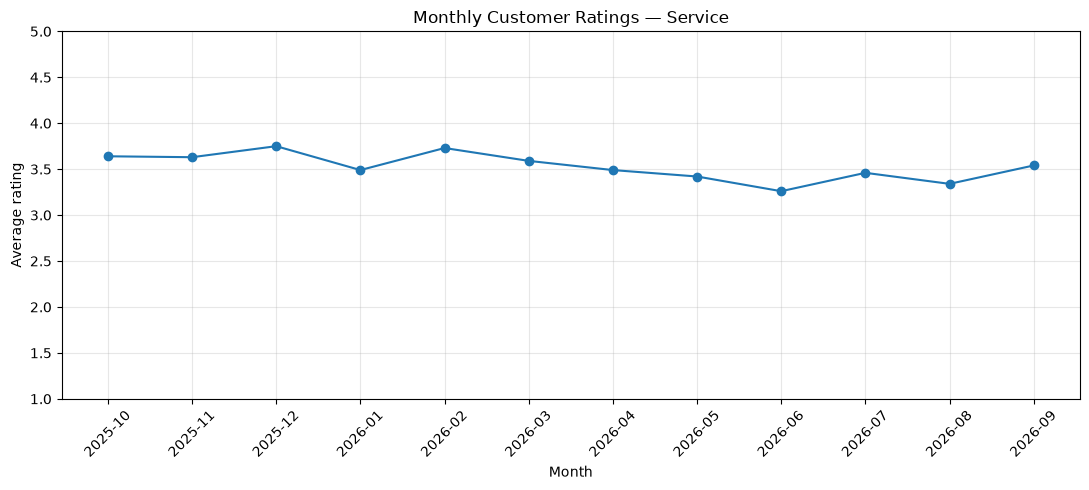

In [243]:

trend_to_plot = monthly_service_trend[
    monthly_service_trend["month"].between("2025-10", "2026-09")
].copy()

plt.figure(figsize=(11, 5))
plt.plot(
    trend_to_plot["month"],
    trend_to_plot["average_rating"],
    marker="o"
)
plt.title("Monthly Customer Ratings — Service")
plt.xlabel("Month")
plt.ylabel("Average rating")
plt.ylim(1, 5)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

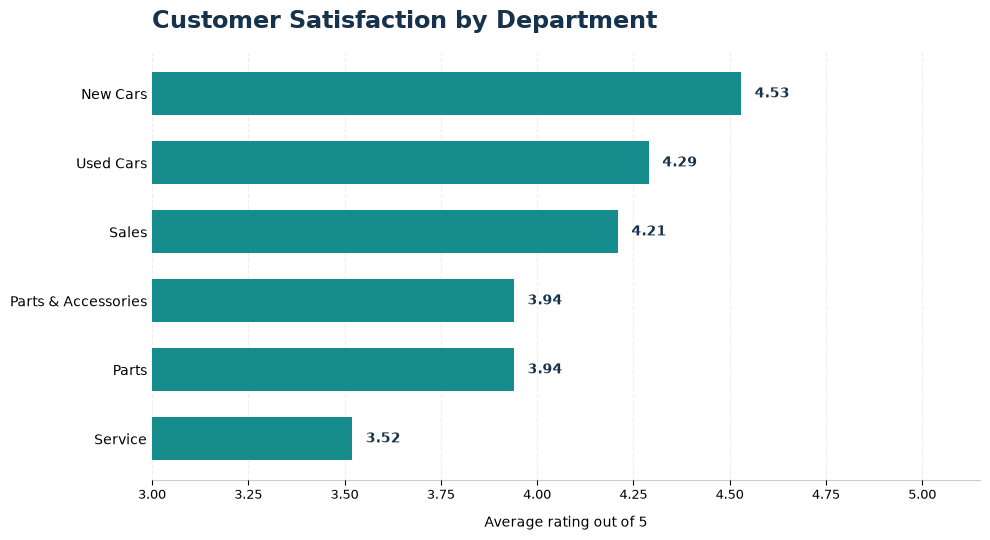

In [244]:



dept_plot = department_summary[
    department_summary["department_clean"].isin([
        "Service",
        "Parts",
        "Parts & Accessories",
        "Sales",
        "New Cars",
        "Used Cars"
    ])
].sort_values("average_rating", ascending=True).copy()

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.barh(
    dept_plot["department_clean"],
    dept_plot["average_rating"],
    height=0.62,
    color="#168C8C"
)

ax.set_title(
    "Customer Satisfaction by Department",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color="#17324D",
    pad=18
)
ax.set_xlabel("Average rating out of 5", labelpad=10)
ax.set_xlim(3, 5.15)
ax.xaxis.set_major_locator(mticker.MultipleLocator(0.25))
ax.grid(axis="x", linestyle="--", alpha=0.22)
ax.set_axisbelow(True)

for bar, rating in zip(bars, dept_plot["average_rating"]):
    ax.text(
        rating + 0.035,
        bar.get_y() + bar.get_height() / 2,
        f"{rating:.2f}",
        va="center",
        fontsize=10,
        color="#17324D",
        fontweight="bold"
    )

ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_alpha(0.2)
ax.tick_params(axis="y", length=0, labelsize=10)
ax.tick_params(axis="x", labelsize=9)
ax.set_facecolor("white")
fig.patch.set_facecolor("white")

plt.tight_layout()
plt.show()




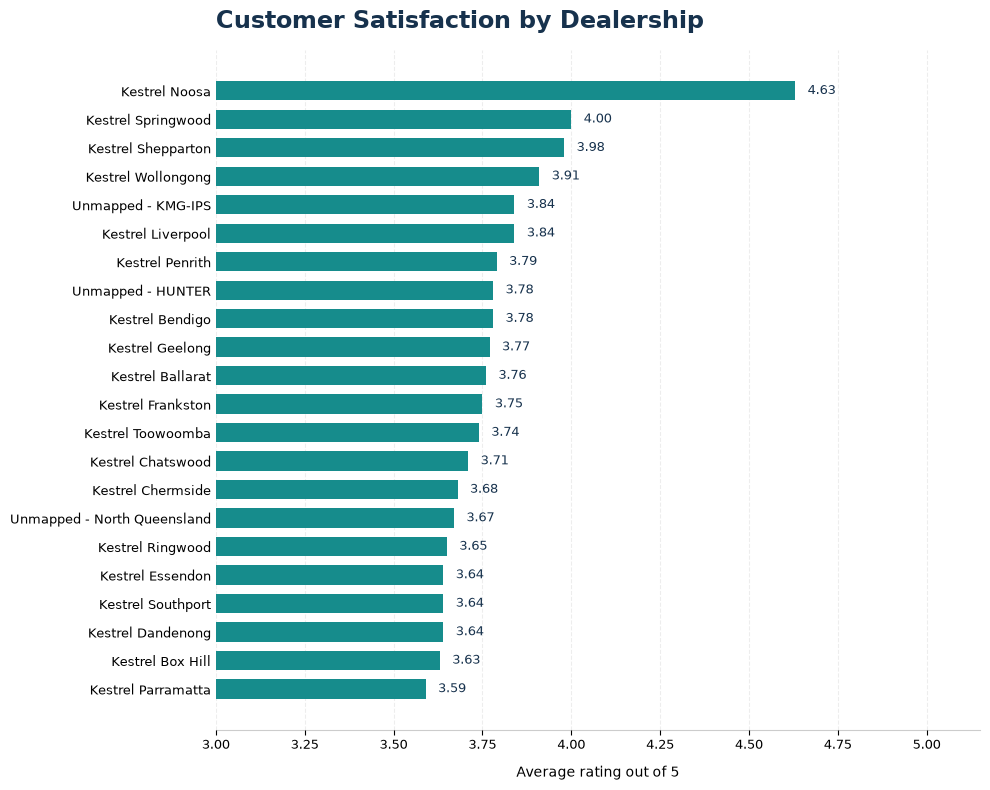

In [245]:

dealer_plot = dealership_summary.sort_values(
    "average_rating", ascending=True
).copy()

fig, ax = plt.subplots(figsize=(10, 8))

bars = ax.barh(
    dealer_plot["dealership_clean"],
    dealer_plot["average_rating"],
    height=0.68,
    color="#168C8C"
)

ax.set_title(
    "Customer Satisfaction by Dealership",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color="#17324D",
    pad=16
)

ax.set_xlabel("Average rating out of 5", labelpad=10)
ax.set_xlim(3, 5.15)
ax.xaxis.set_major_locator(mticker.MultipleLocator(0.25))
ax.grid(axis="x", linestyle="--", alpha=0.22)
ax.set_axisbelow(True)

for bar, rating in zip(bars, dealer_plot["average_rating"]):
    ax.text(
        rating + 0.035,
        bar.get_y() + bar.get_height() / 2,
        f"{rating:.2f}",
        va="center",
        fontsize=9,
        color="#17324D"
    )

ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_alpha(0.2)
ax.tick_params(axis="y", length=0, labelsize=9)
ax.tick_params(axis="x", labelsize=9)
ax.set_facecolor("white")
fig.patch.set_facecolor("white")

plt.tight_layout()
plt.show()

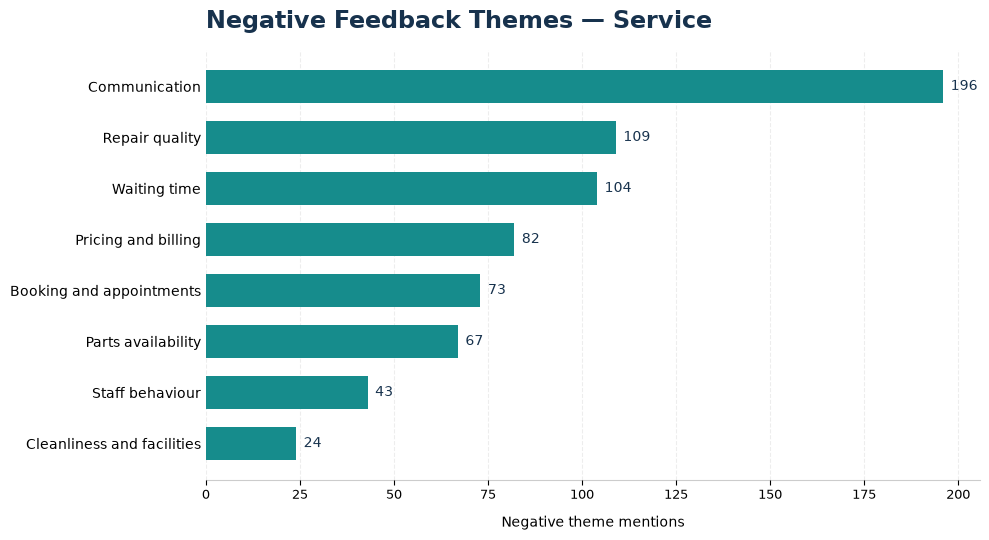

In [246]:

theme_plot = service_theme_summary.sort_values(
    "negative_mentions", ascending=True
).copy()

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.barh(
    theme_plot["theme"],
    theme_plot["negative_mentions"],
    height=0.65,
    color="#168C8C"
)

ax.set_title(
    "Negative Feedback Themes — Service",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color="#17324D",
    pad=16
)

ax.set_xlabel("Negative theme mentions", labelpad=10)
ax.grid(axis="x", linestyle="--", alpha=0.22)
ax.set_axisbelow(True)

for bar, value in zip(bars, theme_plot["negative_mentions"]):
    ax.text(
        value + 2,
        bar.get_y() + bar.get_height() / 2,
        f"{int(value)}",
        va="center",
        fontsize=10,
        color="#17324D"
    )

ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_alpha(0.2)
ax.tick_params(axis="y", length=0, labelsize=10)
ax.tick_params(axis="x", labelsize=9)
ax.set_facecolor("white")
fig.patch.set_facecolor("white")

plt.tight_layout()
plt.show()

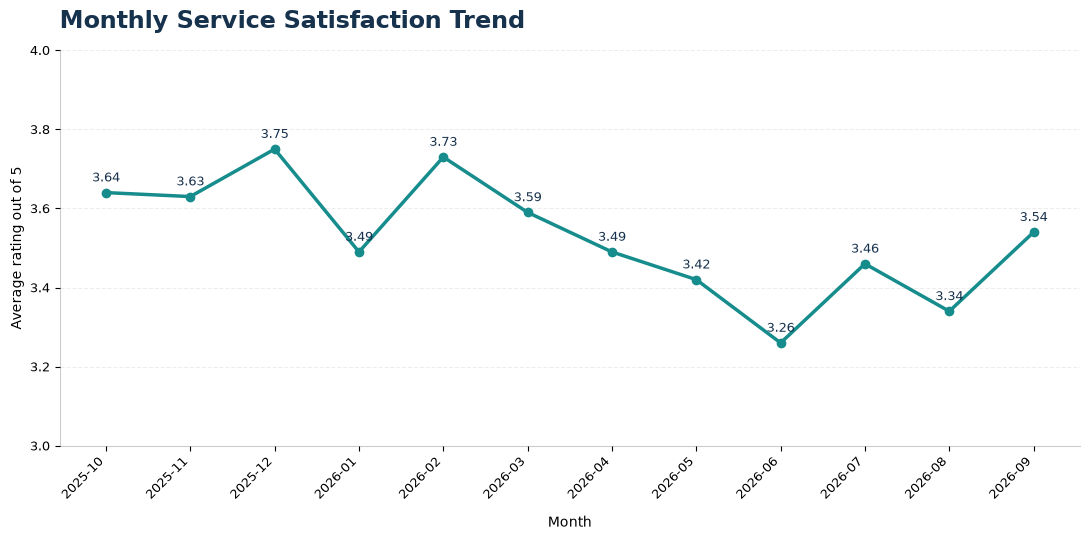

In [247]:

monthly_plot = monthly_service_trend[
    monthly_service_trend["month"].between("2025-10", "2026-09")
].copy()

fig, ax = plt.subplots(figsize=(11, 5.5))

ax.plot(
    monthly_plot["month"],
    monthly_plot["average_rating"],
    marker="o",
    linewidth=2.5,
    markersize=6,
    color="#168C8C"
)

ax.set_title(
    "Monthly Service Satisfaction Trend",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color="#17324D",
    pad=16
)

ax.set_ylabel("Average rating out of 5")
ax.set_xlabel("Month", labelpad=10)
ax.set_ylim(3.0, 4.0)
ax.yaxis.set_major_locator(mticker.MultipleLocator(0.2))
ax.set_xticks(range(len(monthly_plot)))
ax.set_xticklabels(monthly_plot["month"], rotation=45, ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.22)
ax.set_axisbelow(True)

for x, rating in enumerate(monthly_plot["average_rating"]):
    ax.annotate(
        f"{rating:.2f}",
        (x, rating),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color="#17324D"
    )

ax.spines[["top", "right"]].set_visible(False)
ax.spines["bottom"].set_alpha(0.2)
ax.spines["left"].set_alpha(0.2)
ax.tick_params(axis="both", labelsize=9)
ax.set_facecolor("white")
fig.patch.set_facecolor("white")

plt.tight_layout()
plt.show()

In [ ]:
# Inspect the cleaned dataset
cleaned_dataset = feedback_analysis.copy()

print("Total records:", len(cleaned_dataset))
print("Total columns:", len(cleaned_dataset.columns))

print("\nColumn names:")
print(cleaned_dataset.columns.tolist())

print("\nFirst 30 records:")
display(cleaned_dataset.head(30))

print("\nMissing values per column:")
display(cleaned_dataset.isna().sum().to_frame("Missing values"))

# Check duplicates safely, including rows containing lists
duplicate_check = cleaned_dataset.copy()
duplicate_check["themes_matched"] = (
    duplicate_check["themes_matched"].apply(str)
)

print(
    "\nExact duplicate rows:",
    duplicate_check.duplicated().sum()
)

# Export the complete dataset
cleaned_dataset.to_csv(
    "kestrel_cleaned_feedback.csv",
    index=False
)

print("\nCSV exported successfully: kestrel_cleaned_feedback.csv")

In [249]:

print("Current folder:", os.getcwd())
print("CSV exists:", os.path.exists("kestrel_cleaned_feedback.csv"))

Current folder: C:\Users\mufra
CSV exists: True


In [250]:

# Select only the columns intended for the final business-facing dataset
final_csv = feedback_analysis[
    [
        "dealership_clean",
        "date_clean",
        "department_clean",
        "rating_numeric",
        "comment",
        "sentiment",
        "themes_matched"
    ]
].copy()




final_csv = final_csv.rename(columns={
    "dealership_clean": "Dealership",
    "date_clean": "Date",
    "department_clean": "Department",
    "rating_numeric": "Customer Rating",
    "comment": "Customer Feedback",
    "sentiment": "Sentiment",
    "themes_matched": "Feedback Themes"
})

final_csv["Feedback Themes"] = final_csv["Feedback Themes"].apply(
    lambda x: ", ".join(map(str, x))
    if isinstance(x, list)
    else ("" if x is None or pd.isna(x) else str(x))
)

final_csv["Date"] = pd.to_datetime(
    final_csv["Date"], errors="coerce"
).dt.strftime("%Y-%m-%d")


# Apply limited pattern-based redaction to the exported copy only.
# The analysis dataframe and original comments remain unchanged.
def redact_export_comment(value):
    if not isinstance(value, str):
        return value
    value = re.sub(
        r"\\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\\.[A-Za-z]{2,}\\b",
        "[EMAIL REDACTED]",
        value
    )
    value = re.sub(
        r"(?<!\\w)(?:\\+?61[\\s().-]*[23478](?:[\\s().-]*\\d){8}|0[2378](?:[\\s().-]*\\d){8}|04(?:[\\s().-]*\\d){8})(?!\\w)",
        "[PHONE REDACTED]",
        value
    )
    value = re.sub(
        r"\\brego(\\s*[:#-]?\\s*)(?=[A-Z0-9]{5,7}\\b)(?=[A-Z0-9]*[A-Z])(?=[A-Z0-9]*\\d)([A-Z0-9]{5,7})\\b",
        lambda match: "rego" + match.group(1) + "[REGISTRATION REDACTED]",
        value,
        flags=re.IGNORECASE
    )
    return value

final_csv["Customer Feedback"] = final_csv["Customer Feedback"].apply(
    redact_export_comment
)

output_path = os.path.join(extract_folder, "kestrel_customer_feedback_clean_final.csv")
final_csv.to_csv(output_path, index=False, encoding="utf-8-sig")

print("Exported:", output_path)
print("Rows:", len(final_csv))
print("Columns:", list(final_csv.columns))

Exported: C:\Users\mufra\Kestrel_Assignment\kestrel_customer_feedback_clean_final.csv
Rows: 7086
Columns: ['Dealership', 'Date', 'Department', 'Customer Rating', 'Customer Feedback', 'Sentiment', 'Feedback Themes']


**Local runtime requirement:** cells in this section call the local Ollama service and require the `qwen2.5:3b` model to be downloaded and available. If Ollama is not running or the model is missing, these cells will fail; do not treat the AI experiment as completed until they run successfully. The VADER baseline is separately limited by the small manual validation sample described at the start of this notebook.

# 7. AI Experiment and Validation

In [251]:
%pip install ollama

Note: you may need to restart the kernel to use updated packages.


In [252]:

response = ollama.chat(
    model="qwen2.5:3b",
    messages=[
        {
            "role": "user",
            "content": "Reply with exactly: Local AI connection successful"
        }
    ]
)

print(response["message"]["content"])

Local AI connection successful


In [253]:
print("Dataset shape:", feedback_analysis.shape)
print("Column names:", feedback_analysis.columns.tolist())
print("Missing values:\n", feedback_analysis.isnull().sum())

Dataset shape: (7086, 17)
Column names: ['dealership', 'dealership_clean', 'source_file', 'date', 'date_clean', 'department', 'department_clean', 'rating_original', 'rating_standardised', 'rating_category', 'comment', 'rating_numeric', 'sentiment_compound', 'sentiment', 'themes_matched', 'theme_count', 'dealer_code']
Missing values:
 dealership                0
dealership_clean          0
source_file               0
date                      0
date_clean               10
department                0
department_clean          0
rating_original          10
rating_standardised      10
rating_category        6953
comment                1725
rating_numeric          143
sentiment_compound     1725
sentiment              1725
themes_matched            0
theme_count               0
dealer_code            1136
dtype: int64


In [254]:

comments = feedback_analysis["comment"].dropna().astype(str)

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
phone_pattern = r"(?<!\w)(?:\+?61|0)\s?(?:\(?\d{1,4}\)?[\s.-]?)\d{3,4}[\s.-]?\d{3,4}(?!\w)"

email_count = comments.str.contains(email_pattern, regex=True).sum()
phone_count = comments.str.contains(phone_pattern, regex=True).sum()

print("Non-empty comments:", len(comments))
print("Comments containing email-like text:", email_count)
print("Comments containing phone-like text:", phone_count)

Non-empty comments: 5361
Comments containing email-like text: 58
Comments containing phone-like text: 156


In [255]:
feedback_analysis_private = feedback_analysis.copy()

print("Original rows:", len(feedback_analysis))
print("Privacy copy rows:", len(feedback_analysis_private))
print("Original columns:", len(feedback_analysis.columns))
print("Privacy copy columns:", len(feedback_analysis_private.columns))

Original rows: 7086
Privacy copy rows: 7086
Original columns: 17
Privacy copy columns: 17


In [256]:

def redact_personal_info(text):
    if not isinstance(text, str):
        return text

    # Redact email addresses
    text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "[EMAIL REDACTED]",
        text
    )

    # Redact likely Australian phone numbers
    text = re.sub(
        r"(?<!\w)(?:\+?61|0)\s?(?:\(?\d{1,4}\)?[\s.-]?)\d{3,4}[\s.-]?\d{3,4}(?!\w)",
        "[PHONE REDACTED]",
        text
    )

    return text

feedback_analysis_private["comment"] = (
    feedback_analysis_private["comment"].apply(redact_personal_info)
)

print("Privacy copy updated.")
print("Original dataset unchanged:", feedback_analysis["comment"].equals(
    feedback_analysis_private["comment"]
))

Privacy copy updated.
Original dataset unchanged: False


In [257]:

# Australian-style vehicle registration patterns (preliminary check)
plate_pattern = r"\b(?:[A-Z]{2,3}\s?\d{2,4}|[A-Z]{1,3}\s?\d{3,4})\b"

comments = feedback_analysis_private["comment"].dropna().astype(str)

plate_matches = comments.str.findall(plate_pattern)

print("Comments with possible registration numbers:", (plate_matches.str.len() > 0).sum())
print("Total possible matches:", plate_matches.str.len().sum())

Comments with possible registration numbers: 180
Total possible matches: 180


In [258]:
plate_counts = plate_matches.str.len()

print("Comments with one possible match:", (plate_counts == 1).sum())
print("Comments with multiple possible matches:", (plate_counts > 1).sum())
print("Comments with no possible matches:", (plate_counts == 0).sum())

Comments with one possible match: 180
Comments with multiple possible matches: 0
Comments with no possible matches: 5181


In [259]:
comments = feedback_analysis_private["comment"].dropna().astype(str)

name_intro_pattern = (
    r"(?i)^\s*(?:"
    r"my name is\s+|"
    r"i am\s+|"
    r"i'm\s+|"
    r"this is\s+"
    r")"
)

name_intro_matches = comments.str.contains(
    name_intro_pattern, regex=True, na=False
)

print("Comments beginning with a possible name introduction:",
      name_intro_matches.sum())

Comments beginning with a possible name introduction: 47


In [260]:
original_comments = feedback_analysis["comment"].fillna("")
private_comments = feedback_analysis_private["comment"].fillna("")

changed_comments = original_comments.ne(private_comments)

print("Comments changed by redaction:", changed_comments.sum())
print("Original dataset still unchanged:",
      feedback_analysis["comment"].equals(feedback_analysis_private["comment"]))

Comments changed by redaction: 214
Original dataset still unchanged: False


In [261]:
print("Original dataset rows:", len(feedback_analysis))
print("Privacy copy rows:", len(feedback_analysis_private))

print(
    "Original comments equal the saved pre-redaction state:",
    feedback_analysis["comment"].equals(
        feedback_analysis_private["comment"].where(
            ~feedback_analysis["comment"].fillna("").ne(
                feedback_analysis_private["comment"].fillna("")
            ),
            feedback_analysis["comment"]
        )
    )
)

Original dataset rows: 7086
Privacy copy rows: 7086
Original comments equal the saved pre-redaction state: False


In [262]:
print("Original dataset exists:", "feedback_analysis" in globals())
print("Privacy copy exists:", "feedback_analysis_private" in globals())
print("Original shape:", feedback_analysis.shape)
print("Privacy copy shape:", feedback_analysis_private.shape)

Original dataset exists: True
Privacy copy exists: True
Original shape: (7086, 17)
Privacy copy shape: (7086, 17)


In [263]:
original_comments_snapshot = feedback_analysis["comment"].copy(deep=True)

print("Snapshot saved.")
print("Comments in snapshot:", len(original_comments_snapshot))
print(
    "Snapshot matches current original:",
    original_comments_snapshot.equals(feedback_analysis["comment"])
)

Snapshot saved.
Comments in snapshot: 7086
Snapshot matches current original: True


In [264]:
print(
    "Original comments unchanged:",
    original_comments_snapshot.equals(feedback_analysis["comment"])
)

Original comments unchanged: True


In [265]:

comments = feedback_analysis_private["comment"].dropna().astype(str)

name_intro_pattern = (
    r"(?i)^\s*(?:my name is|i am|i'm|this is)\s+"
)

name_intro_matches = comments.str.contains(
    name_intro_pattern, regex=True, na=False
)

print("Comments with possible name introductions:", name_intro_matches.sum())
print("Original comments still match snapshot:",
      original_comments_snapshot.equals(feedback_analysis["comment"]))

Comments with possible name introductions: 47
Original comments still match snapshot: True


In [266]:
comments = feedback_analysis_private["comment"].fillna("").astype(str)

name_intro_matches = comments.str.contains(
    r"(?i)^\s*(?:my name is|i am|i'm|this is)\s+",
    regex=True
)

print("Possible name introductions:", int(name_intro_matches.sum()))
print("Original comments unchanged:",
      original_comments_snapshot.equals(feedback_analysis["comment"]))

Possible name introductions: 47
Original comments unchanged: True


In [267]:
# Recalculate possible registration-number matches on the privacy copy
comments = feedback_analysis_private["comment"].fillna("").astype(str)

plate_pattern = r"\b(?:[A-Z]{2,3}\s?\d{2,4}|[A-Z]{1,3}\s?\d{3,4})\b"
plate_matches = comments.str.findall(plate_pattern)

plate_mask = plate_matches.str.len().gt(0)

print("Possible registration-number comments:", int(plate_mask.sum()))
print("Possible name-introduction comments:", int(name_intro_matches.sum()))
print("Comments flagged by both checks:", int((plate_mask & name_intro_matches).sum()))

Possible registration-number comments: 180
Possible name-introduction comments: 47
Comments flagged by both checks: 2


In [268]:
feedback_analysis_privacy_checkpoint = feedback_analysis_private.copy(deep=True)

print("Checkpoint rows:", len(feedback_analysis_privacy_checkpoint))
print("Checkpoint columns:", len(feedback_analysis_privacy_checkpoint.columns))
print(
    "Original comments still unchanged:",
    original_comments_snapshot.equals(feedback_analysis["comment"])
)

Checkpoint rows: 7086
Checkpoint columns: 17
Original comments still unchanged: True


In [269]:
text_columns = feedback_analysis_privacy_checkpoint.select_dtypes(
    include=["object", "string"]
).columns

print("Text columns checked:", len(text_columns))

for column in text_columns:
    if column != "comment":
        print(f"{column}: {feedback_analysis_privacy_checkpoint[column].notna().sum()} non-missing values")

Text columns checked: 14
dealership: 7086 non-missing values
dealership_clean: 7086 non-missing values
source_file: 7086 non-missing values
date: 7086 non-missing values
department: 7086 non-missing values
department_clean: 7086 non-missing values
rating_original: 7076 non-missing values
rating_standardised: 7076 non-missing values
rating_category: 133 non-missing values
sentiment_compound: 5361 non-missing values
sentiment: 5361 non-missing values
themes_matched: 7086 non-missing values
dealer_code: 5950 non-missing values


In [270]:

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
phone_pattern = r"(?<!\w)(?:\+?61|0)\s?(?:\(?\d{1,4}\)?[\s.-]?)\d{3,4}[\s.-]?\d{3,4}(?!\w)"

for column in text_columns:
    if column == "comment":
        continue

    values = feedback_analysis_privacy_checkpoint[column].dropna().astype(str)

    email_count = values.str.contains(email_pattern, regex=True).sum()
    phone_count = values.str.contains(phone_pattern, regex=True).sum()

    if email_count or phone_count:
        print(f"{column}: {email_count} email-like, {phone_count} phone-like matches")

print("Scan complete. No column values were displayed.")

Scan complete. No column values were displayed.


In [271]:
output_path = os.path.join(extract_folder, "kestrel_customer_feedback_privacy_working.csv")

feedback_analysis_privacy_checkpoint.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved privacy working copy.")
print("Rows:", len(feedback_analysis_privacy_checkpoint))
print("Columns:", len(feedback_analysis_privacy_checkpoint.columns))

Saved privacy working copy.
Rows: 7086
Columns: 17


In [272]:

saved_copy = pd.read_csv(
    os.path.join(extract_folder, "kestrel_customer_feedback_privacy_working.csv")
)

print("Saved file shape:", saved_copy.shape)
print("Column names match:",
      saved_copy.columns.tolist()
      == feedback_analysis_privacy_checkpoint.columns.tolist())
print("Original comments still unchanged:",
      original_comments_snapshot.equals(feedback_analysis["comment"]))

Saved file shape: (7086, 17)
Column names match: True
Original comments still unchanged: True


In [273]:
ratings = feedback_analysis_privacy_checkpoint["rating_numeric"]

print("Non-missing numeric ratings:", ratings.notna().sum())
print("\nRating value counts:")
print(ratings.value_counts(dropna=False).sort_index().to_string())
print("\nRating minimum:", ratings.min())
print("Rating maximum:", ratings.max())

Non-missing numeric ratings: 6943

Rating value counts:
rating_numeric
0.5      26
1.0     914
1.5      10
2.0     622
2.5      14
3.0     737
3.5      31
4.0    1504
4.5      82
5.0    3003
NaN     143

Rating minimum: 0.5
Rating maximum: 5.0


In [274]:
rating_check = (
    feedback_analysis_privacy_checkpoint
    .groupby("dealership_clean")["rating_numeric"]
    .agg(
        total_rows="size",
        valid_ratings="count",
        unique_values="nunique",
        minimum="min",
        maximum="max"
    )
    .sort_index()
)

print(rating_check.to_string())

                             total_rows  valid_ratings  unique_values  minimum  maximum
dealership_clean                                                                       
Kestrel Ballarat                    292            292              5      1.0      5.0
Kestrel Bendigo                     144            144              5      1.0      5.0
Kestrel Box Hill                    309            309              5      1.0      5.0
Kestrel Chatswood                   278            278              5      1.0      5.0
Kestrel Chermside                   460            460              5      1.0      5.0
Kestrel Dandenong                   484            484              5      1.0      5.0
Kestrel Essendon                    346            346              5      1.0      5.0
Kestrel Frankston                   308            308              5      1.0      5.0
Kestrel Geelong                     304            304              5      1.0      5.0
Kestrel Liverpool               

In [275]:
for dealer in ["Kestrel Ringwood", "Kestrel Tamworth"]:
    subset = feedback_analysis_privacy_checkpoint[
        feedback_analysis_privacy_checkpoint["dealership_clean"] == dealer
    ]

    print(f"\n{dealer}")
    print(subset["rating_original"].value_counts(dropna=False).sort_index().to_string())


Kestrel Ringwood
rating_original
1     37
2     30
3     25
4     57
5     66
6     21
7     31
8     28
9     82
10    77

Kestrel Tamworth
rating_original
Bad     21
Good    93
OK      19
NaN     10


In [276]:
ringwood = feedback_analysis_privacy_checkpoint[
    feedback_analysis_privacy_checkpoint["dealership_clean"] == "Kestrel Ringwood"
]

print(
    ringwood[
        ["rating_original", "rating_standardised", "rating_numeric"]
    ]
    .drop_duplicates()
    .sort_values("rating_original")
    .to_string(index=False)
)

rating_original rating_standardised  rating_numeric
              1                 1.0             1.0
              1                 0.5             0.5
              2                 2.0             2.0
              2                 1.0             1.0
              3                 3.0             3.0
              3                 1.5             1.5
              4                 4.0             4.0
              4                 2.0             2.0
              5                 5.0             5.0
              5                 2.5             2.5
              6                 3.0             3.0
              7                 3.5             3.5
              8                 4.0             4.0
              9                 4.5             4.5
             10                 5.0             5.0


In [277]:
ringwood = feedback_analysis_privacy_checkpoint[
    feedback_analysis_privacy_checkpoint["dealership_clean"] == "Kestrel Ringwood"
]

print(
    ringwood.groupby("source_file")
    .agg(
        rows=("rating_original", "size"),
        original_ratings=("rating_original", "nunique"),
        standardised_ratings=("rating_standardised", "nunique")
    )
    .to_string()
)

                                rows  original_ratings  standardised_ratings
source_file                                                                 
Ringwood feedback Q1 2026.xlsx   112                10                    10
Ringwood feedback Q2 2026.xlsx   115                10                    10
Ringwood feedback Q3 2026.xlsx   127                 9                     9
Ringwood feedback Q4 2025.xlsx   100                 5                     5


In [278]:

df = feedback_analysis_privacy_checkpoint.copy()

print("DATASET OVERVIEW")
print("-" * 35)
print(f"Total feedback records: {len(df):,}")
print(f"Dealerships: {df['dealership_clean'].nunique()}")
print(f"Missing comments: {df['comment'].isna().sum():,}")
print(f"Missing numeric ratings: {df['rating_numeric'].isna().sum():,}")

print("\nAVERAGE RATING BY DEALERSHIP")
print("-" * 35)

summary = (
    df.groupby("dealership_clean")
    .agg(
        feedback_count=("dealership_clean", "size"),
        average_rating=("rating_numeric", "mean"),
        valid_ratings=("rating_numeric", "count")
    )
    .sort_values("average_rating", ascending=False)
)

print(summary.round(2).to_string())

DATASET OVERVIEW
-----------------------------------
Total feedback records: 7,086
Dealerships: 23
Missing comments: 1,725
Missing numeric ratings: 143

AVERAGE RATING BY DEALERSHIP
-----------------------------------
                             feedback_count  average_rating  valid_ratings
dealership_clean                                                          
Kestrel Noosa                            49            4.63             49
Kestrel Springwood                      298            4.00            298
Kestrel Shepparton                       52            3.98             52
Kestrel Wollongong                      285            3.91            285
Unmapped - KMG-IPS                      277            3.84            277
Kestrel Liverpool                       311            3.84            311
Kestrel Penrith                         454            3.79            454
Unmapped - HUNTER                       303            3.78            303
Kestrel Bendigo                 

In [279]:
df = feedback_analysis_privacy_checkpoint.copy()

theme_counts = (
    df["themes_matched"]
    .dropna()
    .astype(str)
    .str.split(",")
    .explode()
    .str.strip()
)

theme_counts = theme_counts[theme_counts.ne("")]

print("MOST FREQUENT FEEDBACK THEMES")
print("-" * 40)
print(theme_counts.value_counts().head(15).to_string())

print("\nRECORDS WITH NO MATCHED THEME")
print("-" * 40)
print(
    "Missing theme labels:",
    df["themes_matched"].isna().sum()
)
print(
    "No matched theme:",
    df["themes_matched"].fillna("").astype(str).str.strip().eq("").sum()
)

MOST FREQUENT FEEDBACK THEMES
----------------------------------------
themes_matched
[]                              4156
['Communication']                589
['Communication'                 445
['Staff behaviour']              409
['Pricing and billing']          372
['Waiting time']                 228
'Pricing and billing']           186
['Waiting time'                  179
['Repair quality']               177
['Parts availability']           155
'Staff behaviour']               154
'Repair quality']                145
'Booking and appointments']      136
['Booking and appointments']     134
'Parts availability']            109

RECORDS WITH NO MATCHED THEME
----------------------------------------
Missing theme labels: 0
No matched theme: 0


In [280]:
from collections import Counter

df = feedback_analysis_privacy_checkpoint.copy()

theme_counts = Counter()
no_theme_count = 0

for value in df["themes_matched"].dropna():
    try:
        parsed = ast.literal_eval(value) if isinstance(value, str) else value

        if isinstance(parsed, list):
            themes = [str(theme).strip() for theme in parsed if str(theme).strip()]
        elif isinstance(parsed, str) and parsed.strip():
            themes = [parsed.strip()]
        else:
            themes = []

        if themes:
            theme_counts.update(themes)
        else:
            no_theme_count += 1

    except (ValueError, SyntaxError):
        no_theme_count += 1

print("MOST FREQUENT FEEDBACK THEMES")
print("-" * 40)

for theme, count in theme_counts.most_common(15):
    print(f"{theme}: {count:,}")

print(f"\nRecords with no parsed theme: {no_theme_count:,}")
print(f"Total records: {len(df):,}")

MOST FREQUENT FEEDBACK THEMES
----------------------------------------
Communication: 1,034
Pricing and billing: 611
Staff behaviour: 576
Waiting time: 555
Repair quality: 419
Parts availability: 415
Booking and appointments: 270
Cleanliness and facilities: 62

Records with no parsed theme: 4,156
Total records: 7,086


In [281]:

df = feedback_analysis_privacy_checkpoint.copy()
rows = []

for _, row in df.iterrows():
    value = row["themes_matched"]

    try:
        themes = ast.literal_eval(value) if isinstance(value, str) else value
    except (ValueError, SyntaxError):
        continue

    if isinstance(themes, list):
        for theme in themes:
            if str(theme).strip():
                rows.append({
                    "theme": str(theme).strip(),
                    "rating": row["rating_numeric"]
                })

theme_rating_data = pd.DataFrame(rows)

theme_rating_summary = (
    theme_rating_data
    .groupby("theme")
    .agg(
        tagged_records=("theme", "size"),
        valid_ratings=("rating", "count"),
        average_rating=("rating", "mean")
    )
    .sort_values("average_rating")
)

print(theme_rating_summary.round(2).to_string())


                            tagged_records  valid_ratings  average_rating
theme                                                                    
Cleanliness and facilities              62             61            2.52
Repair quality                         419            411            2.58
Booking and appointments               270            264            2.59
Waiting time                           555            549            2.76
Communication                         1034           1010            2.83
Parts availability                     415            409            2.99
Pricing and billing                    611            596            3.33
Staff behaviour                        576            569            4.02


In [282]:
df = feedback_analysis_privacy_checkpoint.copy()

df = df[
    ~df["dealership_clean"].isin(["Kestrel Ringwood", "Kestrel Tamworth"])
].copy()

df["date_parsed"] = pd.to_datetime(
    df["date_clean"], errors="coerce", dayfirst=True
)

df["month"] = df["date_parsed"].dt.to_period("M")

monthly_summary = (
    df.dropna(subset=["month", "rating_numeric"])
    .groupby("month")
    .agg(
        feedback_count=("rating_numeric", "count"),
        average_rating=("rating_numeric", "mean")
    )
    .sort_index()
)

print("MONTHLY CUSTOMER RATING TREND")
print("-" * 45)
print(monthly_summary.round(2).to_string())
print("\nRecords excluded due to unparsed dates:", df["date_parsed"].isna().sum())

MONTHLY CUSTOMER RATING TREND
---------------------------------------------
         feedback_count  average_rating
month                                  
2025-10             540            3.82
2025-11             501            3.87
2025-12             483            3.95
2026-01             471            3.72
2026-02             543            3.87
2026-03             564            3.79
2026-04             545            3.63
2026-05             570            3.72
2026-06             556            3.60
2026-07             559            3.70
2026-08             568            3.55
2026-09             573            3.73
2026-10               3            3.00
2026-11               2            4.50
2026-12               1            5.00

Records excluded due to unparsed dates: 10


In [283]:
df = feedback_analysis_privacy_checkpoint.copy()

df = df[
    ~df["dealership_clean"].isin(["Kestrel Ringwood", "Kestrel Tamworth"])
].copy()

df["date_parsed"] = pd.to_datetime(
    df["date_clean"], errors="coerce", dayfirst=True
)

df["month"] = df["date_parsed"].dt.to_period("M")

comparison = (
    df[df["month"].isin([pd.Period("2025-12"), pd.Period("2026-08")])]
    .dropna(subset=["rating_numeric"])
    .groupby(["dealership_clean", "month"])["rating_numeric"]
    .agg(["mean", "count"])
    .unstack("month")
)

comparison.columns = [
    f"{metric}_{month}" for metric, month in comparison.columns
]

comparison = comparison.rename(columns={
    "mean_2025-12": "Dec_2025_avg",
    "count_2025-12": "Dec_2025_count",
    "mean_2026-08": "Aug_2026_avg",
    "count_2026-08": "Aug_2026_count"
})

comparison["change"] = comparison["Aug_2026_avg"] - comparison["Dec_2025_avg"]

print(comparison.sort_values("change").round(2).to_string())

                             Dec_2025_avg  Aug_2026_avg  Dec_2025_count  Aug_2026_count  change
dealership_clean                                                                               
Kestrel Bendigo                      4.20          2.90            10.0            10.0   -1.30
Kestrel Parramatta                   4.22          2.95            37.0            39.0   -1.27
Kestrel Dandenong                    4.30          3.09            37.0            44.0   -1.21
Kestrel Wollongong                   4.33          3.27            30.0            26.0   -1.06
Kestrel Liverpool                    4.00          3.17            26.0            23.0   -0.83
Kestrel Box Hill                     3.95          3.41            19.0            27.0   -0.54
Kestrel Chatswood                    4.09          3.67            22.0            30.0   -0.42
Kestrel Essendon                     4.09          3.68            23.0            19.0   -0.40
Unmapped - KMG-IPS                   4.1

In [284]:

df = feedback_analysis_privacy_checkpoint.copy()

df = df[
    df["dealership_clean"].isin([
        "Kestrel Parramatta",
        "Kestrel Dandenong"
    ])
].copy()

df["date_parsed"] = pd.to_datetime(
    df["date_clean"], errors="coerce", dayfirst=True
)
df["month"] = df["date_parsed"].dt.to_period("M")

df = df[
    df["month"].isin([
        pd.Period("2025-12"),
        pd.Period("2026-08")
    ])
].copy()

def parse_themes(value):
    if isinstance(value, list):
        return value
    if not isinstance(value, str):
        return []
    try:
        result = ast.literal_eval(value)
        return result if isinstance(result, list) else []
    except (ValueError, SyntaxError):
        return []

df["parsed_themes"] = df["themes_matched"].apply(parse_themes)
df = df.explode("parsed_themes")
df = df[df["parsed_themes"].notna() & (df["parsed_themes"] != "")]

theme_comparison = (
    df.groupby(["dealership_clean", "month", "parsed_themes"])
      .agg(
          feedback_count=("rating_numeric", "size"),
          average_rating=("rating_numeric", "mean")
      )
      .reset_index()
)

print(theme_comparison.round(2).to_string(index=False))

  dealership_clean   month              parsed_themes  feedback_count  average_rating
 Kestrel Dandenong 2025-12 Cleanliness and facilities               1            2.00
 Kestrel Dandenong 2025-12              Communication               5            4.20
 Kestrel Dandenong 2025-12         Parts availability               2            4.50
 Kestrel Dandenong 2025-12        Pricing and billing               2            4.50
 Kestrel Dandenong 2025-12             Repair quality               2            2.00
 Kestrel Dandenong 2025-12            Staff behaviour               4            4.50
 Kestrel Dandenong 2025-12               Waiting time               5            3.40
 Kestrel Dandenong 2026-08   Booking and appointments               8            1.38
 Kestrel Dandenong 2026-08              Communication               9            2.22
 Kestrel Dandenong 2026-08         Parts availability               4            3.75
 Kestrel Dandenong 2026-08        Pricing and billing 

C:\Users\mufra\AppData\Local\Temp\ipykernel_37056\3288008781.py:46: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(theme_comparison.round(2).to_string(index=False))


In [285]:

response = ollama.chat(
    model="qwen2.5:3b",
    messages=[
        {
            "role": "user",
            "content": "In one sentence, explain how AI can help analyse customer feedback."
        }
    ]
)

print(response["message"]["content"])

AI can help analyse customer feedback by automatically processing large volumes of text data, identifying key themes, sentiments, and trends, and providing actionable insights that would be impractical for manual analysis.


In [ ]:

df = feedback_analysis_privacy_checkpoint.copy()

sample = (
    df.loc[
        df["comment"].apply(
            lambda x: isinstance(x, str) and bool(x.strip())
        ),
        ["dealership_clean", "comment", "rating_numeric"]
    ]
    .sample(n=min(5, df["comment"].apply(
        lambda x: isinstance(x, str) and bool(x.strip())
    ).sum()), random_state=42)
    .copy()
)

def analyse_comment(comment):
    response = ollama.chat(
        model="qwen2.5:3b",
        messages=[
            {
                "role": "system",
                "content": (
                    "You analyse customer feedback for a motor dealership group. "
                    "Use only evidence in the comment. Do not invent details. "
                    "Return: Sentiment (positive, neutral, or negative); "
                    "Main issue (brief phrase or None); "
                    "Reason (one short sentence)."
                )
            },
            {
                "role": "user",
                "content": comment
            }
        ],
        options={"temperature": 0}
    )
    return response["message"]["content"].strip()

sample["ollama_analysis"] = sample["comment"].apply(analyse_comment)

print(sample.drop(columns=["comment"], errors="ignore").to_string(index=False))

In [287]:

def analyse_comment_structured(comment):
    response = ollama.chat(
        model="qwen2.5:3b",
        format="json",
        messages=[
            {
                "role": "system",
                "content": (
                    "Analyse customer feedback for a motor dealership group. "
                    "Use only evidence explicitly supported by the comment. "
                    "Return valid JSON with exactly these keys: "
                    "sentiment (positive, neutral, or negative), "
                    "main_issue (short phrase or null), "
                    "reason (one concise sentence). "
                    "Do not invent details. If the comment does not describe "
                    "a problem, use null for main_issue."
                )
            },
            {"role": "user", "content": comment}
        ],
        options={"temperature": 0}
    )

    try:
        result = json.loads(response["message"]["content"])
        return {
            "sentiment": result.get("sentiment"),
            "main_issue": result.get("main_issue"),
            "reason": result.get("reason")
        }
    except (json.JSONDecodeError, TypeError):
        return {
            "sentiment": None,
            "main_issue": None,
            "reason": "Invalid JSON returned by model; requires review."
        }

structured_results = sample["comment"].apply(analyse_comment_structured)

sample["ai_sentiment"] = structured_results.apply(lambda x: x["sentiment"])
sample["ai_main_issue"] = structured_results.apply(lambda x: x["main_issue"])
sample["ai_reason"] = structured_results.apply(lambda x: x["reason"])

print(sample[
    ["dealership_clean", "rating_numeric", "ai_sentiment", "ai_main_issue", "ai_reason"]
].to_string(index=False))

  dealership_clean  rating_numeric ai_sentiment               ai_main_issue                                                                                     ai_reason
 Kestrel Chatswood             5.0     positive                         NaN                     Feedback about courteous and approachable service with clear explanations
  Kestrel Ringwood             2.0     negative heater not working properly             Customer was told the part had been replaced, but the heater still blows cold air
 Kestrel Chermside             5.0      neutral                         NaN The customer did not encounter any issues, only needed clarification on paperwork procedures.
  Kestrel Ringwood             2.5     negative   finance person's behavior                     Finance person's continued sales pitch despite customer's initial refusal
Kestrel Parramatta             3.0      neutral                         NaN                             Service appointment with receptionist Tuan was

In [ ]:
def analyse_comment_structured(comment):
    response = ollama.chat(
        model="qwen2.5:3b",
        format="json",
        messages=[
            {
                "role": "system",
                "content": (
                    "Classify customer feedback for a motor dealership group. "
                    "Use only the information in the comment. "
                    "Return JSON with exactly these keys: "
                    "sentiment, main_issue, reason. "
                    "Sentiment must be positive, neutral, or negative. "
                    "Use positive when the customer expresses satisfaction, "
                    "praise, or appreciation. "
                    "Use negative when the customer reports a problem, "
                    "unresolved request, poor service, or unwanted pressure. "
                    "Use neutral only when the comment is genuinely factual "
                    "and expresses neither satisfaction nor dissatisfaction. "
                    "A complaint must not be classified as neutral merely "
                    "because it is politely worded. "
                    "main_issue must be a short phrase or null. "
                    "Use null when no problem is reported. "
                    "reason must be one concise sentence supported by the comment. "
                    "Do not invent details."
                )
            },
            {"role": "user", "content": comment}
        ],
        options={"temperature": 0}
    )

    try:
        result = json.loads(response["message"]["content"])
        sentiment = result.get("sentiment")

        if sentiment not in {"positive", "neutral", "negative"}:
            raise ValueError("Invalid sentiment label")

        issue = result.get("main_issue")
        reason = result.get("reason")

        return {
            "sentiment": sentiment,
            "main_issue": issue,
            "reason": reason
        }

    except (json.JSONDecodeError, TypeError, ValueError):
        return {
            "sentiment": None,
            "main_issue": None,
            "reason": "Invalid model output; requires manual review."
        }

In [289]:
structured_results = sample["comment"].apply(analyse_comment_structured)

sample["ai_sentiment"] = structured_results.apply(lambda x: x["sentiment"])
sample["ai_main_issue"] = structured_results.apply(lambda x: x["main_issue"])
sample["ai_reason"] = structured_results.apply(lambda x: x["reason"])

print(sample[
    ["dealership_clean", "rating_numeric", "ai_sentiment", "ai_main_issue", "ai_reason"]
].to_string(index=False))

  dealership_clean  rating_numeric ai_sentiment               ai_main_issue                                                                                                                                     ai_reason
 Kestrel Chatswood             5.0     positive                         NaN                                                                                        Customer had a positive experience with the parts team
  Kestrel Ringwood             2.0     negative heater not working properly                                                              Customer was told the part had been replaced but the heater still blows cold air
 Kestrel Chermside             5.0      neutral                         NaN                                                                               Explaining rego and inspection paperwork in order and patiently
  Kestrel Ringwood             2.5     negative   finance person's behavior Finance person's continued pressure despite customer

In [290]:
expected_sentiment = [
    "positive",
    "negative",
    "positive",
    "negative",
    "negative"
]

sample["expected_sentiment"] = expected_sentiment

sample["correct"] = (
    sample["ai_sentiment"] == sample["expected_sentiment"]
)

print(sample[
    ["dealership_clean", "ai_sentiment", "expected_sentiment", "correct"]
].to_string(index=False))

print(
    f"\nPilot accuracy: "
    f"{sample['correct'].sum()}/{len(sample)} "
    f"({sample['correct'].mean():.0%})"
)

  dealership_clean ai_sentiment expected_sentiment  correct
 Kestrel Chatswood     positive           positive     True
  Kestrel Ringwood     negative           negative     True
 Kestrel Chermside      neutral           positive    False
  Kestrel Ringwood     negative           negative     True
Kestrel Parramatta      neutral           negative    False

Pilot accuracy: 3/5 (60%)


In [291]:
sample_check = sample.copy()

sample_check["existing_sentiment"] = feedback_analysis.loc[
    sample.index, "sentiment"
].values

print(sample_check[
    ["dealership_clean", "rating_numeric", "existing_sentiment",
     "ai_sentiment", "expected_sentiment"]
].to_string(index=False))

  dealership_clean  rating_numeric existing_sentiment ai_sentiment expected_sentiment
 Kestrel Chatswood             5.0           Positive     positive           positive
  Kestrel Ringwood             2.0           Negative     negative           negative
 Kestrel Chermside             5.0           Negative      neutral           positive
  Kestrel Ringwood             2.5           Negative     negative           negative
Kestrel Parramatta             3.0           Positive      neutral           negative


In [292]:
print(sample_check[
    ["dealership_clean", "rating_numeric",
     "existing_sentiment", "ai_sentiment", "expected_sentiment"]
].to_string(index=False))

  dealership_clean  rating_numeric existing_sentiment ai_sentiment expected_sentiment
 Kestrel Chatswood             5.0           Positive     positive           positive
  Kestrel Ringwood             2.0           Negative     negative           negative
 Kestrel Chermside             5.0           Negative      neutral           positive
  Kestrel Ringwood             2.5           Negative     negative           negative
Kestrel Parramatta             3.0           Positive      neutral           negative


In [ ]:

def analyse_feedback(comment):
    prompt = f"""
You are a cautious customer-feedback analyst for Kestrel Motor Group.

Analyse the customer's complete comment and return valid JSON containing
exactly these four fields:
- overall_sentiment: "positive", "neutral", or "negative"
- positive_aspects: a list of explicitly supported positive aspects
- issues: a list of explicitly supported complaints or problems
- explanation: one concise sentence explaining the overall sentiment

RULES:
1. Read the entire comment before deciding its sentiment.
2. Determine overall sentiment from the customer's intended meaning,
   not from individual words or the numerical rating.
3. Treat clear sarcasm as sarcasm. For example, "Great service, truly"
   following complaints is negative, not positive.
4. Extract praise and complaints independently. A negative comment may
   still contain genuine praise, and vice versa.
5. Include only information supported by the comment.
6. Never invent a callback, delay, promise, repair failure, replacement
   failure, or other event that is not explicitly described.
7. Do not assume a problem was resolved or unresolved unless the comment
   supports that conclusion.
8. Do not treat a missing detail as a complaint.
9. If a comment is too short or ambiguous to determine sentiment reliably,
   choose neutral rather than guessing.
10. Use concise, factual list items. Do not repeat the same point.
11. If there are no explicit positive aspects or issues, return an empty
    list for that field.
12. Do not reproduce personal names, email addresses, phone numbers,
    vehicle registration numbers, or other identifying details.
    Describe the relevant role or issue instead.
13. Return JSON only. Do not include markdown or additional fields.

EXAMPLES:

Comment: "Honestly, I expected to be stuck there half the day.
Nope. Back on the road well before lunch."
Expected:
{{
  "overall_sentiment": "positive",
  "positive_aspects": ["quick turnaround"],
  "issues": [],
  "explanation": "The customer is pleasantly surprised by the quick turnaround."
}}

Comment: "Value for money is great. Stock levels are not."
Expected:
{{
  "overall_sentiment": "negative",
  "positive_aspects": ["good value for money"],
  "issues": ["poor stock availability"],
  "explanation": "The customer praises the value but criticises stock availability."
}}

Comment: "The heater still blows cold air. They told me the part
had been replaced."
Expected:
{{
  "overall_sentiment": "negative",
  "positive_aspects": [],
  "issues": ["heater still blows cold air"],
  "explanation": "The customer reports that the heater is still not working properly."
}}

Comment: "Another visit and another 'on back-order'.
The staff member looked straight through me. Great service, truly."
Expected:
{{
  "overall_sentiment": "negative",
  "positive_aspects": [],
  "issues": ["repeated parts back-order", "staff member appeared inattentive"],
  "explanation": "The customer is dissatisfied with repeated parts availability problems and the staff interaction."
}}

Comment: "Top bunch behind the counter. Shame the ute's still sitting
there because nobody could get the injector, and every day it's parked
is a day I'm not earning."
Expected:
{{
  "overall_sentiment": "negative",
  "positive_aspects": ["praise for counter staff"],
  "issues": ["injector unavailable and vehicle still awaiting repair", "lost income while vehicle is unavailable"],
  "explanation": "The customer praises the staff but is frustrated by the unresolved vehicle problem and lost income."
}}

Comment: "Explained the lot."
Expected:
{{
  "overall_sentiment": "neutral",
  "positive_aspects": [],
  "issues": [],
  "explanation": "The comment says the information was explained but does not clearly evaluate the experience."
}}

Customer comment:
{comment}
"""

    response = ollama.chat(
        model="qwen2.5:3b",
        messages=[{"role": "user", "content": prompt}],
        format="json",
        options={"temperature": 0}
    )

    try:
        result = json.loads(response["message"]["content"])

        required = {
            "overall_sentiment",
            "positive_aspects",
            "issues",
            "explanation"
        }

        if not isinstance(result, dict) or set(result.keys()) != required:
            raise ValueError("Unexpected JSON fields")

        if result["overall_sentiment"] not in {
            "positive", "neutral", "negative"
        }:
            raise ValueError("Invalid sentiment")

        if not isinstance(result["positive_aspects"], list):
            raise ValueError("positive_aspects must be a list")

        if not isinstance(result["issues"], list):
            raise ValueError("issues must be a list")

        if not all(isinstance(x, str) for x in result["positive_aspects"]):
            raise ValueError("Invalid positive aspect")

        if not all(isinstance(x, str) for x in result["issues"]):
            raise ValueError("Invalid issue")

        if not isinstance(result["explanation"], str):
            raise ValueError("Explanation must be text")

        return result

    except (json.JSONDecodeError, ValueError, TypeError, KeyError):
        return {
            "overall_sentiment": None,
            "positive_aspects": [],
            "issues": [],
            "explanation": "AI output requires manual review."
        }

In [294]:
pilot_results = sample["comment"].apply(analyse_feedback)

sample["ai_overall_sentiment"] = pilot_results.apply(
    lambda x: x["overall_sentiment"]
)
sample["ai_positive_aspects"] = pilot_results.apply(
    lambda x: "; ".join(x["positive_aspects"])
)
sample["ai_issues"] = pilot_results.apply(
    lambda x: "; ".join(x["issues"])
)
sample["ai_explanation"] = pilot_results.apply(
    lambda x: x["explanation"]
)

print(sample[
    [
        "dealership_clean",
        "rating_numeric",
        "ai_overall_sentiment",
        "ai_positive_aspects",
        "ai_issues",
        "ai_explanation"
    ]
].to_string(index=False))

  dealership_clean  rating_numeric ai_overall_sentiment                                                                              ai_positive_aspects                                                  ai_issues                                                                                                                     ai_explanation
 Kestrel Chatswood             5.0             positive courteous staff; approachable staff; clear explanation of lead times; pricing; warranty coverage                                                            The customer is satisfied with the courteous and approachable staff, clear explanations, and the coverage of warranty and pricing.
  Kestrel Ringwood             2.0             negative                                                                                                  heater still blows cold air; part replacement not resolved      The customer is dissatisfied with the continued malfunction of the heater and the unresolved issu

In [295]:

# Use only comments that are not empty
eligible_comments = feedback_analysis_privacy_checkpoint[
    feedback_analysis_privacy_checkpoint["comment"].notna()
    & feedback_analysis_privacy_checkpoint["comment"].astype(str).str.strip().ne("")
].copy()

# Select a reproducible sample of 30 comments
validation_sample = eligible_comments.sample(
    n=min(30, len(eligible_comments)),
    random_state=42
).copy()

print("Comments selected for validation:", len(validation_sample))
print(
    validation_sample[
        ["dealership_clean", "rating_numeric"]
    ].to_string(index=False)
)

Comments selected for validation: 30
           dealership_clean  rating_numeric
          Kestrel Chatswood             5.0
           Kestrel Ringwood             2.0
          Kestrel Chermside             5.0
           Kestrel Ringwood             2.5
         Kestrel Parramatta             3.0
           Kestrel Ballarat             5.0
          Kestrel Liverpool             4.0
            Kestrel Penrith             4.0
          Kestrel Liverpool             4.0
           Kestrel Tamworth             NaN
         Kestrel Springwood             4.0
         Kestrel Parramatta             1.0
          Kestrel Dandenong             1.0
         Kestrel Shepparton             3.0
Unmapped - North Queensland             1.0
         Kestrel Wollongong             2.0
          Kestrel Liverpool             5.0
           Kestrel Box Hill             5.0
Unmapped - North Queensland             1.0
         Kestrel Parramatta             5.0
Unmapped - North Queensland            

In [296]:

validation_safe = validation_sample.copy()

def redact_comment(text):
    if not isinstance(text, str):
        return text

    # Redact email addresses and Australian-style phone numbers
    text = re.sub(
        r"\b[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}\b",
        "[EMAIL REDACTED]",
        text,
        flags=re.IGNORECASE
    )
    text = re.sub(
        r"(?<!\w)(?:\+?61\s?|\(?0)[2-478](?:[\s()-]*\d){8}(?!\w)",
        "[PHONE REDACTED]",
        text
    )

    # Redact common Australian vehicle registration formats
    text = re.sub(
        r"\b(?:[A-Z]{3}\d{3}|[A-Z]{3}\d{2}[A-Z]|"
        r"\d[A-Z]{3}\d{2}|[A-Z]{2}\d{3}[A-Z])\b",
        "[REGISTRATION REDACTED]",
        text,
        flags=re.IGNORECASE
    )

    # Redact a likely personal name at the start of a comment
    text = re.sub(
        r"^\s*[A-Z][a-z]+\s+[A-Z][a-z]+\s*[-–:]\s*",
        "[NAME REDACTED] — ",
        text
    )

    return text

validation_safe["comment"] = validation_safe["comment"].apply(redact_comment)

print("Validation sample prepared:", len(validation_safe))
print(validation_safe[["dealership_clean", "rating_numeric"]].to_string(index=False))

Validation sample prepared: 30
           dealership_clean  rating_numeric
          Kestrel Chatswood             5.0
           Kestrel Ringwood             2.0
          Kestrel Chermside             5.0
           Kestrel Ringwood             2.5
         Kestrel Parramatta             3.0
           Kestrel Ballarat             5.0
          Kestrel Liverpool             4.0
            Kestrel Penrith             4.0
          Kestrel Liverpool             4.0
           Kestrel Tamworth             NaN
         Kestrel Springwood             4.0
         Kestrel Parramatta             1.0
          Kestrel Dandenong             1.0
         Kestrel Shepparton             3.0
Unmapped - North Queensland             1.0
         Kestrel Wollongong             2.0
          Kestrel Liverpool             5.0
           Kestrel Box Hill             5.0
Unmapped - North Queensland             1.0
         Kestrel Parramatta             5.0
Unmapped - North Queensland             5.0
 

In [297]:

validation_safe = validation_sample.copy()

def redact_comment(text):
    if not isinstance(text, str):
        return text

    # Email addresses
    text = re.sub(
        r"\b[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}\b",
        "[EMAIL REDACTED]",
        text,
        flags=re.IGNORECASE
    )

    # Common Australian phone-number formats
    text = re.sub(
        r"(?<!\w)(?:\+?61\s?|\(?0)[2-478](?:[\s()-]*\d){8}(?!\w)",
        "[PHONE REDACTED]",
        text
    )

    # Common Australian registration-plate patterns, including
    # two letters + two digits + two letters (e.g. TP81SG)
    plate_patterns = [
        r"\b[A-Z]{2}\d{2}[A-Z]{2}\b",
        r"\b[A-Z]{3}\d{3}\b",
        r"\b[A-Z]{3}\d{2}[A-Z]\b",
        r"\b\d[A-Z]{3}\d{2}\b",
        r"\b[A-Z]{2}\d{3}[A-Z]\b"
    ]

    for pattern in plate_patterns:
        text = re.sub(
            pattern,
            "[REGISTRATION REDACTED]",
            text,
            flags=re.IGNORECASE
        )

    # Names identified in this validation sample
    names = ["Aroha", "Tuan", "Chris", "Kylie"]

    for name in names:
        text = re.sub(
            rf"\b{re.escape(name)}\b",
            "[NAME REDACTED]",
            text,
            flags=re.IGNORECASE
        )

    # A likely full name at the beginning of a comment
    text = re.sub(
        r"^\s*[A-Z][a-z]+\s+[A-Z][a-z]+\s*[-–:]\s*",
        "[NAME REDACTED] — ",
        text
    )

    return text

validation_safe["comment"] = validation_safe["comment"].apply(redact_comment)

print(
    validation_safe[
        ["dealership_clean", "rating_numeric"]
    ].to_string(index=False)
)

           dealership_clean  rating_numeric
          Kestrel Chatswood             5.0
           Kestrel Ringwood             2.0
          Kestrel Chermside             5.0
           Kestrel Ringwood             2.5
         Kestrel Parramatta             3.0
           Kestrel Ballarat             5.0
          Kestrel Liverpool             4.0
            Kestrel Penrith             4.0
          Kestrel Liverpool             4.0
           Kestrel Tamworth             NaN
         Kestrel Springwood             4.0
         Kestrel Parramatta             1.0
          Kestrel Dandenong             1.0
         Kestrel Shepparton             3.0
Unmapped - North Queensland             1.0
         Kestrel Wollongong             2.0
          Kestrel Liverpool             5.0
           Kestrel Box Hill             5.0
Unmapped - North Queensland             1.0
         Kestrel Parramatta             5.0
Unmapped - North Queensland             5.0
            Kestrel Penrith     

In [298]:

validation_ai_results = []

for position, (idx, row) in enumerate(validation_safe.iterrows(), start=1):
    result = analyse_feedback(row["comment"])

    validation_ai_results.append({
        "original_index": idx,
        "dealership_clean": row["dealership_clean"],
        "rating_numeric": row["rating_numeric"],
        "ai_overall_sentiment": result["overall_sentiment"],
        "ai_positive_aspects": "; ".join(result["positive_aspects"]),
        "ai_issues": "; ".join(result["issues"]),
        "ai_explanation": result["explanation"]
    })

    print(f"Processed {position}/{len(validation_safe)} comments")

validation_ai = pd.DataFrame(validation_ai_results)

print("\nAI validation results:")
print(
    validation_ai[
        [
            "dealership_clean",
            "rating_numeric",
            "ai_overall_sentiment",
            "ai_positive_aspects",
            "ai_issues",
            "ai_explanation"
        ]
    ].to_string(index=False)
)

Processed 1/30 comments
Processed 2/30 comments
Processed 3/30 comments
Processed 4/30 comments
Processed 5/30 comments
Processed 6/30 comments
Processed 7/30 comments
Processed 8/30 comments
Processed 9/30 comments
Processed 10/30 comments
Processed 11/30 comments
Processed 12/30 comments
Processed 13/30 comments
Processed 14/30 comments
Processed 15/30 comments
Processed 16/30 comments
Processed 17/30 comments
Processed 18/30 comments
Processed 19/30 comments
Processed 20/30 comments
Processed 21/30 comments
Processed 22/30 comments
Processed 23/30 comments
Processed 24/30 comments
Processed 25/30 comments
Processed 26/30 comments
Processed 27/30 comments
Processed 28/30 comments
Processed 29/30 comments
Processed 30/30 comments

AI validation results:
           dealership_clean  rating_numeric ai_overall_sentiment                                                                              ai_positive_aspects                                                                          

In [299]:
print("Dataset shape:", feedback_analysis.shape)

print("\nColumns:")
print(feedback_analysis.columns.tolist())

print("\nExisting analysis objects:")
for name in [
    "monthly_summary",
    "dealer_comparison",
    "theme_summary",
    "validation_ai",
    "feedback_analysis_private"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}", 
              getattr(obj, "shape", ""))
    else:
        print(f"{name}: not created")

Dataset shape: (7086, 17)

Columns:
['dealership', 'dealership_clean', 'source_file', 'date', 'date_clean', 'department', 'department_clean', 'rating_original', 'rating_standardised', 'rating_category', 'comment', 'rating_numeric', 'sentiment_compound', 'sentiment', 'themes_matched', 'theme_count', 'dealer_code']

Existing analysis objects:
monthly_summary: DataFrame (15, 2)
dealer_comparison: DataFrame (19, 7)
theme_summary: DataFrame (8, 2)
validation_ai: DataFrame (30, 7)
feedback_analysis_private: DataFrame (7086, 17)


In [300]:
print("MONTHLY SUMMARY")
display(monthly_summary)

print("\nDEALERSHIP COMPARISON")
display(dealer_comparison)

print("\nTHEME SUMMARY")
display(theme_summary)

MONTHLY SUMMARY


,feedback_count,average_rating
month,,
2025-10,540,3.820370
2025-11,501,3.872255
2025-12,483,3.950311
2026-01,471,3.717622
2026-02,543,3.867403
2026-03,564,3.792553
2026-04,545,3.631193
2026-05,570,3.715789
2026-06,556,3.602518



DEALERSHIP COMPARISON


,dealer_code,average_rating,feedback_count,dealership_name,revenue_per_job,total_service_jobs,total_service_revenue
0,NSW01,3.59,479,Kestrel Parramatta,416.02,12265,5102480.0
1,NSW02,3.79,454,Kestrel Penrith,413.75,12789,5291440.0
2,NSW03,3.71,278,Kestrel Chatswood,416.19,7693,3201730.0
3,NSW04,3.84,311,Kestrel Liverpool,411.69,7654,3151070.0
4,NSW06,3.91,285,Kestrel Wollongong,418.14,7635,3192530.0
5,QLD01,3.68,460,Kestrel Chermside,416.23,12826,5338600.0
6,QLD02,4.00,298,Kestrel Springwood,416.92,7731,3223190.0
7,QLD04,3.64,250,Kestrel Southport,420.13,7525,3161500.0
8,QLD05,4.63,49,Kestrel Noosa,419.52,4108,1723390.0
9,QLD06,3.74,250,Kestrel Toowoomba,415.09,11993,4978170.0



THEME SUMMARY


,theme,comments_matching
0,Communication,1034
1,Pricing and billing,611
2,Staff behaviour,576
3,Waiting time,555
4,Repair quality,419
5,Parts availability,415
6,Booking and appointments,270
7,Cleanliness and facilities,62


In [301]:
# Check rating coverage and standardisation by dealership

rating_check = (
    feedback_analysis
    .groupby("dealership_clean", dropna=False)
    .agg(
        total_records=("rating_numeric", "size"),
        valid_numeric_ratings=("rating_numeric", "count"),
        average_numeric_rating=("rating_numeric", "mean"),
        distinct_original_ratings=("rating_original", "nunique"),
        distinct_standardised_ratings=("rating_standardised", "nunique")
    )
    .sort_values("valid_numeric_ratings", ascending=False)
)

display(rating_check.round(2))

print("\nRingwood: original-to-standardised rating mappings")
display(
    feedback_analysis.loc[
        feedback_analysis["dealership_clean"].eq("Kestrel Ringwood"),
        ["rating_original", "rating_standardised", "rating_numeric"]
    ]
    .drop_duplicates()
    .sort_values(["rating_original", "rating_standardised"])
)

,total_records,valid_numeric_ratings,average_numeric_rating,distinct_original_ratings,distinct_standardised_ratings
dealership_clean,,,,,
Unmapped - North Queensland,556,556,3.67,5,5
Kestrel Dandenong,484,484,3.64,5,5
Kestrel Parramatta,479,479,3.59,5,5
Kestrel Chermside,460,460,3.68,5,5
Kestrel Ringwood,454,454,3.65,10,10
Kestrel Penrith,454,454,3.79,5,5
Kestrel Essendon,346,346,3.64,5,5
Kestrel Liverpool,311,311,3.84,5,5
Kestrel Box Hill,309,309,3.63,5,5



Ringwood: original-to-standardised rating mappings


,rating_original,rating_standardised,rating_numeric
4708,1,0.5,0.5
4563,1,1.0,1.0
4734,2,1.0,1.0
4572,2,2.0,2.0
4733,3,1.5,1.5
4566,3,3.0,3.0
4740,4,2.0,2.0
4562,4,4.0,4.0
4700,5,2.5,2.5
4564,5,5.0,5.0


In [302]:
# Create a separate dataset for reliable rating analysis.
# The original feedback_analysis DataFrame remains unchanged.

excluded_dealerships = ["Kestrel Ringwood", "Kestrel Tamworth"]

rating_analysis = feedback_analysis.loc[
    ~feedback_analysis["dealership_clean"].isin(excluded_dealerships)
    & feedback_analysis["rating_numeric"].notna()
].copy()

print("Original records:", len(feedback_analysis))
print("Records retained for rating analysis:", len(rating_analysis))
print("Records excluded:", len(feedback_analysis) - len(rating_analysis))

print("\nExcluded dealerships:")
print(excluded_dealerships)

print("\nRemaining missing numeric ratings:",
      rating_analysis["rating_numeric"].isna().sum())

print("\nRating range:",
      rating_analysis["rating_numeric"].min(),
      "to",
      rating_analysis["rating_numeric"].max())

print("\nDealerships retained:",
      rating_analysis["dealership_clean"].nunique())

Original records: 7086
Records retained for rating analysis: 6489
Records excluded: 597

Excluded dealerships:
['Kestrel Ringwood', 'Kestrel Tamworth']

Remaining missing numeric ratings: 0

Rating range: 1.0 to 5.0

Dealerships retained: 21


In [303]:
# Recalculate monthly ratings using the validated rating dataset.

rating_analysis = rating_analysis.copy()

rating_analysis["analysis_month"] = pd.to_datetime(
    rating_analysis["date_clean"], errors="coerce"
).dt.to_period("M")

monthly_summary_final = (
    rating_analysis
    .dropna(subset=["analysis_month"])
    .groupby("analysis_month")
    .agg(
        feedback_count=("rating_numeric", "count"),
        average_rating=("rating_numeric", "mean")
    )
    .reset_index()
)

monthly_summary_final["analysis_month"] = (
    monthly_summary_final["analysis_month"].astype(str)
)

display(
    monthly_summary_final.style.format({
        "average_rating": "{:.2f}",
        "feedback_count": "{:,.0f}"
    })
)

print("\nRecords with missing or unparseable dates:",
      rating_analysis["analysis_month"].isna().sum())

,analysis_month,feedback_count,average_rating
0,2025-10,540,3.82
1,2025-11,501,3.87
2,2025-12,483,3.95
3,2026-01,471,3.72
4,2026-02,543,3.87
5,2026-03,564,3.79
6,2026-04,545,3.63
7,2026-05,570,3.72
8,2026-06,556,3.60
9,2026-07,559,3.70



Records with missing or unparseable dates: 10


In [304]:
# Recalculate dealership ratings from the validated dataset.

dealership_ratings_final = (
    rating_analysis
    .groupby("dealership_clean")
    .agg(
        average_rating=("rating_numeric", "mean"),
        feedback_count=("rating_numeric", "count")
    )
    .reset_index()
    .rename(columns={"dealership_clean": "dealership_name"})
)

# Retain existing service metrics, excluding unreliable Ringwood ratings.
service_metrics = dealer_comparison.loc[
    dealer_comparison["dealership_name"].ne("Kestrel Ringwood"),
    [
        "dealership_name",
        "revenue_per_job",
        "total_service_jobs",
        "total_service_revenue"
    ]
].copy()

# Merge service metrics only where dealership names match.
dealership_comparison_final = dealership_ratings_final.merge(
    service_metrics,
    on="dealership_name",
    how="left",
    validate="one_to_one"
)

# Sort by average rating, highest first.
dealership_comparison_final = dealership_comparison_final.sort_values(
    "average_rating",
    ascending=False
).reset_index(drop=True)

display(
    dealership_comparison_final.style.format({
        "average_rating": "{:.2f}",
        "feedback_count": "{:,.0f}",
        "revenue_per_job": "${:,.2f}",
        "total_service_jobs": "{:,.0f}",
        "total_service_revenue": "${:,.0f}"
    }, na_rep="Not matched")
)

print("\nDealership groups in rating comparison:",
      len(dealership_comparison_final))

print("Groups without matched service metrics:",
      dealership_comparison_final["revenue_per_job"].isna().sum())

,dealership_name,average_rating,feedback_count,revenue_per_job,total_service_jobs,total_service_revenue
0,Kestrel Noosa,4.63,49,$419.52,"4,108","$1,723,390"
1,Kestrel Springwood,4.00,298,$416.92,"7,731","$3,223,190"
2,Kestrel Shepparton,3.98,52,$415.03,"1,928","$800,170"
3,Kestrel Wollongong,3.91,285,$418.14,"7,635","$3,192,530"
4,Unmapped - KMG-IPS,3.84,277,Not matched,Not matched,Not matched
5,Kestrel Liverpool,3.84,311,$411.69,"7,654","$3,151,070"
6,Kestrel Penrith,3.79,454,$413.75,"12,789","$5,291,440"
7,Unmapped - HUNTER,3.78,303,Not matched,Not matched,Not matched
8,Kestrel Bendigo,3.78,144,$415.35,"4,111","$1,707,520"
9,Kestrel Geelong,3.77,304,$414.29,"7,829","$3,243,440"



Dealership groups in rating comparison: 21
Groups without matched service metrics: 3


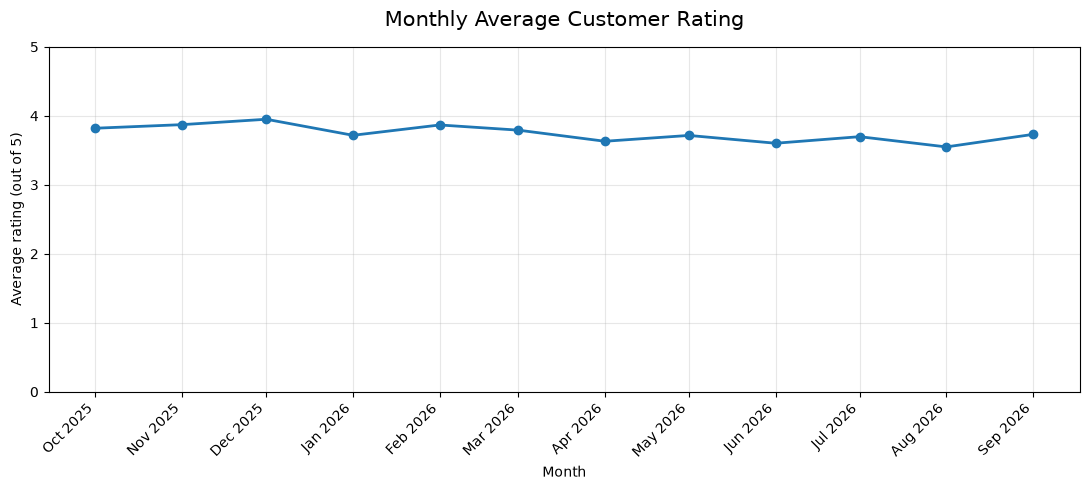

December 2025 average: 3.95
August 2026 average: 3.55


In [305]:

# Use October 2025–September 2026 for the main trend.
chart_data = monthly_summary_final.copy()

chart_data = chart_data[
    chart_data["analysis_month"].between("2025-10", "2026-09")
].copy()

chart_data["analysis_month"] = pd.to_datetime(
    chart_data["analysis_month"], format="%Y-%m"
)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    chart_data["analysis_month"],
    chart_data["average_rating"],
    marker="o",
    linewidth=2
)

ax.set_title(
    "Monthly Average Customer Rating",
    fontsize=15,
    pad=15
)
ax.set_xlabel("Month")
ax.set_ylabel("Average rating (out of 5)")
ax.set_ylim(0, 5)
ax.grid(True, alpha=0.3)

ax.set_xticks(chart_data["analysis_month"])
ax.set_xticklabels(
    chart_data["analysis_month"].dt.strftime("%b %Y"),
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

print(
    "December 2025 average:",
    round(chart_data.loc[
        chart_data["analysis_month"].dt.strftime("%Y-%m").eq("2025-12"),
        "average_rating"
    ].iloc[0], 2)
)

print(
    "August 2026 average:",
    round(chart_data.loc[
        chart_data["analysis_month"].dt.strftime("%Y-%m").eq("2026-08"),
        "average_rating"
    ].iloc[0], 2)
)

In [306]:
lowest_rated_dealers = (
    dealership_comparison_final
    .dropna(subset=["average_rating"])
    .sort_values("average_rating", ascending=True)
    .head(5)
    .copy()
)

display(
    lowest_rated_dealers[
        [
            "dealership_name",
            "average_rating",
            "feedback_count",
            "revenue_per_job"
        ]
    ].style.format({
        "average_rating": "{:.2f}",
        "feedback_count": "{:,.0f}",
        "revenue_per_job": "${:,.2f}"
    }, na_rep="Not matched")
)

,dealership_name,average_rating,feedback_count,revenue_per_job
20,Kestrel Parramatta,3.59,479,$416.02
19,Kestrel Box Hill,3.63,309,$415.01
18,Kestrel Dandenong,3.64,484,$414.41
17,Kestrel Southport,3.64,250,$420.13
16,Kestrel Essendon,3.64,346,$414.87


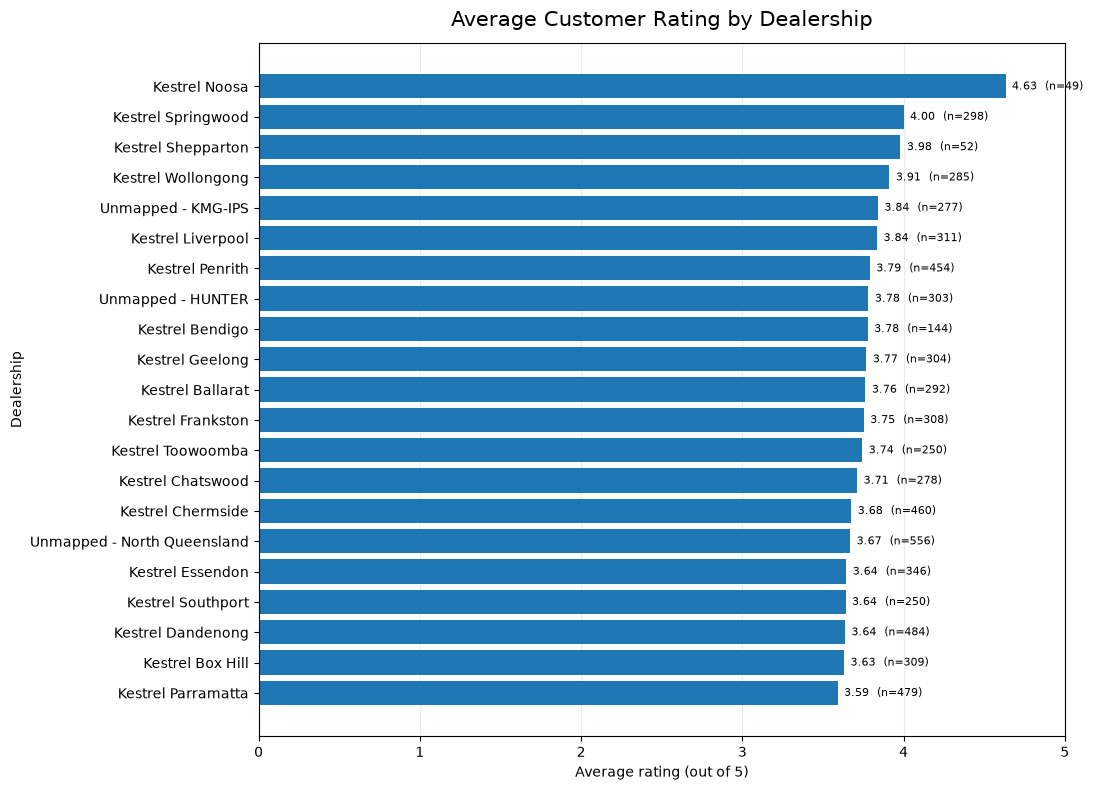

In [307]:

chart_dealers = (
    dealership_comparison_final
    .dropna(subset=["average_rating"])
    .sort_values("average_rating", ascending=True)
    .copy()
)

fig, ax = plt.subplots(figsize=(11, 8))

bars = ax.barh(
    chart_dealers["dealership_name"],
    chart_dealers["average_rating"]
)

ax.set_title("Average Customer Rating by Dealership", fontsize=15, pad=12)
ax.set_xlabel("Average rating (out of 5)")
ax.set_ylabel("Dealership")
ax.set_xlim(0, 5)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

for bar, count, rating in zip(
    bars,
    chart_dealers["feedback_count"],
    chart_dealers["average_rating"]
):
    ax.text(
        bar.get_width() + 0.04,
        bar.get_y() + bar.get_height() / 2,
        f"{rating:.2f}  (n={count:.0f})",
        va="center",
        fontsize=8
    )

plt.tight_layout()
plt.show()

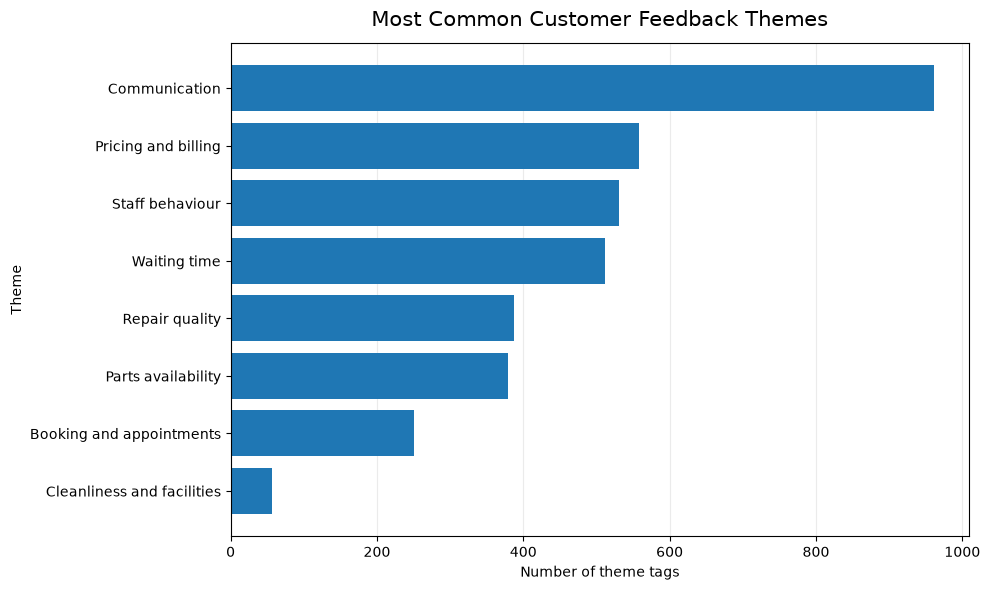

,theme,feedback_count
1,Communication,961
2,Pricing and billing,558
5,Staff behaviour,531
4,Waiting time,511
3,Repair quality,387
0,Parts availability,379
6,Booking and appointments,250
7,Cleanliness and facilities,56


In [308]:

# Parse the stored theme lists safely.
theme_counts = {}

for value in rating_analysis["themes_matched"].dropna():
    try:
        themes = ast.literal_eval(value) if isinstance(value, str) else value
        if isinstance(themes, list):
            for theme in themes:
                theme_counts[theme] = theme_counts.get(theme, 0) + 1
    except (ValueError, SyntaxError):
        continue

theme_summary_final = (
    pd.DataFrame(
        theme_counts.items(),
        columns=["theme", "feedback_count"]
    )
    .sort_values("feedback_count", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    theme_summary_final["theme"],
    theme_summary_final["feedback_count"]
)

ax.set_title("Most Common Customer Feedback Themes", fontsize=15, pad=12)
ax.set_xlabel("Number of theme tags")
ax.set_ylabel("Theme")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

display(theme_summary_final.sort_values("feedback_count", ascending=False))

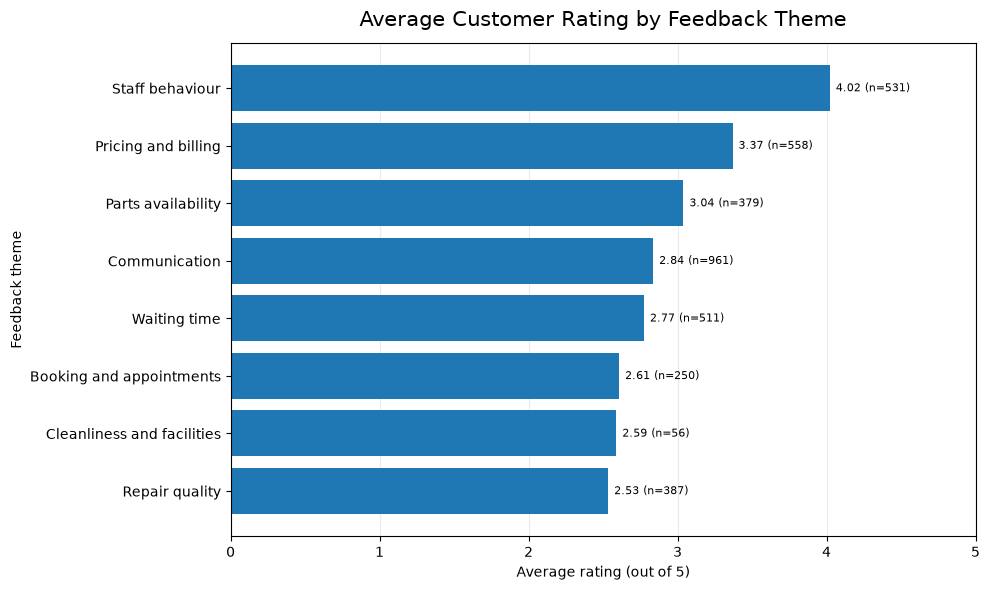

,theme,average_rating,tagged_feedback_count
5,Repair quality,2.53,387
1,Cleanliness and facilities,2.59,56
0,Booking and appointments,2.61,250
7,Waiting time,2.77,511
2,Communication,2.84,961
3,Parts availability,3.04,379
4,Pricing and billing,3.37,558
6,Staff behaviour,4.02,531


In [309]:

theme_rows = []

for _, row in rating_analysis.dropna(
    subset=["themes_matched", "rating_numeric"]
).iterrows():
    try:
        themes = (
            ast.literal_eval(row["themes_matched"])
            if isinstance(row["themes_matched"], str)
            else row["themes_matched"]
        )

        if isinstance(themes, list):
            for theme in set(themes):
                theme_rows.append({
                    "theme": theme,
                    "rating": row["rating_numeric"]
                })
    except (ValueError, SyntaxError):
        continue

theme_ratings = pd.DataFrame(theme_rows)

theme_rating_summary = (
    theme_ratings.groupby("theme")
    .agg(
        average_rating=("rating", "mean"),
        tagged_feedback_count=("rating", "count")
    )
    .reset_index()
    .sort_values("average_rating")
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    theme_rating_summary["theme"],
    theme_rating_summary["average_rating"]
)

ax.set_title("Average Customer Rating by Feedback Theme", fontsize=15, pad=12)
ax.set_xlabel("Average rating (out of 5)")
ax.set_ylabel("Feedback theme")
ax.set_xlim(0, 5)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

for bar, rating, count in zip(
    bars,
    theme_rating_summary["average_rating"],
    theme_rating_summary["tagged_feedback_count"]
):
    ax.text(
        rating + 0.04,
        bar.get_y() + bar.get_height() / 2,
        f"{rating:.2f} (n={count:,})",
        va="center",
        fontsize=8
    )

plt.tight_layout()
plt.show()

display(
    theme_rating_summary.style.format({
        "average_rating": "{:.2f}",
        "tagged_feedback_count": "{:,.0f}"
    })
)

# 8. Recommendations and Conclusion

## Executive Summary

### Key findings

**Customer ratings declined over the review period.** The average rating fell from 3.95/5 in December 2025 to 3.55/5 in August 2026, a decrease of 0.40 points. The rating recovered to 3.73/5 in September 2026, so further monitoring is needed to determine whether the decline represents a sustained trend.

**Repair quality, booking and appointments, and waiting time are the lowest-rated feedback themes.** Their average ratings were 2.53/5, 2.61/5 and 2.77/5, respectively. Communication was the most frequently tagged theme, with 961 tagged records and an average rating of 2.84/5.

**Staff behaviour is a relative strength.** It had the highest theme-level average rating at 4.02/5. Kestrel should identify and share effective staff practices while addressing the operational issues highlighted by customers.

**Some dealerships warrant closer investigation.** Among the five lowest-rated groups in the dealership comparison, Parramatta had the lowest average rating at 3.59/5, followed by Box Hill at 3.63/5. These results should be considered alongside feedback volume and dealership-specific complaint patterns.

### Recommended actions

1. Review repair quality controls and recurring repair complaints.
2. Improve booking accuracy, appointment availability and communication about delays.
3. Provide proactive updates on repair progress, costs and completion times.
4. Investigate lower-rated dealerships using recent comments and operational measures.
5. Preserve effective staff behaviours and monitor customer ratings over time.

### Data limitations

The numeric rating analysis excludes Ringwood and Tamworth because their rating mappings could not be reliably validated. Three dealership groups could not be matched to service metrics. Theme counts represent tagged records rather than necessarily unique comments, and themes can overlap. The analysis identifies associations and areas for investigation; it does not establish causation. Privacy-related redaction has been applied to a working copy, but the remaining text should still be reviewed for identifying information before wider sharing.


## Business Recommendations

Based on the customer feedback analysis, the following improvements are recommended for Kestrel Motor Group.

### 1. Improve Customer Communication

Communication and waiting-time feedback indicate opportunities to improve customer updates. Introduce proactive SMS or phone updates when repairs are delayed, parts are unavailable, or completion times change.

### 2. Reduce Waiting Times

Review appointment availability, workshop capacity and repair turnaround times at dealerships with lower customer ratings. Monitor average waiting time and the percentage of repairs completed by the promised date.

### 3. Improve Repair Quality

Investigate recurring complaints about unresolved faults and repeat repairs. Introduce consistent quality checks before vehicles are returned to customers, particularly when safety-related concerns are reported.

### 4. Improve Parts and Booking Processes

Track parts-related delays and booking availability. Notify customers promptly when parts are delayed and offer revised appointment options where possible.

### 5. Strengthen Quote Transparency

Ensure customers receive clear cost estimates and approval requests before additional work is performed. Monitor complaints about unexpected charges and differences between quoted and final costs.

### Measuring Success

Evaluate these recommendations using customer satisfaction ratings, complaint frequency, repair turnaround time, repeat-repair rates, parts delays and quote variance. Compare results before and after implementation.

### Limitations

These recommendations are based on observed feedback patterns and should be treated as improvement opportunities rather than proven causes of dissatisfaction. Sentiment analysis has limitations, and keyword-based urgency flags may miss genuine safety concerns. High-risk feedback should be reviewed by a person. The financial benefit of these recommendations cannot be reliably quantified without additional data on costs, margins, customer retention and repeat business.


In [310]:
recommendations = pd.DataFrame([
    {
        "priority": 1,
        "area": "Repair quality",
        "evidence": "Lowest average rating: 2.53/5; 387 tagged records",
        "recommended_action": "Review repeat repairs, quality checks and unresolved repair complaints.",
        "success_measure": "Average repair-quality rating; repeat-repair rate"
    },
    {
        "priority": 2,
        "area": "Booking and appointments",
        "evidence": "Average rating: 2.61/5; 250 tagged records",
        "recommended_action": "Review appointment availability, booking accuracy and missed appointments.",
        "success_measure": "Booking-related rating; missed-appointment rate"
    },
    {
        "priority": 3,
        "area": "Waiting time",
        "evidence": "Average rating: 2.77/5; 511 tagged records",
        "recommended_action": "Track delays and communicate revised completion times proactively.",
        "success_measure": "Waiting-time rating; on-time completion rate"
    },
    {
        "priority": 4,
        "area": "Communication",
        "evidence": "Most frequent theme: 961 tagged records; average rating: 2.84/5",
        "recommended_action": "Provide clearer repair updates, cost explanations and follow-up communication.",
        "success_measure": "Communication rating; update and callback compliance"
    },
    {
        "priority": 5,
        "area": "Cleanliness and facilities",
        "evidence": "Average rating: 2.59/5; 56 tagged records",
        "recommended_action": "Inspect customer areas and validate whether the low rating is consistent.",
        "success_measure": "Cleanliness rating; facility inspection results"
    },
    {
        "priority": 6,
        "area": "Staff behaviour",
        "evidence": "Highest theme average: 4.02/5; 531 tagged records",
        "recommended_action": "Identify and share effective staff practices while addressing specific complaints.",
        "success_measure": "Staff-behaviour rating; positive feedback frequency"
    }
])

display(recommendations)

,priority,area,evidence,recommended_action,success_measure
0,1,Repair quality,Lowest average rating: 2.53/5; 387 tagged records,"Review repeat repairs, quality checks and unresolved repair complaints.",Average repair-quality rating; repeat-repair rate
1,2,Booking and appointments,Average rating: 2.61/5; 250 tagged records,"Review appointment availability, booking accuracy and missed appointments.",Booking-related rating; missed-appointment rate
2,3,Waiting time,Average rating: 2.77/5; 511 tagged records,Track delays and communicate revised completion times proactively.,Waiting-time rating; on-time completion rate
3,4,Communication,Most frequent theme: 961 tagged records; average rating: 2.84/5,"Provide clearer repair updates, cost explanations and follow-up communication.",Communication rating; update and callback compliance
4,5,Cleanliness and facilities,Average rating: 2.59/5; 56 tagged records,Inspect customer areas and validate whether the low rating is consistent.,Cleanliness rating; facility inspection results
5,6,Staff behaviour,Highest theme average: 4.02/5; 531 tagged records,Identify and share effective staff practices while addressing specific complaints.,Staff-behaviour rating; positive feedback frequency


In [311]:
recommendations_final = recommendations.copy()

recommendations_final = recommendations_final.drop(
    columns=["priority"], errors="ignore"
)

recommendations_final.insert(
    0, "Priority", range(1, len(recommendations_final) + 1)
)

display(recommendations_final)

,Priority,area,evidence,recommended_action,success_measure
0,1,Repair quality,Lowest average rating: 2.53/5; 387 tagged records,"Review repeat repairs, quality checks and unresolved repair complaints.",Average repair-quality rating; repeat-repair rate
1,2,Booking and appointments,Average rating: 2.61/5; 250 tagged records,"Review appointment availability, booking accuracy and missed appointments.",Booking-related rating; missed-appointment rate
2,3,Waiting time,Average rating: 2.77/5; 511 tagged records,Track delays and communicate revised completion times proactively.,Waiting-time rating; on-time completion rate
3,4,Communication,Most frequent theme: 961 tagged records; average rating: 2.84/5,"Provide clearer repair updates, cost explanations and follow-up communication.",Communication rating; update and callback compliance
4,5,Cleanliness and facilities,Average rating: 2.59/5; 56 tagged records,Inspect customer areas and validate whether the low rating is consistent.,Cleanliness rating; facility inspection results
5,6,Staff behaviour,Highest theme average: 4.02/5; 531 tagged records,Identify and share effective staff practices while addressing specific complaints.,Staff-behaviour rating; positive feedback frequency


In [312]:
print("recommendations columns:", recommendations.columns.tolist())
print("\nrecommendations_final exists:", "recommendations_final" in globals())

if "recommendations_final" in globals():
    print("recommendations_final columns:", recommendations_final.columns.tolist())
    print("\nActual first priority value:")
    print(recommendations_final.iloc[0, 0])
    display(recommendations_final.head(2))
    

recommendations columns: ['priority', 'area', 'evidence', 'recommended_action', 'success_measure']

recommendations_final exists: True
recommendations_final columns: ['Priority', 'area', 'evidence', 'recommended_action', 'success_measure']

Actual first priority value:
1


,Priority,area,evidence,recommended_action,success_measure
0,1,Repair quality,Lowest average rating: 2.53/5; 387 tagged records,"Review repeat repairs, quality checks and unresolved repair complaints.",Average repair-quality rating; repeat-repair rate
1,2,Booking and appointments,Average rating: 2.61/5; 250 tagged records,"Review appointment availability, booking accuracy and missed appointments.",Booking-related rating; missed-appointment rate


In [313]:
print("FINAL NOTEBOOK QUALITY CHECK")
print("-" * 40)

print("1. Original dataset records:", len(feedback_analysis))
print("2. Clean rating-analysis records:", len(rating_analysis))
print("3. Missing numeric ratings in analysis:", 
      rating_analysis["rating_numeric"].isna().sum())
print("4. Original feedback data unchanged since snapshot:",
      feedback_analysis["comment"].equals(original_comments_snapshot))
print("5. Privacy working copy exists:",
      "feedback_analysis_private" in globals())
print("6. Final recommendations have priorities 1–6:",
      recommendations_final["Priority"].tolist() == list(range(1, 7)))
print("7. Dealership comparison available:",
      "dealership_comparison_final" in globals())
print("8. Monthly trend available:",
      "monthly_summary_final" in globals())
print("9. Theme summary available:",
      "theme_summary" in globals())

FINAL NOTEBOOK QUALITY CHECK
----------------------------------------
1. Original dataset records: 7086
2. Clean rating-analysis records: 6489
3. Missing numeric ratings in analysis: 0
4. Original feedback data unchanged since snapshot: True
5. Privacy working copy exists: True
6. Final recommendations have priorities 1–6: True
7. Dealership comparison available: True
8. Monthly trend available: True
9. Theme summary available: True


In [314]:
print("Department summary columns:")
print(department_summary.columns.tolist())

display(department_summary)



Department summary columns:
['department_clean', 'average_rating', 'feedback_count']


,department_clean,average_rating,feedback_count
9,Service,3.52,4325
5,SV,3.56,97
12,Workshop,3.81,293
1,P,3.93,15
2,Parts,3.94,469
3,Parts & Accessories,3.94,208
6,Sales,4.21,1170
7,Sales - New,4.22,55
8,Sales - Used,4.27,60
11,Used Cars,4.29,93


In [315]:
display(
    feedback_analysis.groupby(
        ["department", "department_clean"],
        dropna=False
    )
    .size()
    .reset_index(name="record_count")
    .sort_values(
        ["department_clean", "record_count"],
        ascending=[True, False]
    )
)

,department,department_clean,record_count
0,New Cars,New Cars,107
1,P,P,15
3,Parts,Parts,469
4,Parts & Accessories,Parts & Accessories,145
2,P&A,Parts & Accessories,36
17,parts counter,Parts & Accessories,32
5,S,S,32
7,SV,SV,97
8,Sales,Sales,1109
18,sales,Sales,76


In [316]:
ambiguous_labels = ["P", "S", "SV", "Service Dept", "Workshop"]

display(
    feedback_analysis.loc[
        feedback_analysis["department"].isin(ambiguous_labels),
        ["department", "department_clean", "dealership_clean", "comment"]
    ].head(30)
)

,department,department_clean,dealership_clean
1582,Workshop,Workshop,Kestrel Frankston
1589,Workshop,Workshop,Kestrel Frankston
1596,Workshop,Workshop,Kestrel Frankston
1609,Workshop,Workshop,Kestrel Frankston
1624,Workshop,Workshop,Kestrel Frankston
1631,Workshop,Workshop,Kestrel Frankston
1662,Workshop,Workshop,Kestrel Frankston
1664,Workshop,Workshop,Kestrel Frankston
1673,Workshop,Workshop,Kestrel Frankston
1674,Workshop,Workshop,Kestrel Frankston


In [317]:
department_negative = (
    rating_analysis
    .assign(
        negative_feedback=lambda df: df["rating_numeric"] <= 2
    )
    .groupby("department_clean", dropna=False)
    .agg(
        feedback_count=("rating_numeric", "count"),
        average_rating=("rating_numeric", "mean"),
        negative_count=("negative_feedback", "sum"),
        negative_rate=("negative_feedback", "mean")
    )
    .reset_index()
)

department_negative["negative_rate_pct"] = (
    department_negative["negative_rate"] * 100
).round(1)

display(
    department_negative.sort_values(
        ["negative_rate_pct", "feedback_count"],
        ascending=[False, False]
    )
)

,department_clean,feedback_count,average_rating,negative_count,negative_rate,negative_rate_pct
9,Service,4067,3.534300,1139,0.280059,28.0
5,SV,97,3.556701,25,0.257732,25.8
12,Workshop,242,3.809917,53,0.219008,21.9
1,P,15,3.933333,3,0.200000,20.0
7,Sales - New,55,4.218182,9,0.163636,16.4
2,Parts,461,3.943601,74,0.160521,16.1
3,Parts & Accessories,181,4.005525,29,0.160221,16.0
6,Sales,1110,4.200000,131,0.118018,11.8
8,Sales - Used,60,4.266667,7,0.116667,11.7
11,Used Cars,68,4.264706,7,0.102941,10.3


In [318]:
print("Dealership comparison shape:", dealership_comparison_final.shape)

display(
    dealership_comparison_final[
        [
            "dealership_name",
            "average_rating",
            "feedback_count",
            "total_service_jobs",
            "total_service_revenue"
        ]
    ].head(10)
)

Dealership comparison shape: (21, 6)


,dealership_name,average_rating,feedback_count,total_service_jobs,total_service_revenue
0,Kestrel Noosa,4.632653,49,4108.0,1723390.0
1,Kestrel Springwood,4.000000,298,7731.0,3223190.0
2,Kestrel Shepparton,3.980769,52,1928.0,800170.0
3,Kestrel Wollongong,3.912281,285,7635.0,3192530.0
4,Unmapped - KMG-IPS,3.841155,277,NaN,NaN
5,Kestrel Liverpool,3.836013,311,7654.0,3151070.0
6,Kestrel Penrith,3.790749,454,12789.0,5291440.0
7,Unmapped - HUNTER,3.782178,303,NaN,NaN
8,Kestrel Bendigo,3.777778,144,4111.0,1707520.0
9,Kestrel Geelong,3.769737,304,7829.0,3243440.0
